# 09 · 苍穹外卖：订单管理

来源：`D:/baidudisk/BaiduNetdiskDownload/资料.rar` 中的 `资料/day09/项目实战参考答案/项目实战参考答案.md`、`资料/day09/项目实战要求.md`、`项目接口文档/苍穹外卖-用户端接口.html`、`项目接口文档/苍穹外卖-管理端接口.html` 和 `产品原型.zip`。整理日期：2026-10-09。

本章覆盖用户端的4项功能、商家端的8项功能，以及用户下单时的五公里配送范围校验。参考答案的43段Java/XML代码和35张实际引用配图按原文保留；实战要求原文、接口路线、补充说明和13份功能验收矩阵分开标注，便于边看答案边检查工程实现。附图内嵌到本笔记，可离线阅读。

本章沿用前面章节的 `Orders` 状态：1待付款、2待接单、3已接单、4派送中、5已完成、6已取消。状态按钮只是入口，服务端仍要校验当前状态、订单归属、支付状态和操作幂等性。参考代码中的固定退款金额、按订单 id 直接查询、重复插入购物车和逐单查询明细都需要在跟练时补齐。

接口文档和产品原型只作为本章设计依据，未启动后端、未访问百度地图或微信支付、未执行真实退款。示例中的百度地图 AK、商户支付参数和地址均应由你自己的受控配置提供。


## 本章路线、接口和状态流转（补充）

### 用户端接口速查

| 功能 | 方法与路径 | 关键校验 |
| --- | --- | --- |
| 历史订单 | `GET /user/order/historyOrders?page=&pageSize=&status=` | page/pageSize范围、status枚举、当前用户 |
| 订单详情 | `GET /user/order/orderDetail/{id}` | 订单必须属于当前用户 |
| 用户取消 | `PUT /user/order/cancel/{id}` | 只允许待付款/待接单，退款按支付状态处理 |
| 再来一单 | `POST /user/order/repetition/{id}` | 校验归属、商品可售、规格有效，购物车写入幂等 |

### 商家端接口速查

| 功能 | 方法与路径 | 关键校验 |
| --- | --- | --- |
| 条件搜索 | `GET /admin/order/conditionSearch` | 订单号/手机号模糊、状态和时间范围、分页 |
| 状态统计 | `GET /admin/order/statistics` | 明确统计状态，空结果返回0 |
| 订单详情 | `GET /admin/order/details/{id}` | 订单存在，明细一次或批量读取 |
| 接单 | `PUT /admin/order/confirm` | 仅待接单→已接单 |
| 拒单 | `PUT /admin/order/rejection` | 仅待接单，保存原因，已支付则退款 |
| 商家取消 | `PUT /admin/order/cancel` | 保存原因和时间，支付状态决定退款 |
| 派送 | `PUT /admin/order/delivery/{id}` | 仅已接单→派送中 |
| 完成 | `PUT /admin/order/complete/{id}` | 仅派送中→已完成 |

### 订单状态图

```text
待付款(1) --支付成功--> 待接单(2) --接单--> 已接单(3)
                                           |
                                         派送
                                           v
                                       派送中(4) --完成--> 已完成(5)

待付款/待接单 --用户取消--> 已取消(6)
待接单 --商家拒单/取消--> 已取消(6)
```

状态转换必须由服务端以“当前状态=预期状态”的条件更新完成，例如接单使用 `where id = ? and status = 2`，并检查影响行数。已经完成或已经取消的订单再次点击按钮应返回明确业务结果，不应被无条件覆盖。

### 关联、身份和工程依赖

`orders.id`是订单主键，`order_detail.order_id`关联它；`orders.number`是商户订单号，用于支付与退款关联；`orders.amount`是整单金额，`order_detail.amount`是商品单价，行金额还要乘number。`shopping_cart`保存当前待结算商品，不能直接当作历史账单。

本章需要沿用第08章的Orders、OrderDetail、订单update方法与XML，以及第07章ShoppingCart与Mapper。补齐OrdersPageQueryDTO的分页、number、phone、status、userId、beginTime/endTime；OrderVO在Orders信息上增加orderDetailList和orderDishes；OrderStatisticsVO包含toBeConfirmed、confirmed、deliveryInProgress。三个操作DTO分别接收id、id+rejectionReason、id+cancelReason，不能直接用Orders接收客户端全部状态字段。

管理端DTO会绑定Query参数，Service应白名单使用搜索条件。用户端userId只由已验证的BaseContext提供。管理端使用token请求头，用户端使用authentication，Controller需要显式区分Bean名称，如adminOrderController/userOrderController，避免两个同名类的Bean冲突。

| 字段 | 含义 |
| --- | --- |
| orders.status | 订单业务状态1～6，与上图相同 |
| orders.pay_status | 课程中0未支付、1已支付、2退款；不足以单独描述退款申请中/成功/失败 |
| Orders.CONFIRMED | 已接单；管理列表将其称为“待派送” |
| Orders.deliveryTime | 原完成代码写入的实际送达时间，不能误当成派送开始时间 |


## 项目实战要求（资料原文）

### 实战内容

完成用户端历史订单模块、商家端订单管理模块相关业务新功能开发和已有功能优化，具体任务列表如下：

#### 1. 新功能开发

用户端历史订单模块：

- 查询历史订单
- 查询订单详情
- 取消订单
- 再来一单

商家端订单管理模块：

- 订单搜索
- 各个状态的订单数量统计
- 查询订单详情
- 接单
- 拒单
- 取消订单
- 派送订单
- 完成订单

#### 2. 已有功能优化

优化用户下单功能，加入校验逻辑，如果用户的收货地址距离商家门店超出配送范围（配送范围为5公里内），则下单失败。

提示：

​	1. 基于百度地图开放平台实现（https://lbsyun.baidu.com/）

​	2. 注册账号--->创建应用获取AK(服务端应用)--->调用接口

 3. 相关接口

    https://lbsyun.baidu.com/index.php?title=webapi/guide/webservice-geocoding

    https://lbsyun.baidu.com/index.php?title=webapi/directionlite-v1

 4. 商家门店地址可以配置在配置文件中，例如：

    ~~~yaml
    sky:
      shop:
        address: 北京市海淀区上地十街10号
    ~~~

    

### 实战要求

1. 根据产品原型进行需求分析和接口设计
4. 根据接口设计进行代码实现
5. 分别通过swagger接口文档和前后端联调进行功能测试
4. 分组实战（具体任务分工由组长分配）


## 类型与更新依赖（资料补全）

以下七段摘自同一资料包的 `资料/day12/项目完整版代码/sky-take-out`，用来补齐day09答案引用但未完整展示的DTO/VO和订单更新XML。它们不属于day09原答案的43段代码，独立标注并核对来源；按当前工程合并，不要整套导入后续功能。

分页DTO的日期格式是 `yyyy-MM-dd HH:mm:ss`，Query里的空格应URL编码；字段默认0不是合法分页参数。操作DTO没有校验注解，仍需服务端检查id和原因。OrderVO继承Orders，补充明细列表和商品展示字符串。

订单update原文只按id更新，因此后面的状态迁移勘误增加条件更新。下列XML放入已有OrderMapper.xml；Mapper接口保留当前update声明，并按补充设计专用返回int的方法，勿把整个XML复制到另一namespace。

### OrdersPageQueryDTO

资料位置：`sky-pojo/src/main/java/com/sky/dto/OrdersPageQueryDTO.java`。

```java
package com.sky.dto;

import lombok.Data;
import org.springframework.format.annotation.DateTimeFormat;

import java.io.Serializable;
import java.time.LocalDateTime;

@Data
public class OrdersPageQueryDTO implements Serializable {

    private int page;

    private int pageSize;

    private String number;

    private  String phone;

    private Integer status;

    @DateTimeFormat(pattern = "yyyy-MM-dd HH:mm:ss")
    private LocalDateTime beginTime;

    @DateTimeFormat(pattern = "yyyy-MM-dd HH:mm:ss")
    private LocalDateTime endTime;

    private Long userId;

}
```

### OrdersConfirmDTO

资料位置：`sky-pojo/src/main/java/com/sky/dto/OrdersConfirmDTO.java`。

```java
package com.sky.dto;

import lombok.Data;

import java.io.Serializable;

@Data
public class OrdersConfirmDTO implements Serializable {

    private Long id;
    //订单状态 1待付款 2待接单 3 已接单 4 派送中 5 已完成 6 已取消 7 退款
    private Integer status;

}
```

### OrdersRejectionDTO

资料位置：`sky-pojo/src/main/java/com/sky/dto/OrdersRejectionDTO.java`。

```java
package com.sky.dto;

import lombok.Data;

import java.io.Serializable;

@Data
public class OrdersRejectionDTO implements Serializable {

    private Long id;

    //订单拒绝原因
    private String rejectionReason;

}
```

### OrdersCancelDTO

资料位置：`sky-pojo/src/main/java/com/sky/dto/OrdersCancelDTO.java`。

```java
package com.sky.dto;

import lombok.Data;

import java.io.Serializable;

@Data
public class OrdersCancelDTO implements Serializable {

    private Long id;
    //订单取消原因
    private String cancelReason;

}
```

### OrderVO

资料位置：`sky-pojo/src/main/java/com/sky/vo/OrderVO.java`。

```java
package com.sky.vo;

import com.sky.entity.OrderDetail;
import com.sky.entity.Orders;
import lombok.AllArgsConstructor;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.io.Serializable;
import java.util.List;

@Data
@NoArgsConstructor
@AllArgsConstructor
public class OrderVO extends Orders implements Serializable {

    //订单菜品信息
    private String orderDishes;

    //订单详情
    private List<OrderDetail> orderDetailList;

}
```

### OrderStatisticsVO

资料位置：`sky-pojo/src/main/java/com/sky/vo/OrderStatisticsVO.java`。

```java
package com.sky.vo;

import lombok.Data;
import java.io.Serializable;

@Data
public class OrderStatisticsVO implements Serializable {
    //待接单数量
    private Integer toBeConfirmed;

    //待派送数量
    private Integer confirmed;

    //派送中数量
    private Integer deliveryInProgress;
}
```

### OrderMapper.xml的update

资料位置：`sky-server/src/main/resources/mapper/OrderMapper.xml`。

```xml
    <update id="update" parameterType="com.sky.entity.Orders">
        update orders
        <set>
            <if test="cancelReason != null and cancelReason!='' ">
                cancel_reason=#{cancelReason},
            </if>
            <if test="rejectionReason != null and rejectionReason!='' ">
                rejection_reason=#{rejectionReason},
            </if>
            <if test="cancelTime != null">
                cancel_time=#{cancelTime},
            </if>
            <if test="payStatus != null">
                pay_status=#{payStatus},
            </if>
            <if test="payMethod != null">
                pay_method=#{payMethod},
            </if>
            <if test="checkoutTime != null">
                checkout_time=#{checkoutTime},
            </if>
            <if test="status != null">
                status = #{status},
            </if>
            <if test="deliveryTime != null">
                delivery_time = #{deliveryTime}
            </if>
        </set>
        where id = #{id}
    </update>
```

同一完整版Orders实体的状态常量只有1～6，其status字段旧注释还写了“7退款”，与常量、day09规则不一致；本笔记按1～6订单状态和0/1/2支付状态讲解，不新增状态7。实体没有confirmTime，deliveryTime注明“送达时间”，对应原完成操作，不能直接执行引用未建字段的SQL。


# 用户端历史订单模块


## 1. 查询历史订单


### 1.1 需求分析和设计

产品原型：

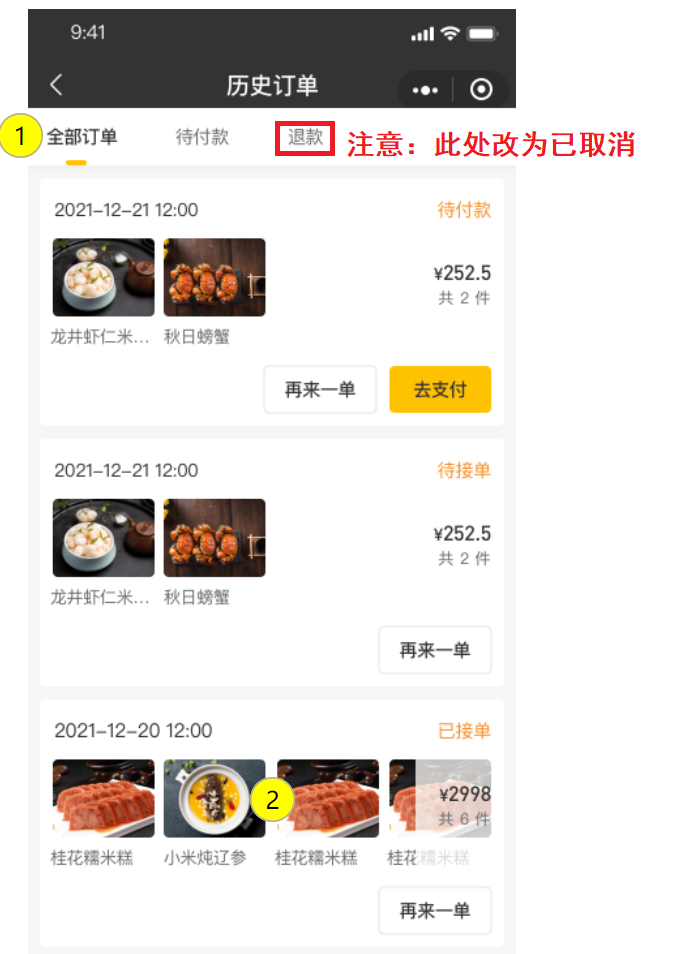

业务规则

- 分页查询历史订单
- 可以根据订单状态查询
- 展示订单数据时，需要展示的数据包括：下单时间、订单状态、订单金额、订单明细（商品名称、图片）

接口设计：参见接口文档

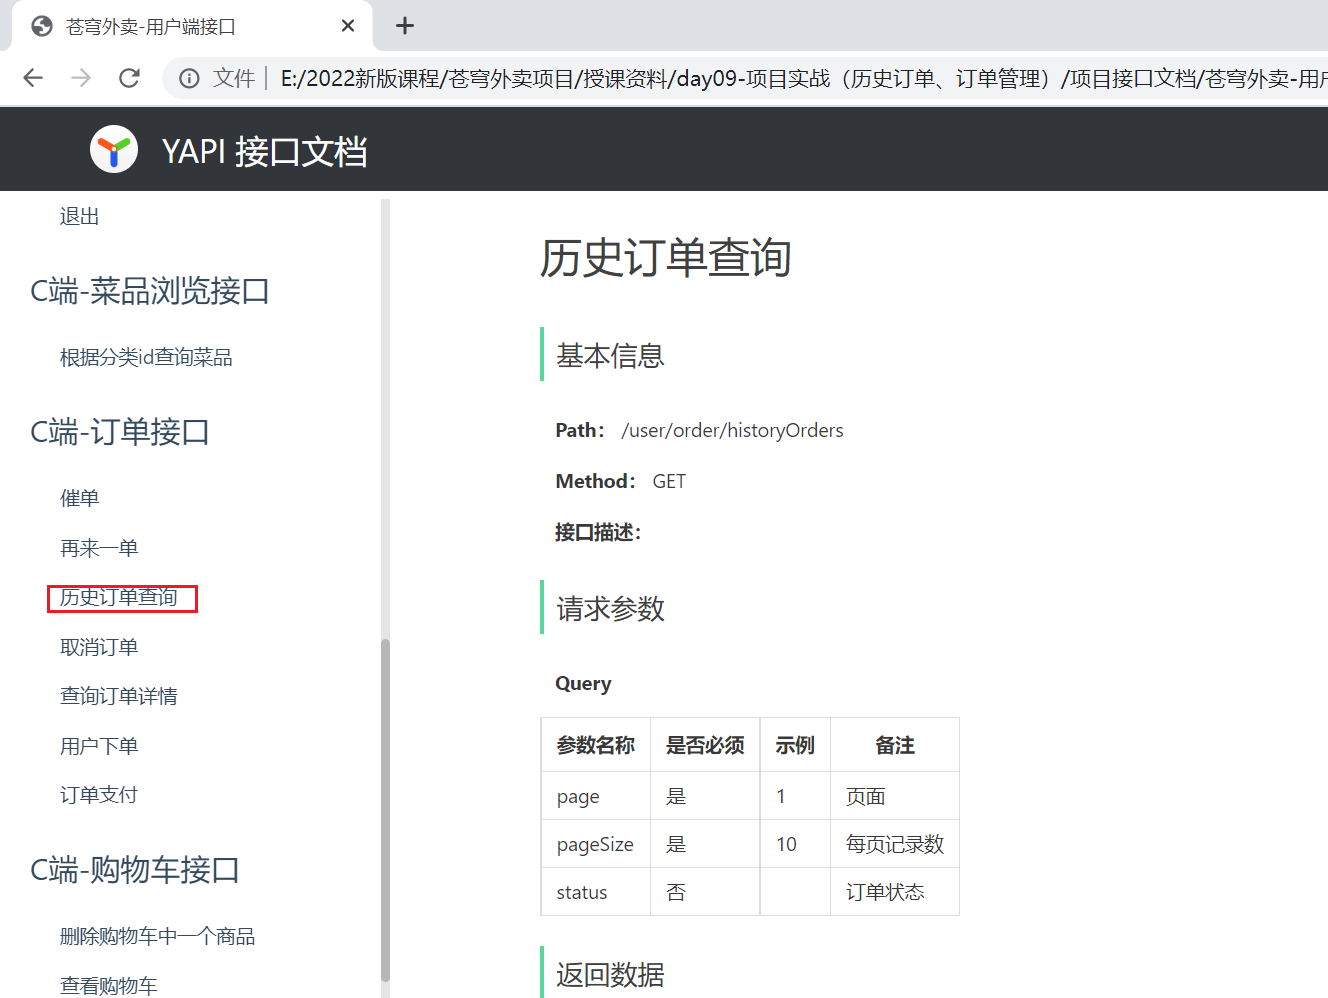


### 历史订单查询的边界（补充）

历史订单列表应只属于当前登录用户，状态筛选只能接受 1～6 或明确的空值。分页参数不能直接交给 PageHelper：页码小于1、页大小过大、status非法都应在 Controller 或 Service 层拒绝。订单主表分页后再查明细是课程写法，数据量变大时应改成批量查询并按订单 id 分组。

页面展示的金额、下单时间和订单明细来自订单快照。不要在展示历史订单时重新查询当前商品价格或当前地址，否则历史记录会随商品调整而变化。


### 1.2 代码实现

#### 1.2.1 user/OrderController

~~~java
    /**
     * 历史订单查询
     *
     * @param page
     * @param pageSize
     * @param status   订单状态 1待付款 2待接单 3已接单 4派送中 5已完成 6已取消
     * @return
     */
    @GetMapping("/historyOrders")
    @ApiOperation("历史订单查询")
    public Result<PageResult> page(int page, int pageSize, Integer status) {
        PageResult pageResult = orderService.pageQuery4User(page, pageSize, status);
        return Result.success(pageResult);
    }
~~~

#### 1.2.2 OrderService

~~~java
    /**
     * 用户端订单分页查询
     * @param page
     * @param pageSize
     * @param status
     * @return
     */
    PageResult pageQuery4User(int page, int pageSize, Integer status);
~~~

#### 1.2.3 OrderServiceImpl

~~~java
/**
     * 用户端订单分页查询
     *
     * @param pageNum
     * @param pageSize
     * @param status
     * @return
     */
    public PageResult pageQuery4User(int pageNum, int pageSize, Integer status) {
        // 设置分页
        PageHelper.startPage(pageNum, pageSize);

        OrdersPageQueryDTO ordersPageQueryDTO = new OrdersPageQueryDTO();
        ordersPageQueryDTO.setUserId(BaseContext.getCurrentId());
        ordersPageQueryDTO.setStatus(status);

        // 分页条件查询
        Page<Orders> page = orderMapper.pageQuery(ordersPageQueryDTO);

        List<OrderVO> list = new ArrayList();

        // 查询出订单明细，并封装入OrderVO进行响应
        if (page != null && page.getTotal() > 0) {
            for (Orders orders : page) {
                Long orderId = orders.getId();// 订单id

                // 查询订单明细
                List<OrderDetail> orderDetails = orderDetailMapper.getByOrderId(orderId);

                OrderVO orderVO = new OrderVO();
                BeanUtils.copyProperties(orders, orderVO);
                orderVO.setOrderDetailList(orderDetails);

                list.add(orderVO);
            }
        }
        return new PageResult(page.getTotal(), list);
    }
~~~

#### 1.2.4 OrderMapper

~~~java
    /**
     * 分页条件查询并按下单时间排序
     * @param ordersPageQueryDTO
     */
    Page<Orders> pageQuery(OrdersPageQueryDTO ordersPageQueryDTO);
~~~

#### 1.2.5 OrderMapper.xml

~~~xml
	<select id="pageQuery" resultType="Orders">
        select * from orders
        <where>
            <if test="number != null and number!=''">
                and number like concat('%',#{number},'%')
            </if>
            <if test="phone != null and phone!=''">
                and phone like concat('%',#{phone},'%')
            </if>
            <if test="userId != null">
                and user_id = #{userId}
            </if>
            <if test="status != null">
                and status = #{status}
            </if>
            <if test="beginTime != null">
                and order_time &gt;= #{beginTime}
            </if>
            <if test="endTime != null">
                and order_time &lt;= #{endTime}
            </if>
        </where>
        order by order_time desc
    </select>
~~~

#### 1.2.6 OrderDetailMapper

~~~java
    /**
     * 根据订单id查询订单明细
     * @param orderId
     * @return
     */
    @Select("select * from order_detail where order_id = #{orderId}")
    List<OrderDetail> getByOrderId(Long orderId);
~~~


### 当前用户、分页和 N+1 查询（勘误）

原代码虽然把 `BaseContext.getCurrentId()` 写进 `OrdersPageQueryDTO`，但仍需要先确认身份不为空，再校验 page、pageSize 和 status。Mapper 的查询条件应始终包含 `user_id = #{userId}`，不能因为身份缺失而动态省略条件。

`PageHelper.startPage`后紧接订单主表查询，拿到本页后再装配明细。分页总数取page.getTotal，不能用本页list.size替代；原代码即使写了page!=null判断，最后仍调用page.getTotal，Mapper异常不应伪装成空页。raw `new ArrayList()`改为`new ArrayList<>()`可消除泛型警告。

每个订单调用一次 `orderDetailMapper.getByOrderId` 会产生 N+1 查询。课程规模可以先这样跟练；生产实现可按本页订单 id 批量查询明细，再使用 `Map<Long,List<OrderDetail>>` 组装 `OrderVO`。


### 1.3 功能测试

略


### 历史订单验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 不同状态、不同页码查询 | 总数和当前页准确，订单按下单时间倒序 |
| 用户A查询用户B的订单 | 返回空或无权错误，不能泄露明细 |
| status为空/1～6/非法值 | 空值查全部允许状态，合法值筛选，非法值拒绝 |
| page=0、pageSize超上限 | 参数校验失败，不访问全表 |
| 一页多个订单 | 明细完整且没有串单 |
| 订单无明细 | 返回空列表，不抛出空指针 |


## 2. 查询订单详情


### 2.1 需求分析和设计

产品原型：

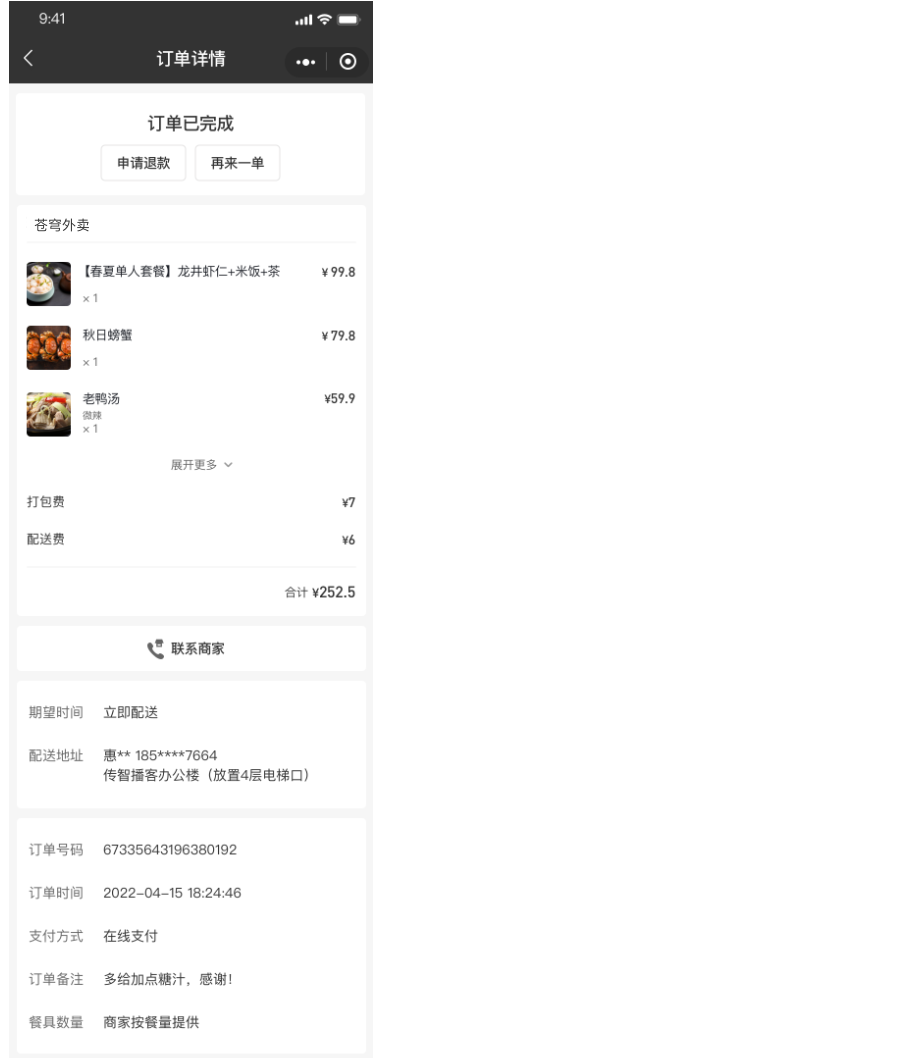


接口设计：参见接口文档

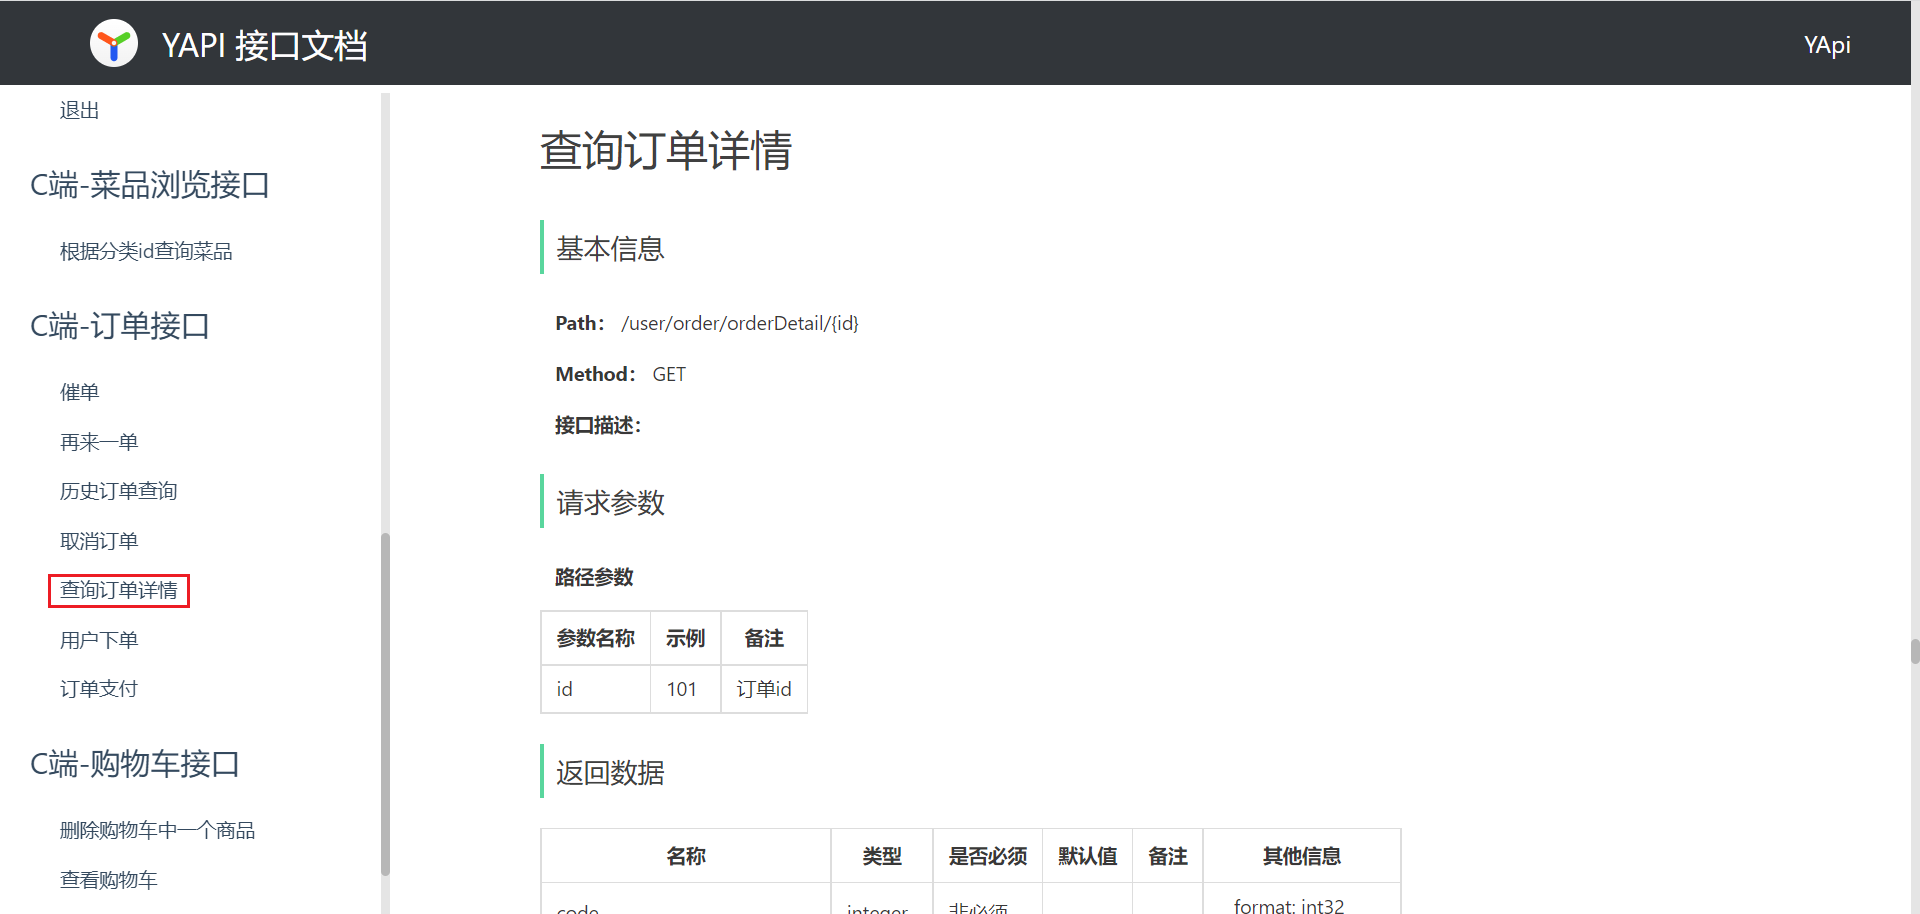


### 详情接口必须检查归属（补充）

订单详情中的 `id` 是数据库主键，不能作为授权依据。Controller 只负责接收参数，Service 应使用当前用户 id 查询 `where id = ? and user_id = ?` 的订单，再读取明细；查询不到时统一返回不存在或无权访问。订单快照中的收货地址、联系人和商品行应直接展示。


### 2.2 代码实现

#### 2.2.1 user/OrderController

~~~java
    /**
     * 查询订单详情
     *
     * @param id
     * @return
     */
    @GetMapping("/orderDetail/{id}")
    @ApiOperation("查询订单详情")
    public Result<OrderVO> details(@PathVariable("id") Long id) {
        OrderVO orderVO = orderService.details(id);
        return Result.success(orderVO);
    }
~~~

#### 2.2.2 OrderService

~~~java
    /**
     * 查询订单详情
     * @param id
     * @return
     */
    OrderVO details(Long id);
~~~

#### 2.2.3 OrderServiceImpl

~~~java
    /**
     * 查询订单详情
     *
     * @param id
     * @return
     */
    public OrderVO details(Long id) {
        // 根据id查询订单
        Orders orders = orderMapper.getById(id);

        // 查询该订单对应的菜品/套餐明细
        List<OrderDetail> orderDetailList = orderDetailMapper.getByOrderId(orders.getId());

        // 将该订单及其详情封装到OrderVO并返回
        OrderVO orderVO = new OrderVO();
        BeanUtils.copyProperties(orders, orderVO);
        orderVO.setOrderDetailList(orderDetailList);

        return orderVO;
    }
~~~

#### 2.2.4 OrderMapper

~~~java
    /**
     * 根据id查询订单
     * @param id
     */
    @Select("select * from orders where id=#{id}")
    Orders getById(Long id);
~~~


### 防止越权查看订单（勘误）

参考实现先执行 `orderMapper.getById(id)`，任何登录用户只要猜到 id 就可能读取他人订单。新增 `getByIdAndUserId(id, userId)`，并在 Service 开头拒绝缺失身份；`orders == null` 时不要继续调用 `orders.getId()`。明细查询也只能在订单归属确认后进行。

可加入OrderMapper（补充示例，需导入MyBatis的Select和Param）：

```java
@Select("select * from orders where id = #{id} and user_id = #{userId}")
Orders getByIdAndUserId(@Param("id") Long id,
                        @Param("userId") Long userId);
```

Service封装一处用户订单授权校验：

```java
private Orders requireOwnedOrder(Long id) {
    Long userId = BaseContext.getCurrentId();
    if (userId == null || userId <= 0) {
        throw new IllegalStateException("缺少当前登录用户");
    }
    if (id == null || id <= 0) {
        throw new IllegalArgumentException("订单id不合法");
    }
    Orders order = orderMapper.getByIdAndUserId(id, userId);
    if (order == null) {
        throw new OrderBusinessException(MessageConstant.ORDER_NOT_FOUND);
    }
    return order;
}
```

用户details、userCancelById、repetition先调用此方法；管理端details仍用管理员授权后的查单逻辑。实际异常接入项目统一异常处理器。

详情接口不应接受前端传入的 userId，也不应把“管理员能看全部订单”和“用户端能看全部订单”混在一个 Mapper 方法里。管理端详情可单独使用不带 user_id 的方法，并由管理端鉴权保护。


### 2.3 功能测试

略


### 详情验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 查看自己的有效订单 | 返回订单快照和完整明细 |
| 查看不存在 id | 业务错误或404，不出现空指针 |
| 查看他人订单 | 拒绝且不返回商品、地址、手机号 |
| 无登录身份调用 | 拒绝，不执行无条件按 id 查询 |
| 明细被删除或为空 | 返回空明细列表并记录数据异常 |


## 3. 取消订单


### 3.1 需求分析和设计

产品原型：

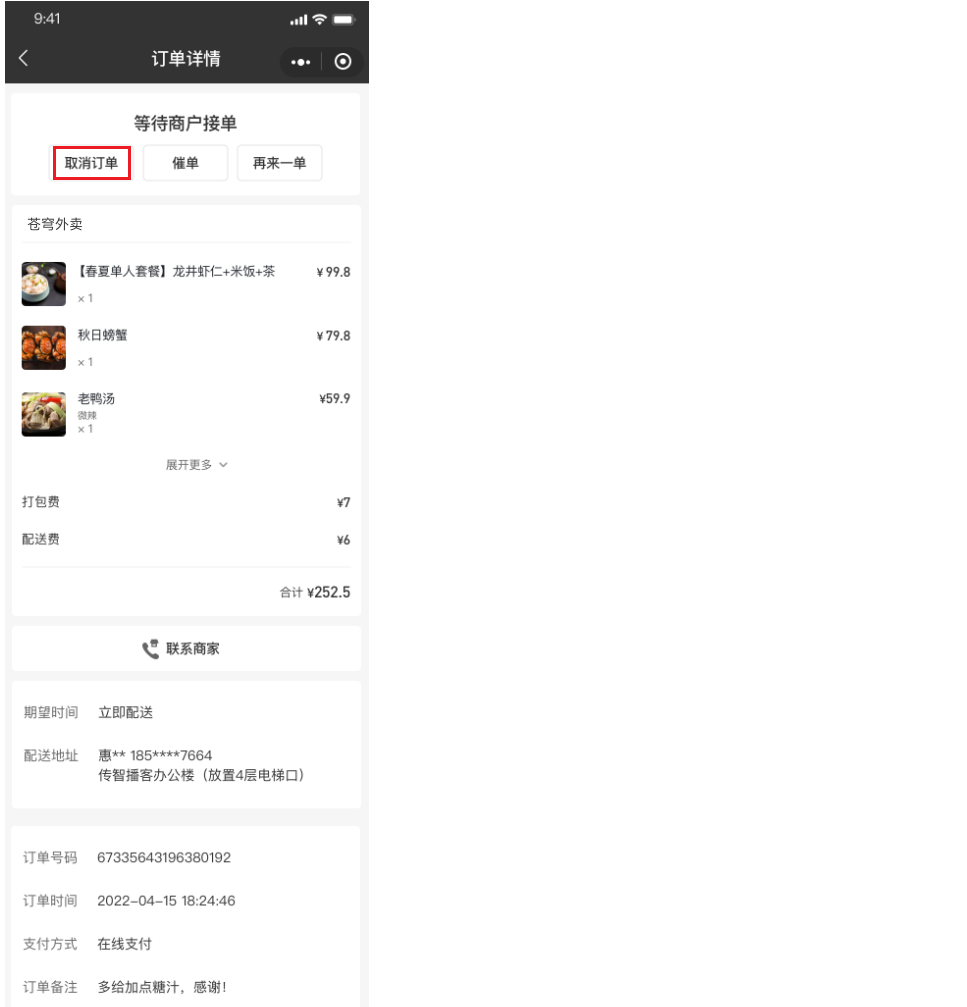

业务规则：

- 待支付和待接单状态下，用户可直接取消订单
- 商家已接单状态下，用户取消订单需电话沟通商家
- 派送中状态下，用户取消订单需电话沟通商家
- 如果在待接单状态下取消订单，需要给用户退款
- 取消订单后需要将订单状态修改为“已取消”

接口设计：参见接口文档

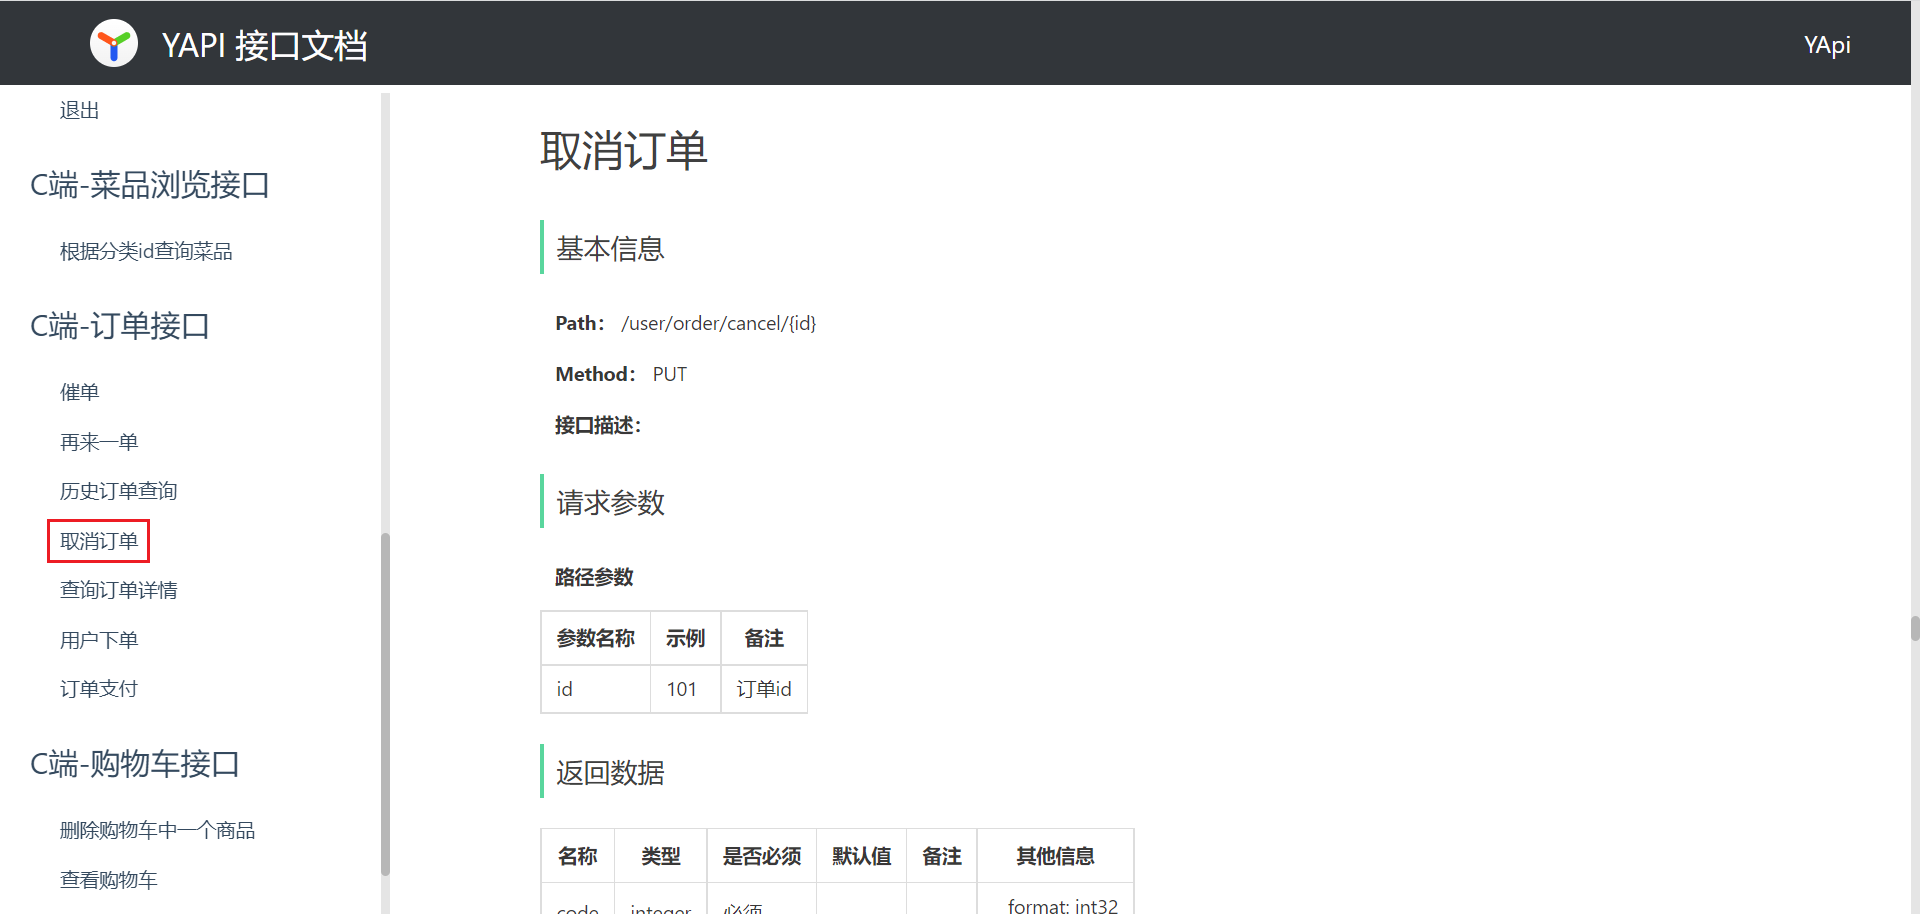


### 取消订单要区分状态与支付（补充）

待付款取消不需要退款；已支付且待接单取消需要按订单实际支付金额申请退款；已接单或派送中是否允许取消，应遵循产品规则并通常转人工。状态和支付状态是两个字段，不能看到 `status <= 2` 就统一执行退款。


### 3.2 代码实现

#### 3.2.1 user/OrderController

~~~java
    /**
     * 用户取消订单
     *
     * @return
     */
    @PutMapping("/cancel/{id}")
    @ApiOperation("取消订单")
    public Result cancel(@PathVariable("id") Long id) throws Exception {
        orderService.userCancelById(id);
        return Result.success();
    }
~~~

#### 3.2.2 OrderService

~~~java
    /**
     * 用户取消订单
     * @param id
     */
    void userCancelById(Long id) throws Exception;
~~~

#### 3.2.3 OrderServiceImpl

~~~java
	/**
     * 用户取消订单
     *
     * @param id
     */
    public void userCancelById(Long id) throws Exception {
        // 根据id查询订单
        Orders ordersDB = orderMapper.getById(id);

        // 校验订单是否存在
        if (ordersDB == null) {
            throw new OrderBusinessException(MessageConstant.ORDER_NOT_FOUND);
        }

        //订单状态 1待付款 2待接单 3已接单 4派送中 5已完成 6已取消
        if (ordersDB.getStatus() > 2) {
            throw new OrderBusinessException(MessageConstant.ORDER_STATUS_ERROR);
        }

        Orders orders = new Orders();
        orders.setId(ordersDB.getId());

        // 订单处于待接单状态下取消，需要进行退款
        if (ordersDB.getStatus().equals(Orders.TO_BE_CONFIRMED)) {
            //调用微信支付退款接口
            weChatPayUtil.refund(
                    ordersDB.getNumber(), //商户订单号
                    ordersDB.getNumber(), //商户退款单号
                    new BigDecimal(0.01),//退款金额，单位 元
                    new BigDecimal(0.01));//原订单金额

            //支付状态修改为 退款
            orders.setPayStatus(Orders.REFUND);
        }

        // 更新订单状态、取消原因、取消时间
        orders.setStatus(Orders.CANCELLED);
        orders.setCancelReason("用户取消");
        orders.setCancelTime(LocalDateTime.now());
        orderMapper.update(orders);
    }
~~~


### 固定 0.01 元退款是危险示例（勘误）

参考答案把退款金额和原订单金额写成 `new BigDecimal(0.01)`，只能作为课堂占位，不能进入真实业务。应从已支付订单读取服务端保存的金额，使用明确的退款单号，并记录退款请求号和结果；微信退款是远程调用，需要超时、重试和幂等设计。

`new BigDecimal(0.01)`还会继承double二进制误差；业务金额直接使用已核定的BigDecimal，教学固定值也应写`new BigDecimal("0.01")`。如果第08章真的只付了测试一分钱，退款必须以支付记录中的实付金额核对，不能仅把本章参数改成订单显示金额就认为正确。全额退款以原实付额为准；部分退款需要单独的退款流水号并累计校验不超实付额。

更新订单时使用条件更新，例如 `where id = ? and user_id = ? and status = 2 and pay_status = 1`，检查影响行数。原`status > 2`不是完整白名单，非法0、负数或null也要拒绝。退款接口返回申请受理，不必然表示用户已收到款；原用户取消直接设置REFUND，而拒单和商家取消没有设置payStatus，两者口径并不一致。

把订单取消和退款任务/流水在本地事务中持久化，再由退款适配器执行和查询，用已保存退款号重试；回调/主动查询核实到账后记录结果。状态机、重试和对账处理远程超时，本地@Transactional不能回滚微信已经执行的退款。已付款通知与取消同时发生也需原子状态迁移和补偿，不能只依赖前端操作顺序。


### 3.3 功能测试

略


### 用户取消验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 待付款取消 | 状态变为已取消，不调用退款 |
| 已支付待接单取消 | 退款金额等于订单实际金额，记录退款结果 |
| 已接单/派送中取消 | 按产品规则拒绝或进入人工流程 |
| 重复点击取消 | 幂等返回，不重复退款 |
| 用户A取消用户B订单 | 拒绝，订单状态不变 |
| 退款接口超时 | 保存处理中状态并可重试，对账可恢复 |


## 4. 再来一单


### 4.1 需求分析和设计

产品原型：

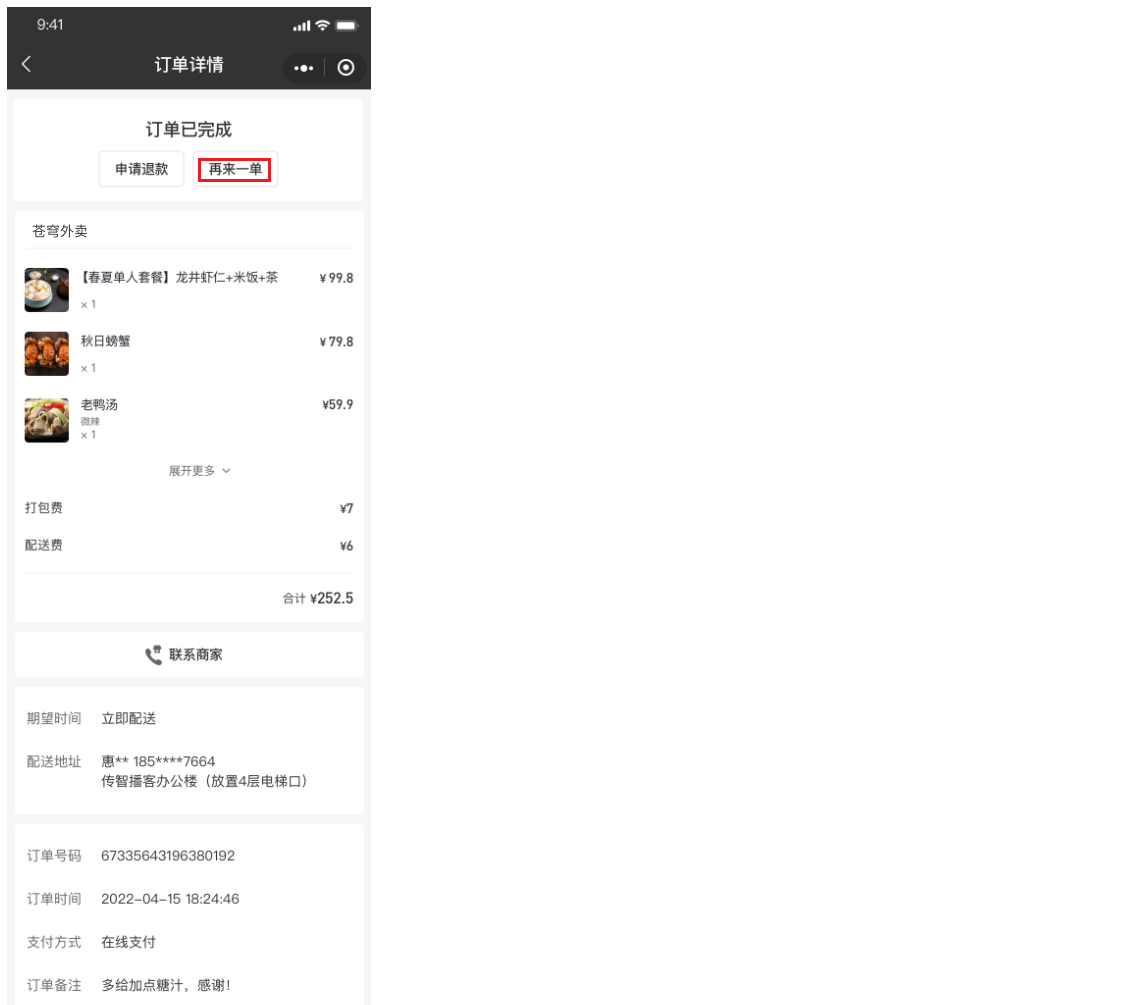

接口设计：参见接口文档

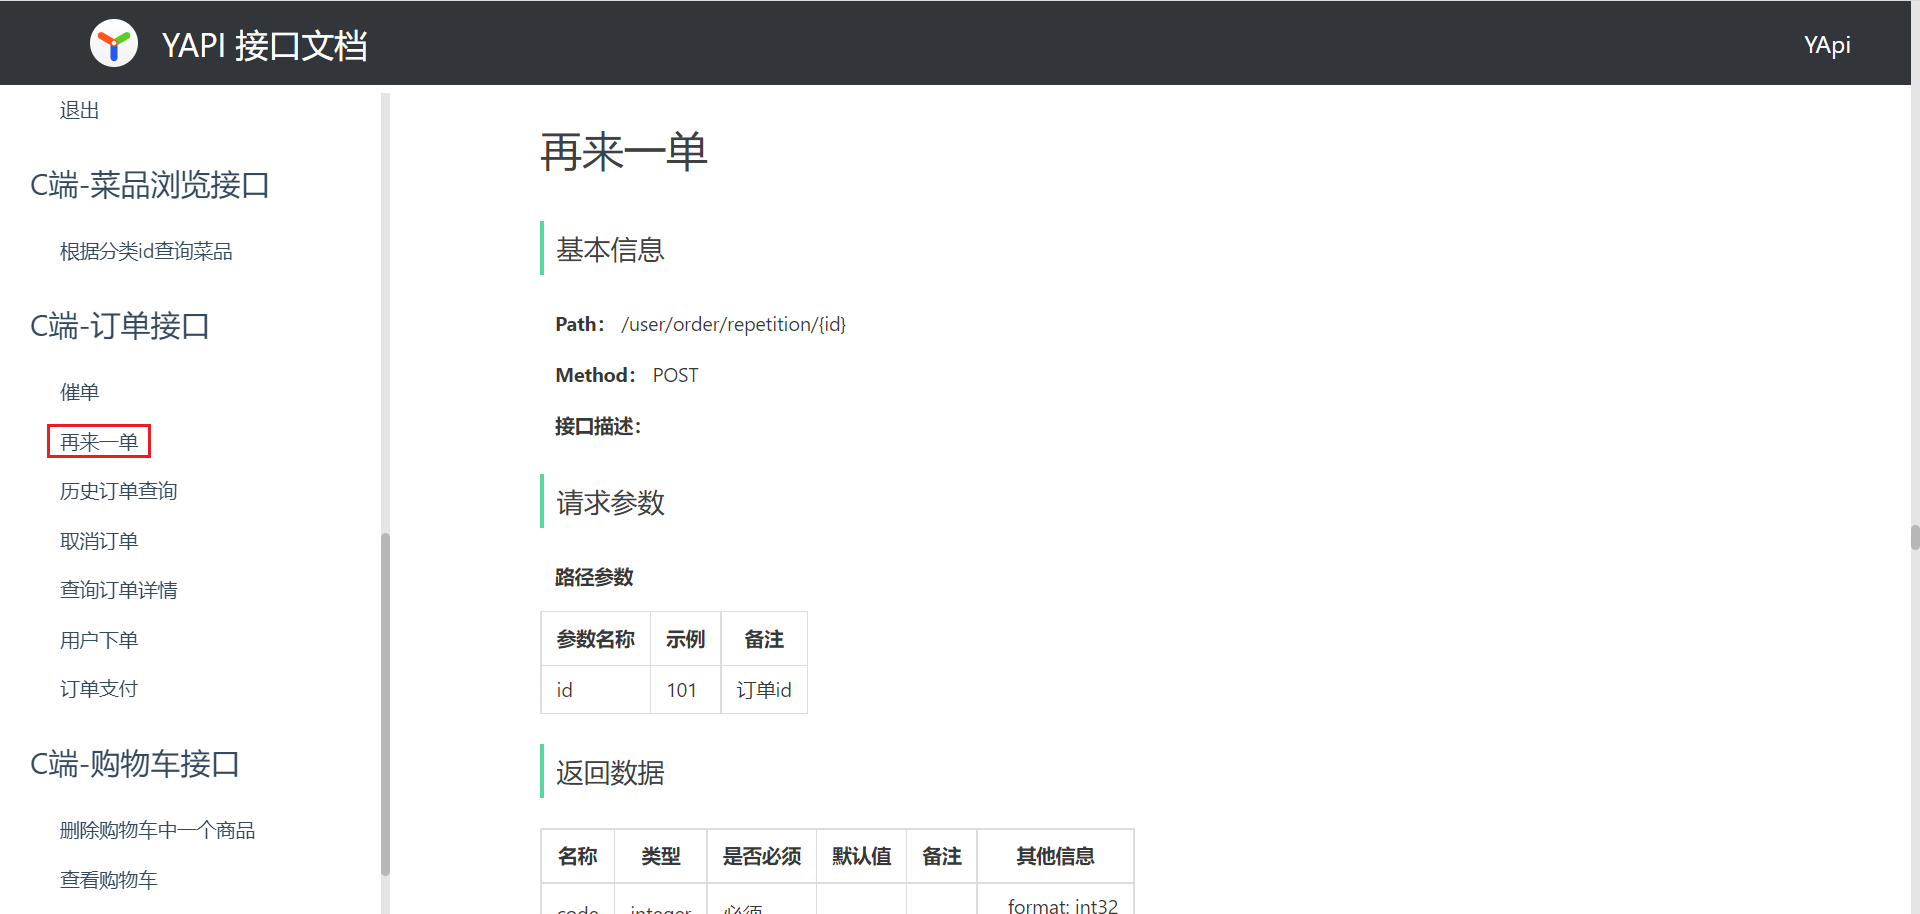

业务规则：

- 再来一单就是将原订单中的商品重新加入到购物车中


### “再来一单”是重新校验，不是复制价格（补充）

历史明细是下单时快照，重新加入购物车前要检查商品或套餐仍存在、仍可售、口味/规格仍有效。价格按当前商品规则重新读取，不能把历史单价当作当前报价。相同商品和相同规格可以合并数量；不同规格必须分行保存。

接口仍然只接受订单 id，用户身份来自登录上下文。


### 4.2 代码实现

#### 4.2.1 user/OrderController

~~~java
    /**
     * 再来一单
     *
     * @param id
     * @return
     */
    @PostMapping("/repetition/{id}")
    @ApiOperation("再来一单")
    public Result repetition(@PathVariable Long id) {
        orderService.repetition(id);
        return Result.success();
    }
~~~

#### 4.2.2 OrderService

~~~java
    /**
     * 再来一单
     *
     * @param id
     */
    void repetition(Long id);
~~~

#### 4.2.3 OrderServiceImpl

~~~java
	/**
     * 再来一单
     *
     * @param id
     */
    public void repetition(Long id) {
        // 查询当前用户id
        Long userId = BaseContext.getCurrentId();

        // 根据订单id查询当前订单详情
        List<OrderDetail> orderDetailList = orderDetailMapper.getByOrderId(id);

        // 将订单详情对象转换为购物车对象
        List<ShoppingCart> shoppingCartList = orderDetailList.stream().map(x -> {
            ShoppingCart shoppingCart = new ShoppingCart();

            // 将原订单详情里面的菜品信息重新复制到购物车对象中
            BeanUtils.copyProperties(x, shoppingCart, "id");
            shoppingCart.setUserId(userId);
            shoppingCart.setCreateTime(LocalDateTime.now());

            return shoppingCart;
        }).collect(Collectors.toList());

        // 将购物车对象批量添加到数据库
        shoppingCartMapper.insertBatch(shoppingCartList);
    }
~~~

#### 4.2.4 ShoppingCartMapper

~~~java
    /**
     * 批量插入购物车数据
     *
     * @param shoppingCartList
     */
    void insertBatch(List<ShoppingCart> shoppingCartList);
~~~

#### 4.2.5 ShoppingCartMapper.xml

~~~xml
<insert id="insertBatch" parameterType="list">
        insert into shopping_cart
        (name, image, user_id, dish_id, setmeal_id, dish_flavor, number, amount, create_time)
        values
        <foreach collection="shoppingCartList" item="sc" separator=",">
            (#{sc.name},#{sc.image},#{sc.userId},#{sc.dishId},#{sc.setmealId},#{sc.dishFlavor},#{sc.number},#{sc.amount},#{sc.createTime})
        </foreach>
</insert>
~~~


### 再来一单的归属、可售和幂等（勘误）

原实现只按订单 id 查询明细，没有验证订单是否属于当前用户；应先查询 `order` 与当前 user_id，再读取明细。每一行还要补充商品/套餐存在和 status=1 的校验，停售或删除时返回可理解的业务错误。

`insertBatch` 无条件插入会造成重复购物车行，且 `collection="shoppingCartList"` 需要与 `@Param` 名称一致。补充明确参数名（导入MyBatis Param）：

```java
void insertBatch(@Param("shoppingCartList")
                 List<ShoppingCart> shoppingCartList);
```

空明细列表不可调用batch insert，否则VALUES为空会失败；普通单商品添加与本章批量方法并存，不重复声明冲突的Mapper方法。转换时不能继承明细主键id，原copyProperties排除了id；重新赋值当前userId、当前有效商品资料和createTime。

可按用户、商品类型、商品id、规范化口味建立唯一键并upsert，或在Service合并同规格商品。dish_id/setmeal_id互斥且有null值，MySQL包含null的普通联合唯一索引可能仍允许重复，必须先设计规范化键。数量相加需原子SQL，初次并发插入需唯一约束兜底；不同价格变化按报价规则处理。

明确“再来一单”重复点击是否复用同一请求号。单条INSERT通常原子，但商品复核、已有购物车增量和新行插入涉及多步时应加入本地事务；“事务”与“同一请求只生效一次”分别设计。


### 4.3 功能测试

略


### 再来一单验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 自己的历史订单全部可售 | 商品按当前规则加入购物车 |
| 订单中有停售商品 | 明确提示并按约定部分失败或整体失败 |
| 用户A使用用户B订单id | 拒绝且不写入A的购物车 |
| 相同规格重复点击 | 按幂等策略合并或只生成一次 |
| 不同口味同商品 | 保持为不同购物车行 |
| 批量写入中途失败 | 事务回滚，不留下半单购物车 |


# 商家端订单管理模块


## 1. 订单搜索


### 1.1 需求分析和设计

产品原型：

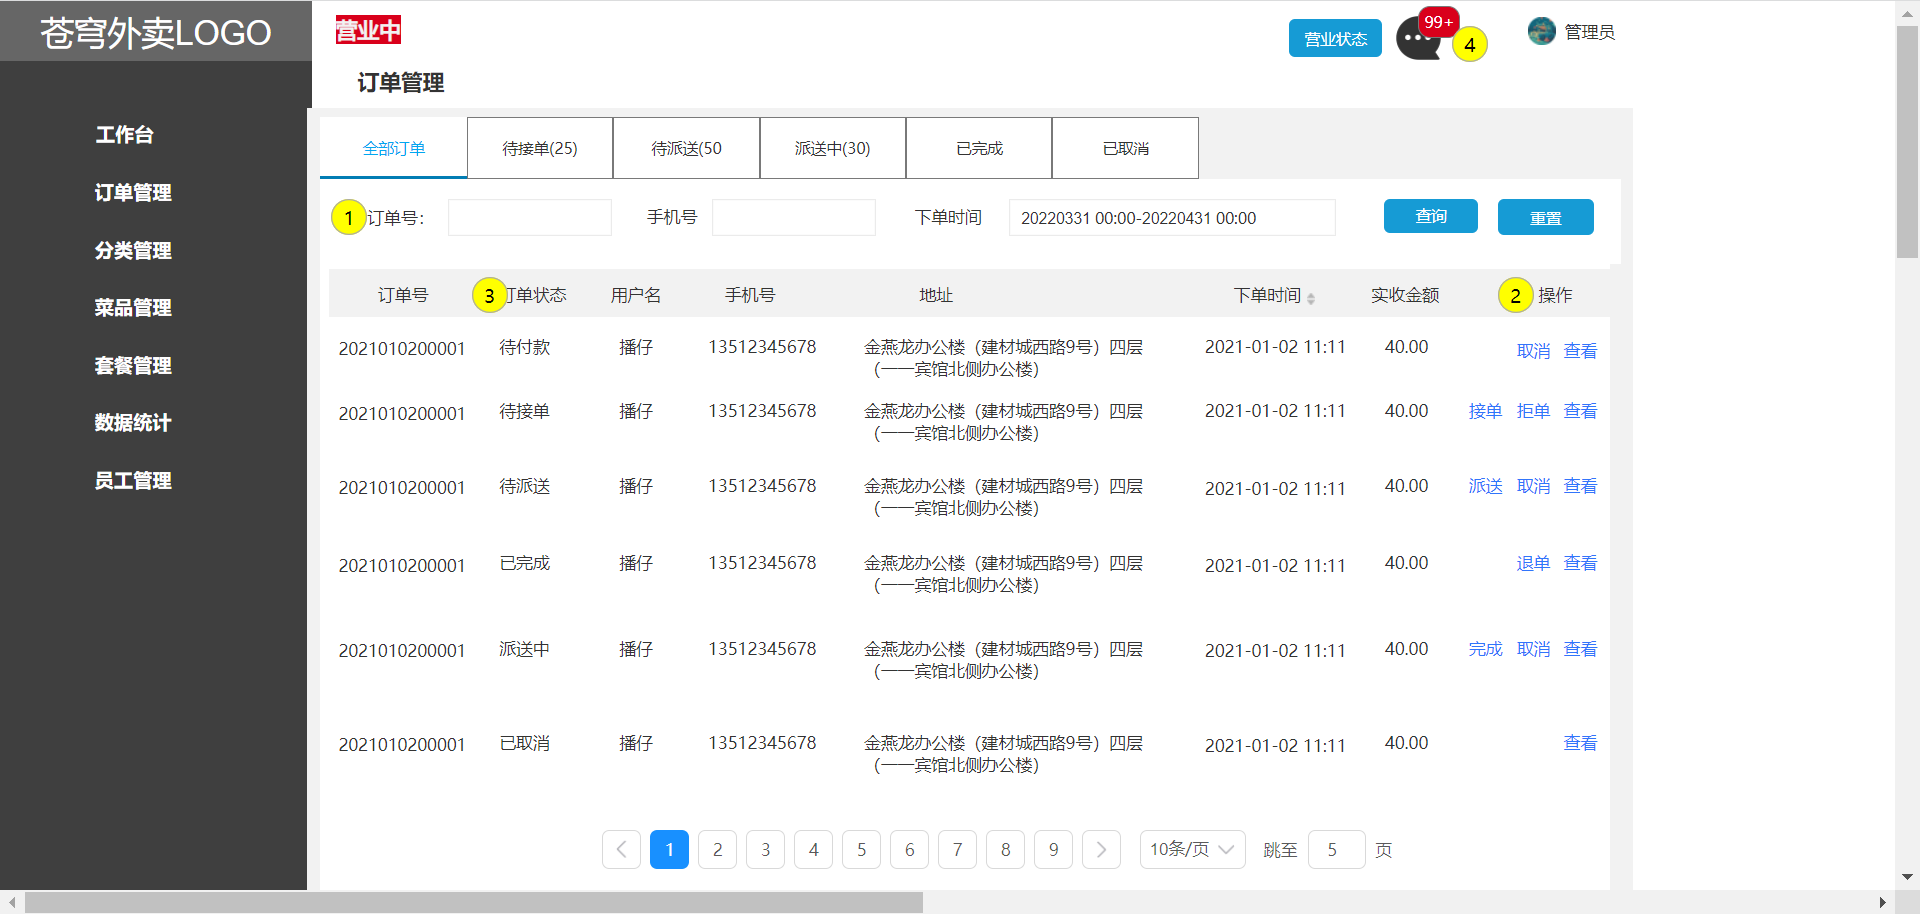

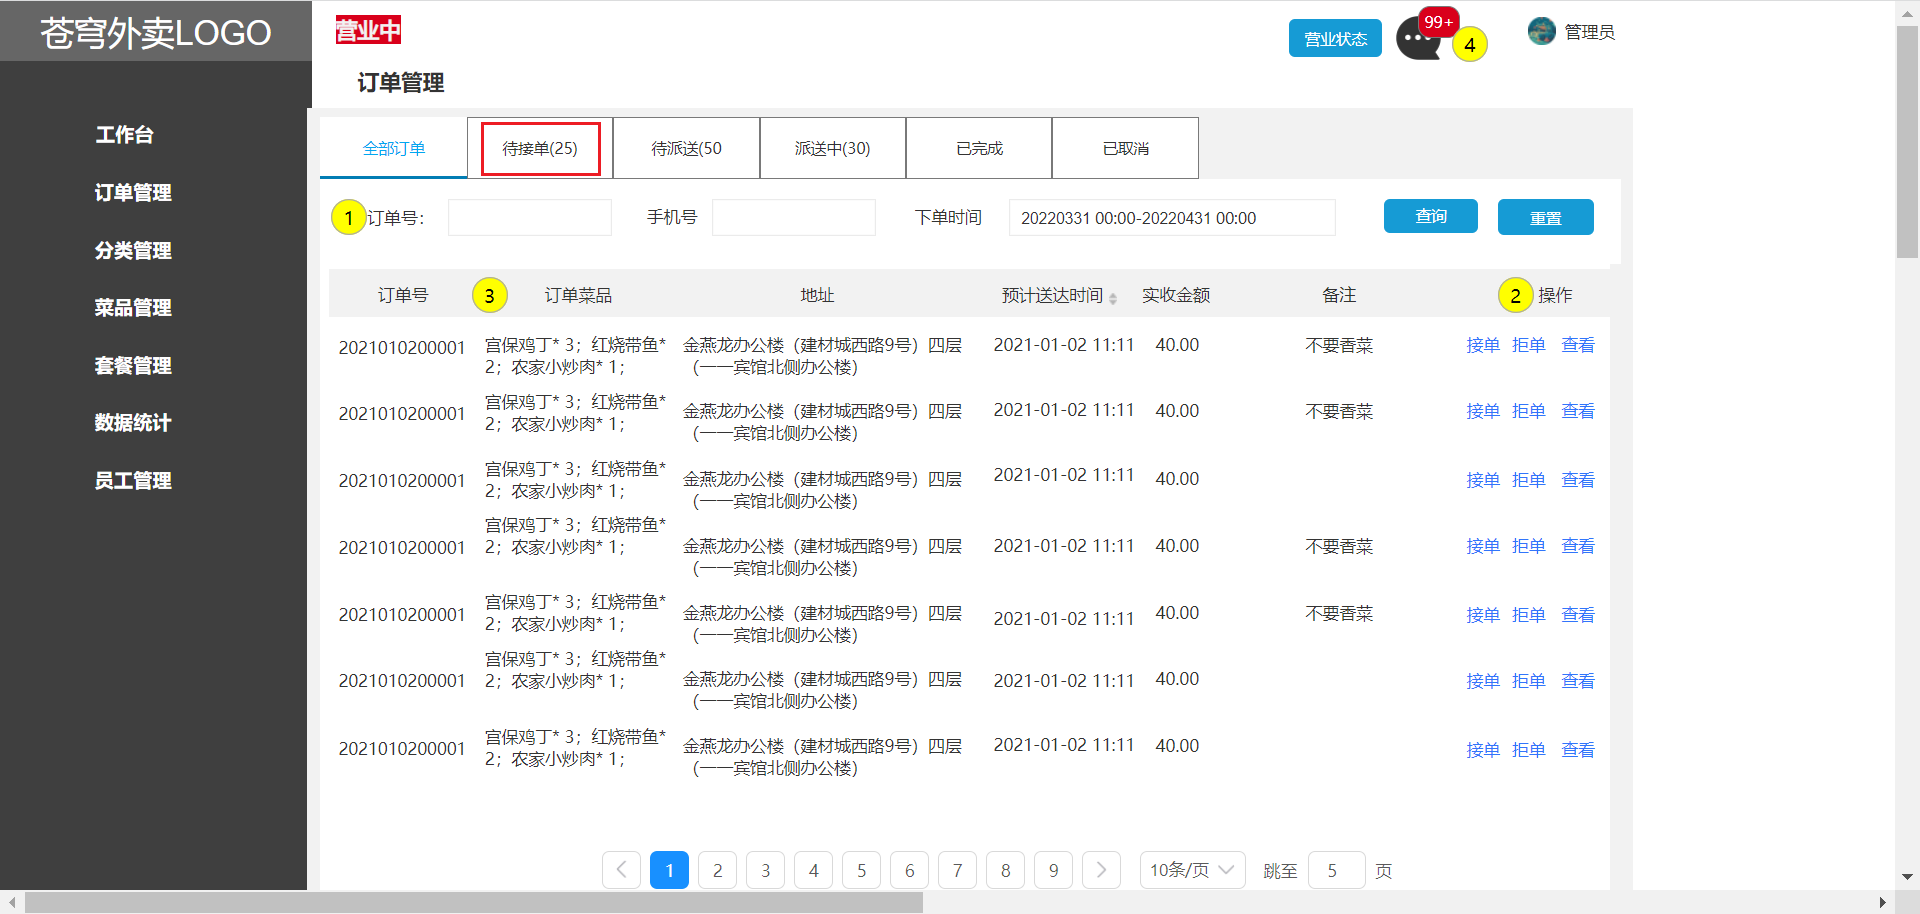

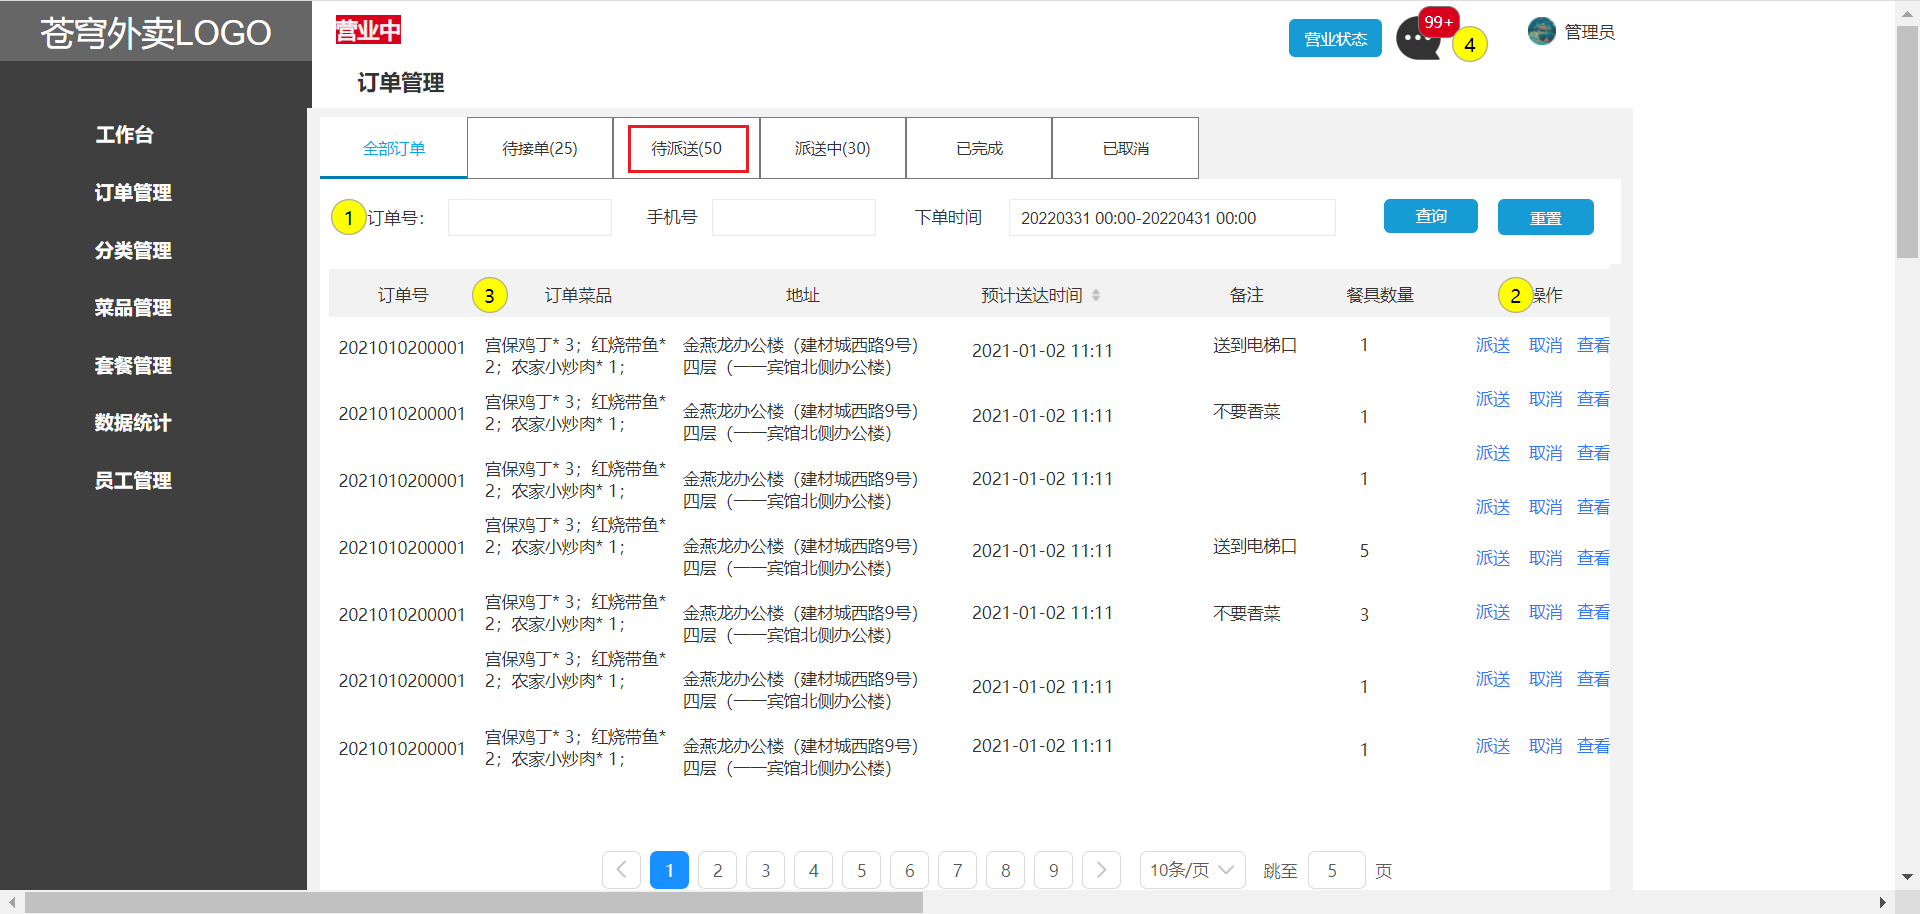

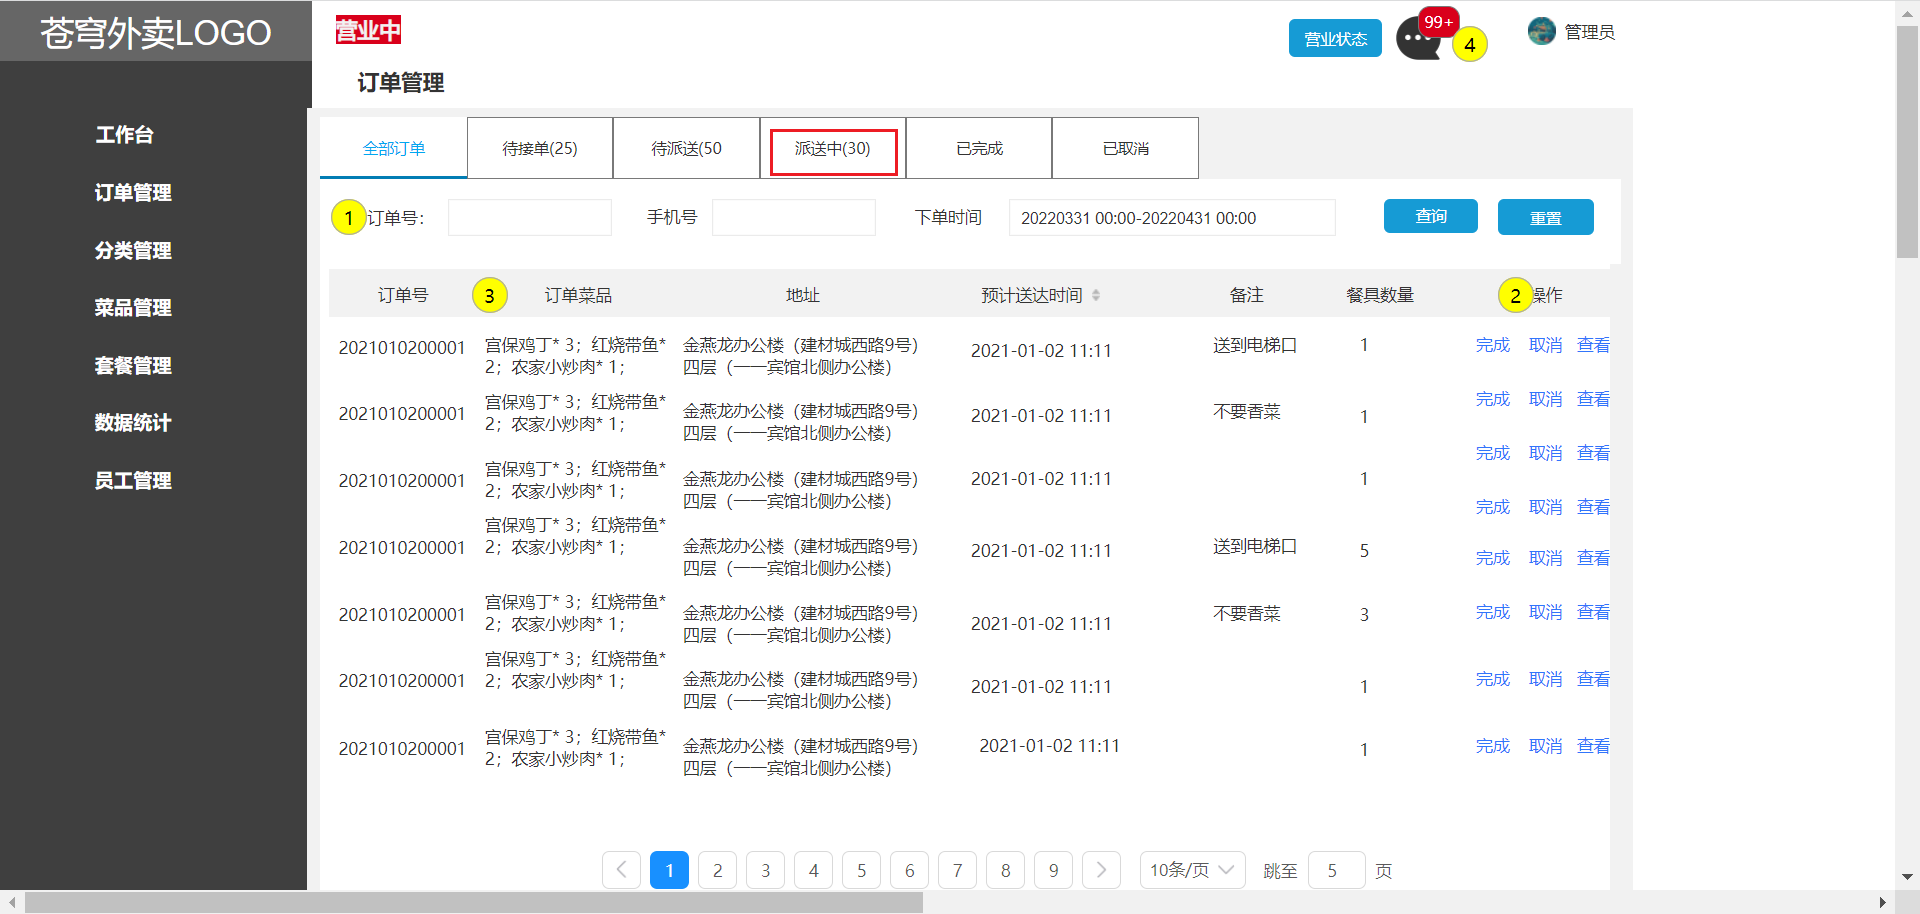

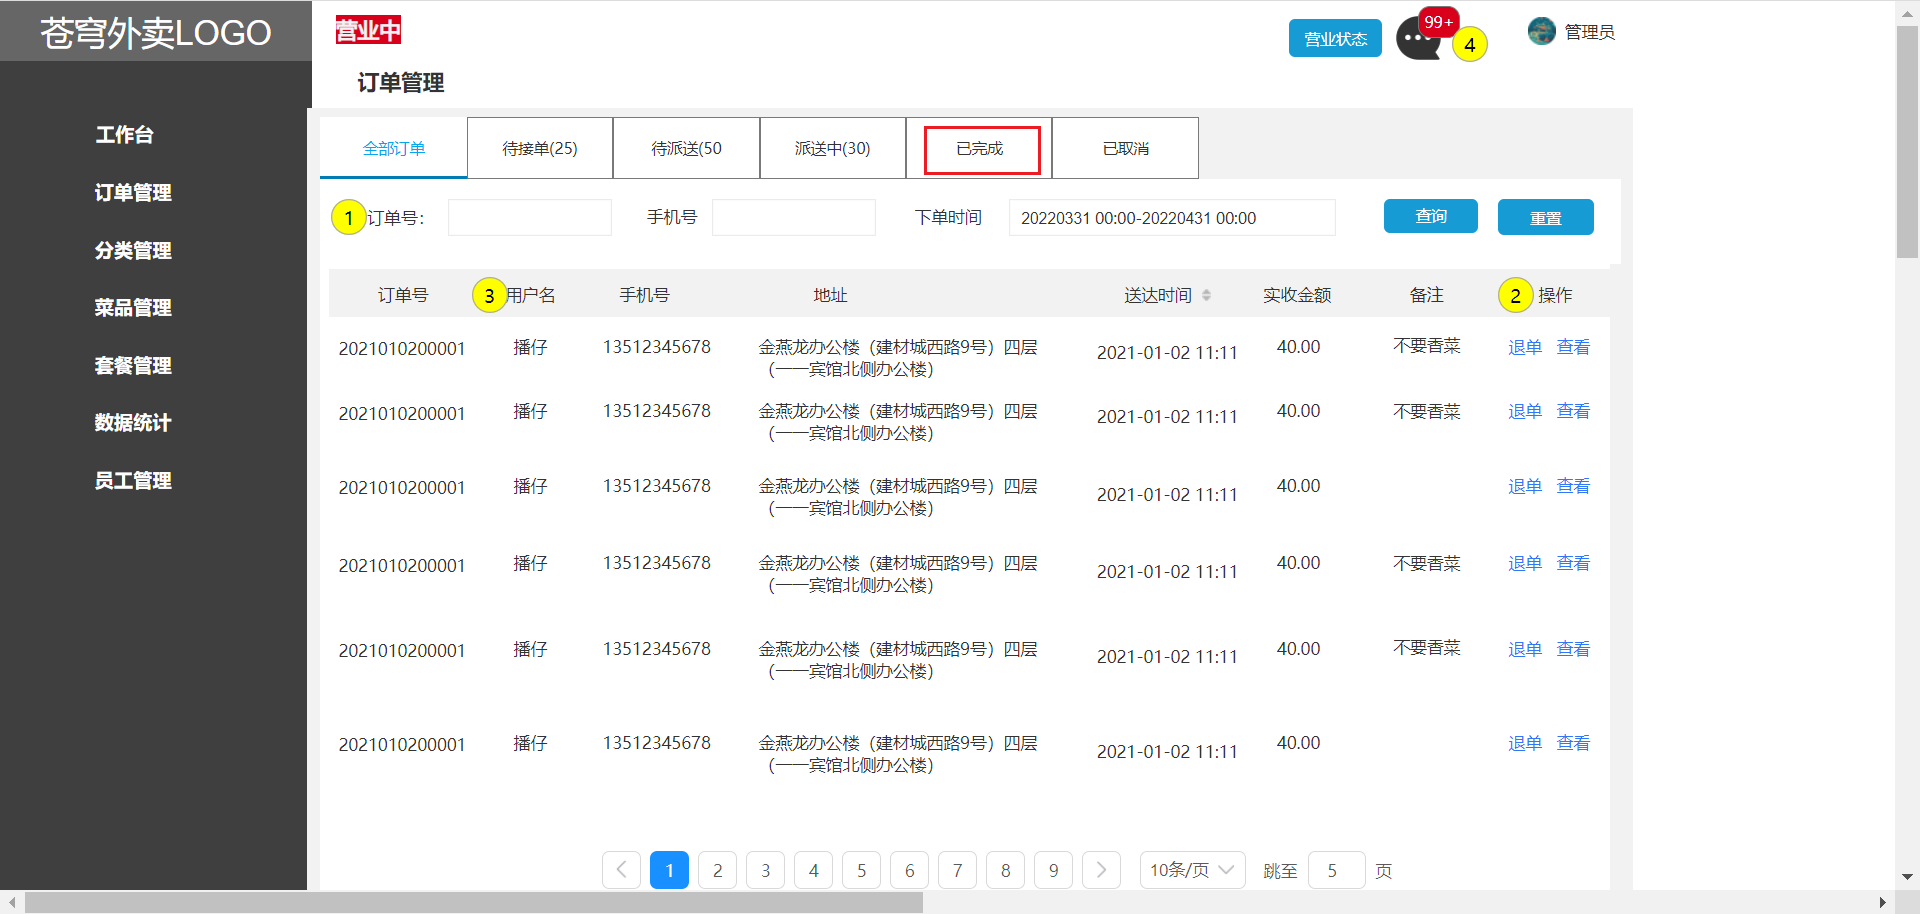

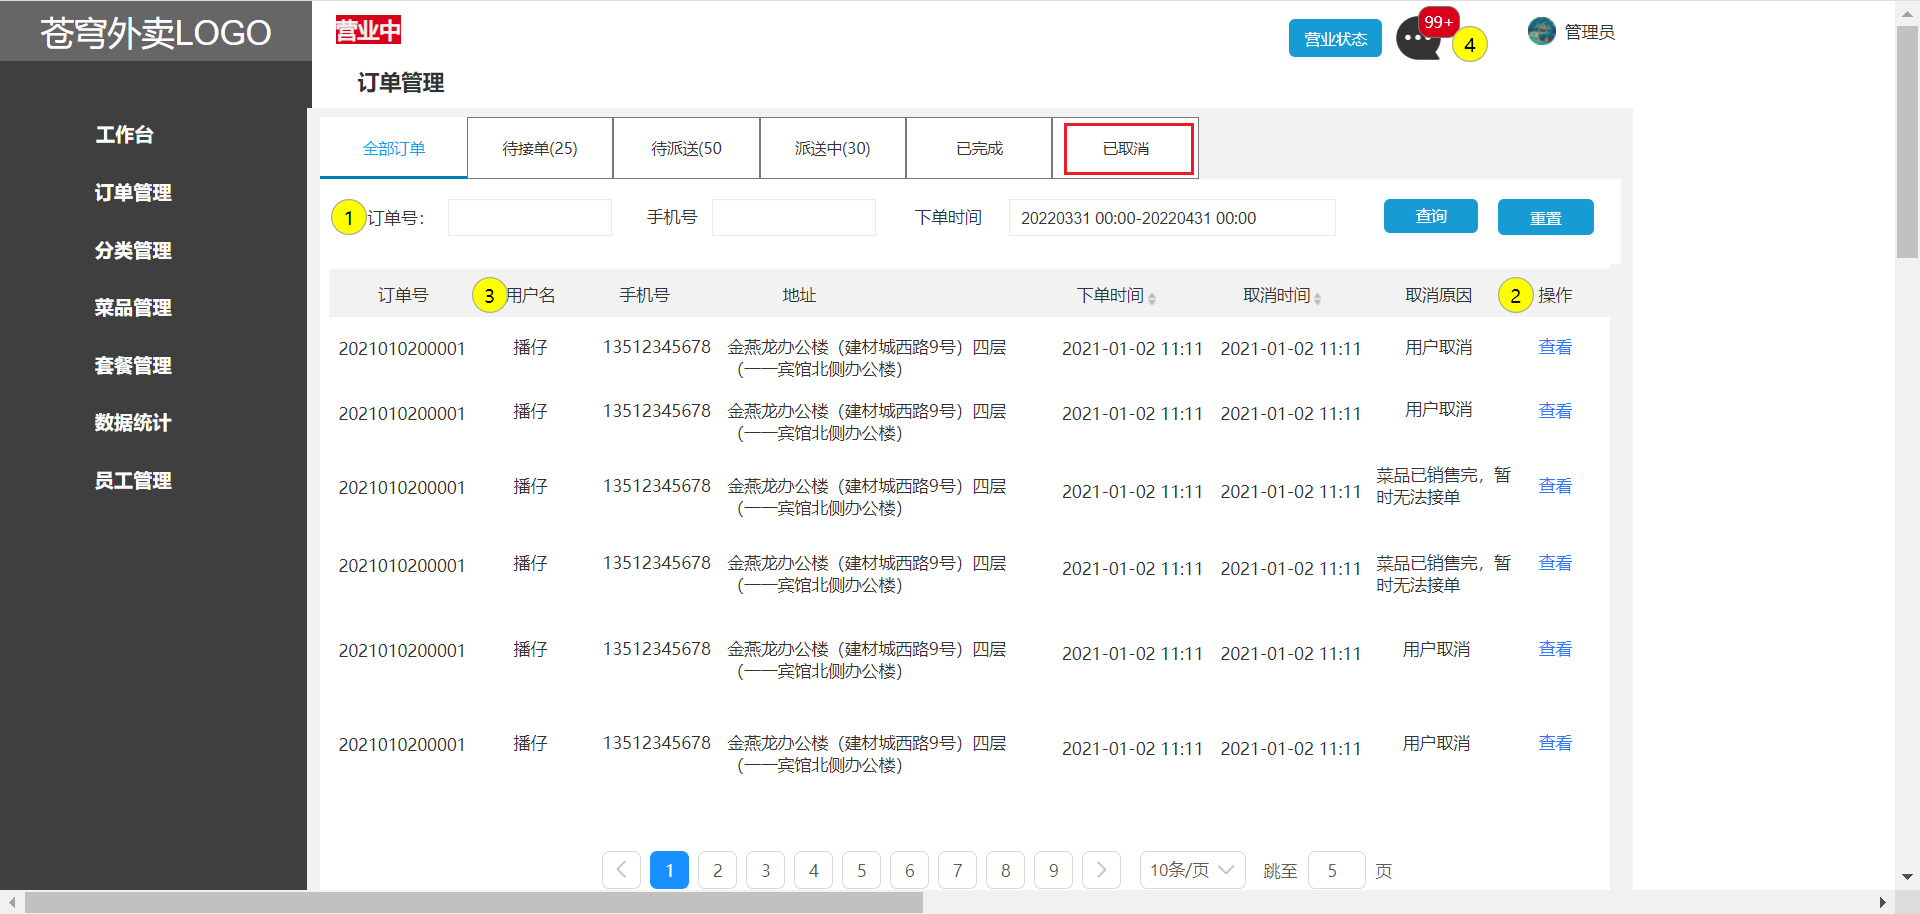


业务规则：

- 输入订单号/手机号进行搜索，支持模糊搜索
- 根据订单状态进行筛选
- 下单时间进行时间筛选
- 搜索内容为空，提示未找到相关订单
- 搜索结果页，展示包含搜索关键词的内容
- 分页展示搜索到的订单数据

接口设计：参见接口文档

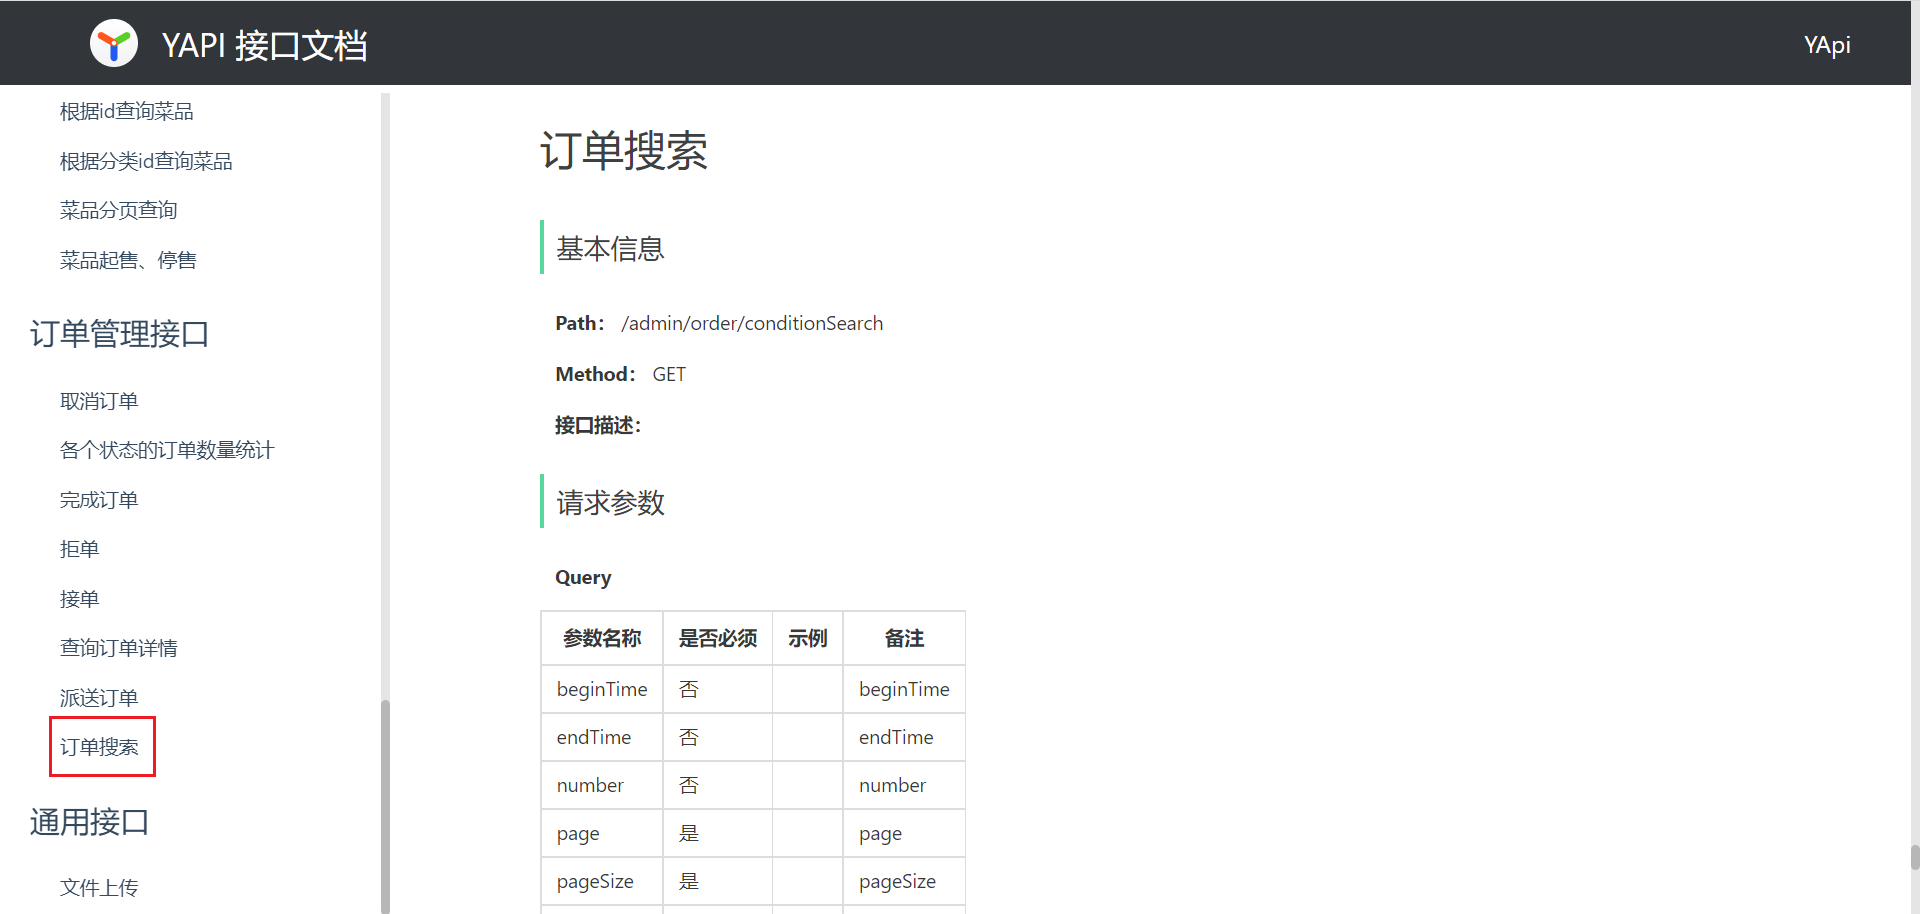


### 搜索条件的服务端约束（补充）

订单号和手机号可以模糊查询，但空字符串应按“无条件”处理而不是拼接无意义条件。状态只能是约定枚举，开始时间不能晚于结束时间，时间边界要明确是否包含当天结束时刻。分页上限和排序字段固定在服务端，避免把任意 SQL 片段交给前端。


### 1.2 代码实现

#### 1.2.1 admin/OrderController

在admin包下创建OrderController

~~~java
/**
 * 订单管理
 */
@RestController("adminOrderController")
@RequestMapping("/admin/order")
@Slf4j
@Api(tags = "订单管理接口")
public class OrderController {

    @Autowired
    private OrderService orderService;

    /**
     * 订单搜索
     *
     * @param ordersPageQueryDTO
     * @return
     */
    @GetMapping("/conditionSearch")
    @ApiOperation("订单搜索")
    public Result<PageResult> conditionSearch(OrdersPageQueryDTO ordersPageQueryDTO) {
        PageResult pageResult = orderService.conditionSearch(ordersPageQueryDTO);
        return Result.success(pageResult);
    }
}
~~~

#### 1.2.2 OrderService

~~~java
    /**
     * 条件搜索订单
     * @param ordersPageQueryDTO
     * @return
     */
    PageResult conditionSearch(OrdersPageQueryDTO ordersPageQueryDTO);
~~~

#### 1.2.3 OrderServiceImpl

~~~java
    /**
     * 订单搜索
     *
     * @param ordersPageQueryDTO
     * @return
     */
    public PageResult conditionSearch(OrdersPageQueryDTO ordersPageQueryDTO) {
        PageHelper.startPage(ordersPageQueryDTO.getPage(), ordersPageQueryDTO.getPageSize());

        Page<Orders> page = orderMapper.pageQuery(ordersPageQueryDTO);

        // 部分订单状态，需要额外返回订单菜品信息，将Orders转化为OrderVO
        List<OrderVO> orderVOList = getOrderVOList(page);

        return new PageResult(page.getTotal(), orderVOList);
    }

    private List<OrderVO> getOrderVOList(Page<Orders> page) {
        // 需要返回订单菜品信息，自定义OrderVO响应结果
        List<OrderVO> orderVOList = new ArrayList<>();

        List<Orders> ordersList = page.getResult();
        if (!CollectionUtils.isEmpty(ordersList)) {
            for (Orders orders : ordersList) {
                // 将共同字段复制到OrderVO
                OrderVO orderVO = new OrderVO();
                BeanUtils.copyProperties(orders, orderVO);
                String orderDishes = getOrderDishesStr(orders);

                // 将订单菜品信息封装到orderVO中，并添加到orderVOList
                orderVO.setOrderDishes(orderDishes);
                orderVOList.add(orderVO);
            }
        }
        return orderVOList;
    }

    /**
     * 根据订单id获取菜品信息字符串
     *
     * @param orders
     * @return
     */
    private String getOrderDishesStr(Orders orders) {
        // 查询订单菜品详情信息（订单中的菜品和数量）
        List<OrderDetail> orderDetailList = orderDetailMapper.getByOrderId(orders.getId());

        // 将每一条订单菜品信息拼接为字符串（格式：宫保鸡丁*3；）
        List<String> orderDishList = orderDetailList.stream().map(x -> {
            String orderDish = x.getName() + "*" + x.getNumber() + ";";
            return orderDish;
        }).collect(Collectors.toList());

        // 将该订单对应的所有菜品信息拼接在一起
        return String.join("", orderDishList);
    }
~~~


### 搜索的 N+1 与输入校验（勘误）

`getOrderVOList` 对当前页每个订单再查一次明细，页大小增大后会产生 N+1 查询。课程练习可以保留原写法，但生产实现应批量查 `where order_id in (...)`，按订单 id 分组后组装 `orderDishes`。

搜索前校验 `page`、`pageSize`、status、beginTime/endTime；MyBatis 参数使用 `@Param`，日期解析失败应返回参数错误。订单明细字符串只是展示字段，不能作为后续计算金额的依据。


### 1.3 功能测试

略


### 搜索验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 订单号/手机号部分匹配 | 只返回匹配订单，结果按下单时间倒序 |
| status、时间范围组合 | 条件同时生效，边界可解释 |
| 空条件 | 分页返回，不提示 SQL 错误 |
| 非法日期、反向时间 | 参数校验失败 |
| 一页多订单 | 明细不串单，查询次数受控 |
| 无结果 | total=0、列表为空，统计值不为null |


## 2. 各个状态的订单数量统计


### 2.1 需求分析和设计

产品原型：

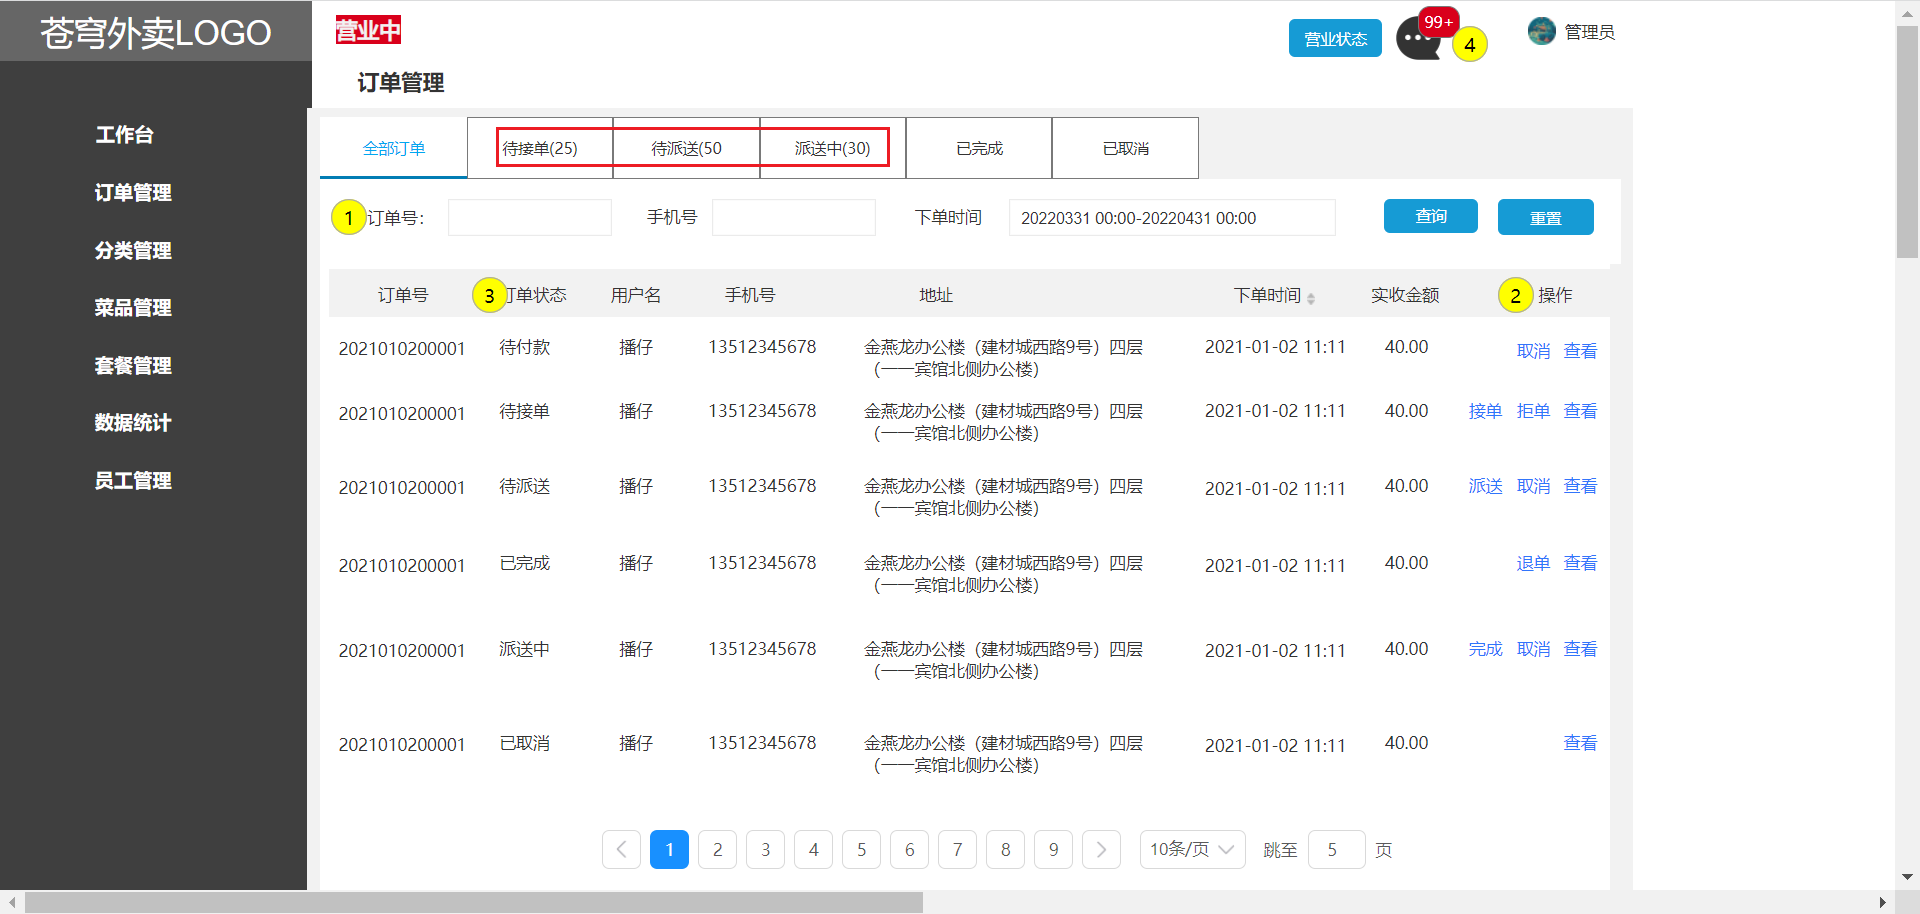


接口设计：参见接口文档

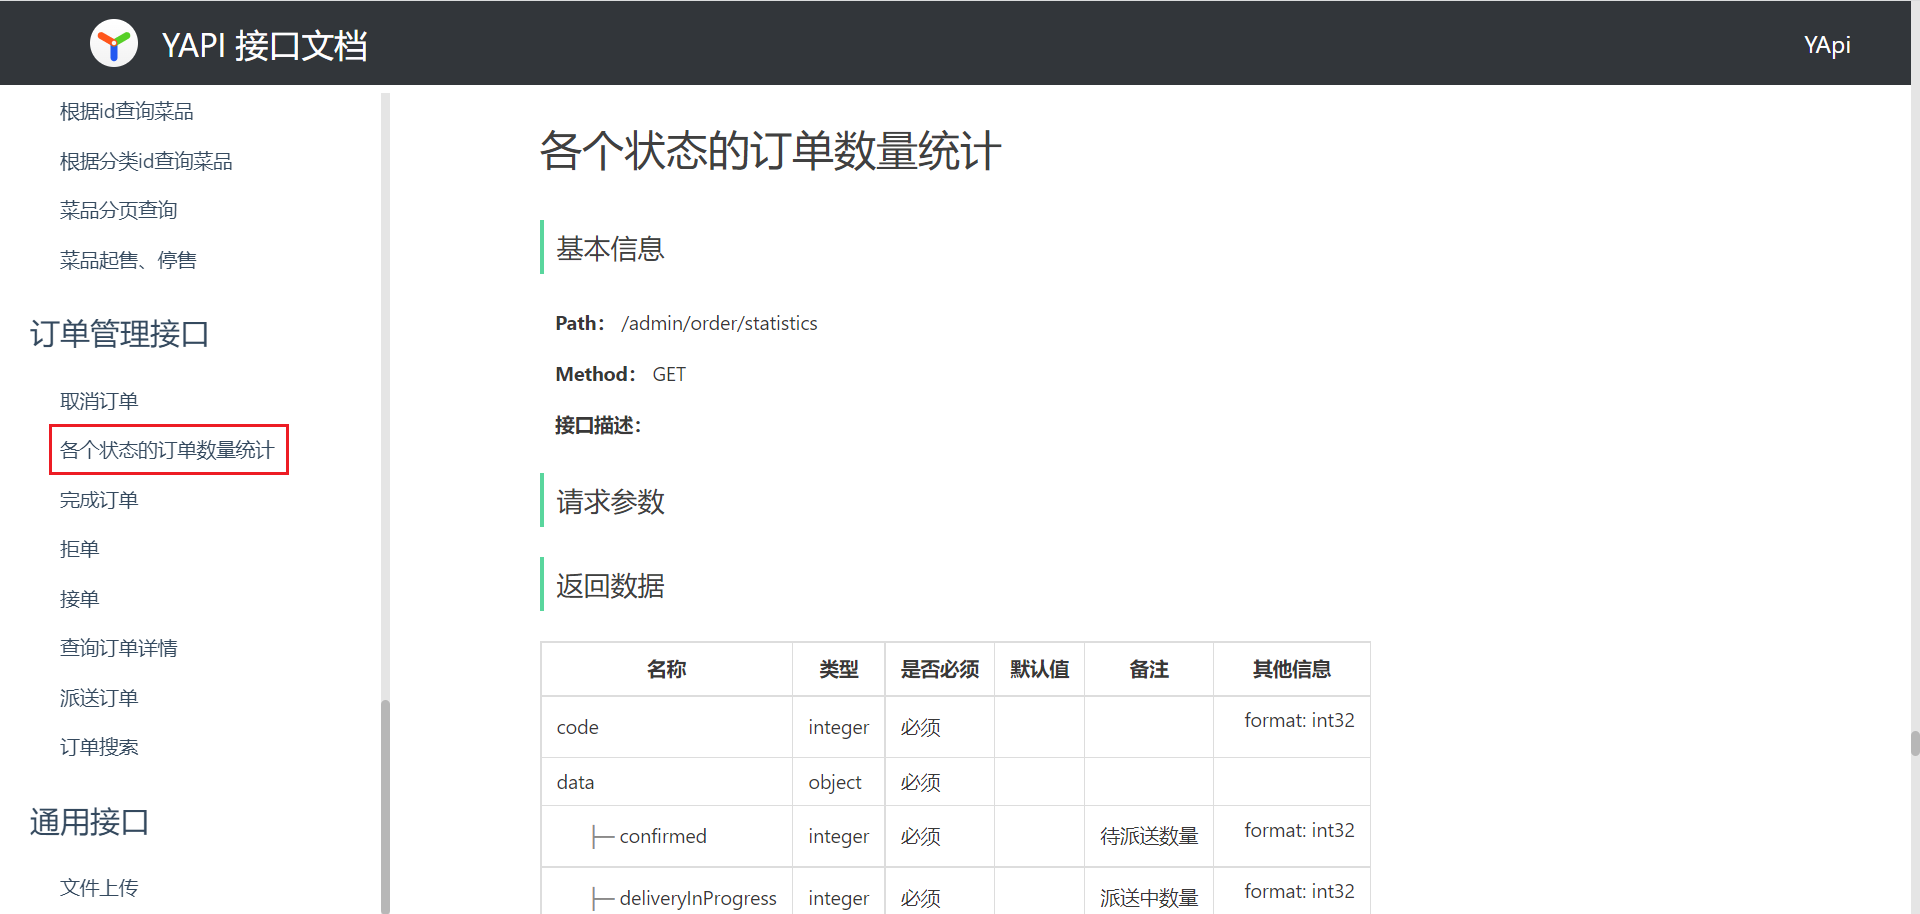


### 状态统计要和页面含义一致（补充）

管理页通常只展示待接单、待派送、派送中三个数字，但“待派送”对应已接单状态，“待接单”对应待接单状态，字段命名不要误导。统计接口不应把取消或已完成订单混入待处理数，空表必须返回 0。


### 2.2 代码实现

#### 2.2.1 admin/OrderController

~~~java
    /**
     * 各个状态的订单数量统计
     *
     * @return
     */
    @GetMapping("/statistics")
    @ApiOperation("各个状态的订单数量统计")
    public Result<OrderStatisticsVO> statistics() {
        OrderStatisticsVO orderStatisticsVO = orderService.statistics();
        return Result.success(orderStatisticsVO);
    }
~~~

#### 2.2.2 OrderService

~~~java
    /**
     * 各个状态的订单数量统计
     * @return
     */
    OrderStatisticsVO statistics();
~~~

#### 2.2.3 OrderServiceImpl

~~~java
    /**
     * 各个状态的订单数量统计
     *
     * @return
     */
    public OrderStatisticsVO statistics() {
        // 根据状态，分别查询出待接单、待派送、派送中的订单数量
        Integer toBeConfirmed = orderMapper.countStatus(Orders.TO_BE_CONFIRMED);
        Integer confirmed = orderMapper.countStatus(Orders.CONFIRMED);
        Integer deliveryInProgress = orderMapper.countStatus(Orders.DELIVERY_IN_PROGRESS);

        // 将查询出的数据封装到orderStatisticsVO中响应
        OrderStatisticsVO orderStatisticsVO = new OrderStatisticsVO();
        orderStatisticsVO.setToBeConfirmed(toBeConfirmed);
        orderStatisticsVO.setConfirmed(confirmed);
        orderStatisticsVO.setDeliveryInProgress(deliveryInProgress);
        return orderStatisticsVO;
    }
~~~

#### 2.2.4 OrderMapper

~~~java
    /**
     * 根据状态统计订单数量
     * @param status
     */
    @Select("select count(id) from orders where status = #{status}")
    Integer countStatus(Integer status);
~~~


### 统计查询的空值与并发（勘误）

原`count(id)`没有group by，标准聚合无匹配记录返回0，并非必然null。三个独立count会看到不同时间点的数据，若页面要求同一快照，可改为一次`group by status`查询。分组查询没有某状态时不会返回那一行，组装VO时才需要为缺失状态补0。


### 2.3 功能测试

略


### 统计验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 各状态各有订单 | 三个字段与数据库状态计数一致 |
| 空订单表 | 三个字段均为0 |
| 取消/完成订单 | 不计入待处理数量 |
| 统计期间状态变化 | 结果允许有时间差，但字段语义不变 |


## 3. 查询订单详情


### 3.1 需求分析和设计

产品原型：

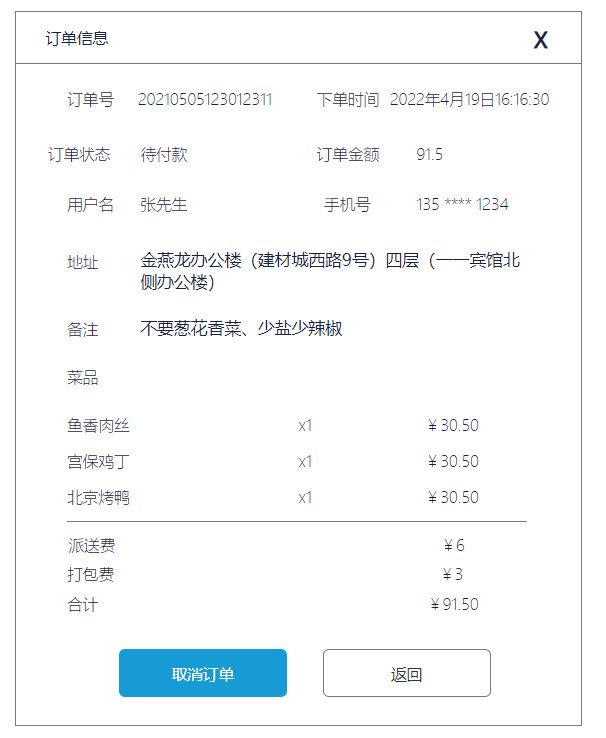

业务规则：

- 订单详情页面需要展示订单基本信息（状态、订单号、下单时间、收货人、电话、收货地址、金额等）
- 订单详情页面需要展示订单明细数据（商品名称、数量、单价）

接口设计：参见接口文档

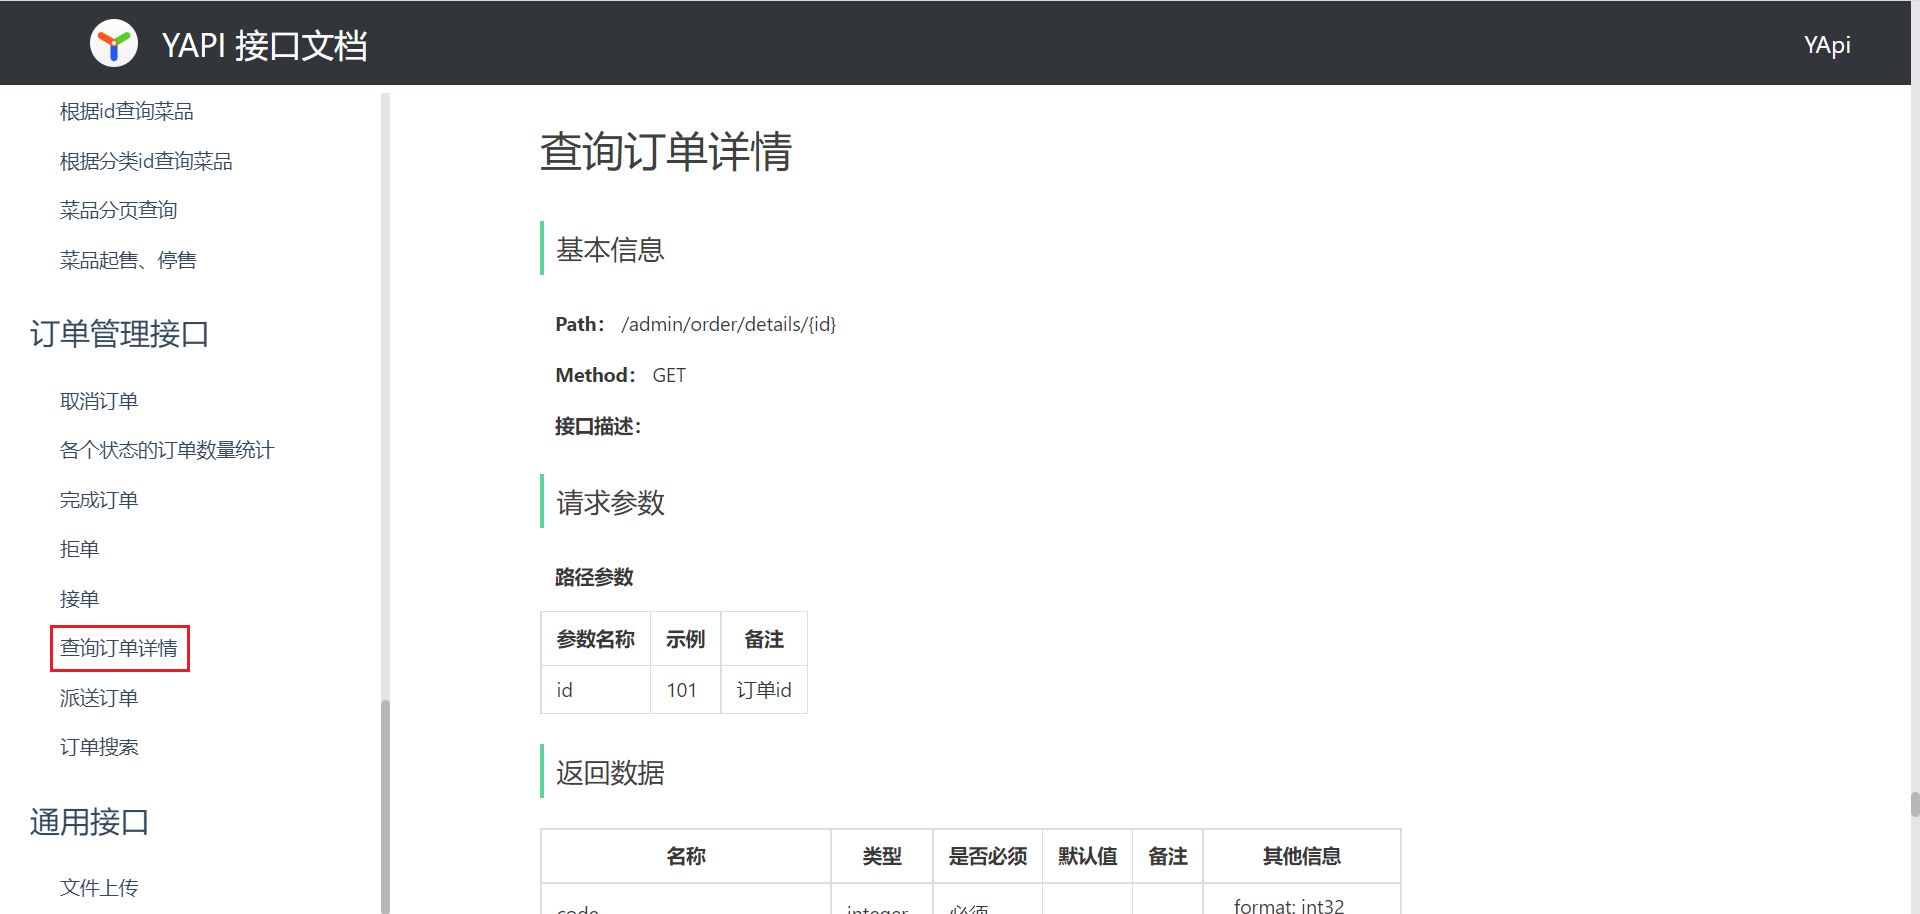


### 管理端详情的范围（补充）

管理端可以查看所有订单，但仍要检查订单存在、明细关联和金额字段完整。详情页显示订单快照与明细单价；任何“重新查询当前菜品价格”的做法都会改变历史账单含义。


### 3.2 代码实现

#### 3.2.1 admin/OrderController

~~~java
    /**
     * 订单详情
     *
     * @param id
     * @return
     */
    @GetMapping("/details/{id}")
    @ApiOperation("查询订单详情")
    public Result<OrderVO> details(@PathVariable("id") Long id) {
        OrderVO orderVO = orderService.details(id);
        return Result.success(orderVO);
    }
~~~


### 详情读取避免空指针（勘误）

管理端详情复用 Service 方法时，先判断订单是否存在，再查询明细并组装 `OrderVO`。管理员权限由拦截器或注解保护，不能仅因为路径以 `/admin` 开头就认为可信。


### 3.3 功能测试

略


### 管理端详情验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 有效订单 | 基本信息与明细金额齐全 |
| 不存在订单 | 统一业务错误 |
| 明细为空 | 空列表，不抛空指针 |
| 非管理员访问 | 被鉴权拦截 |


## 4. 接单


### 4.1 需求分析和设计

产品原型：

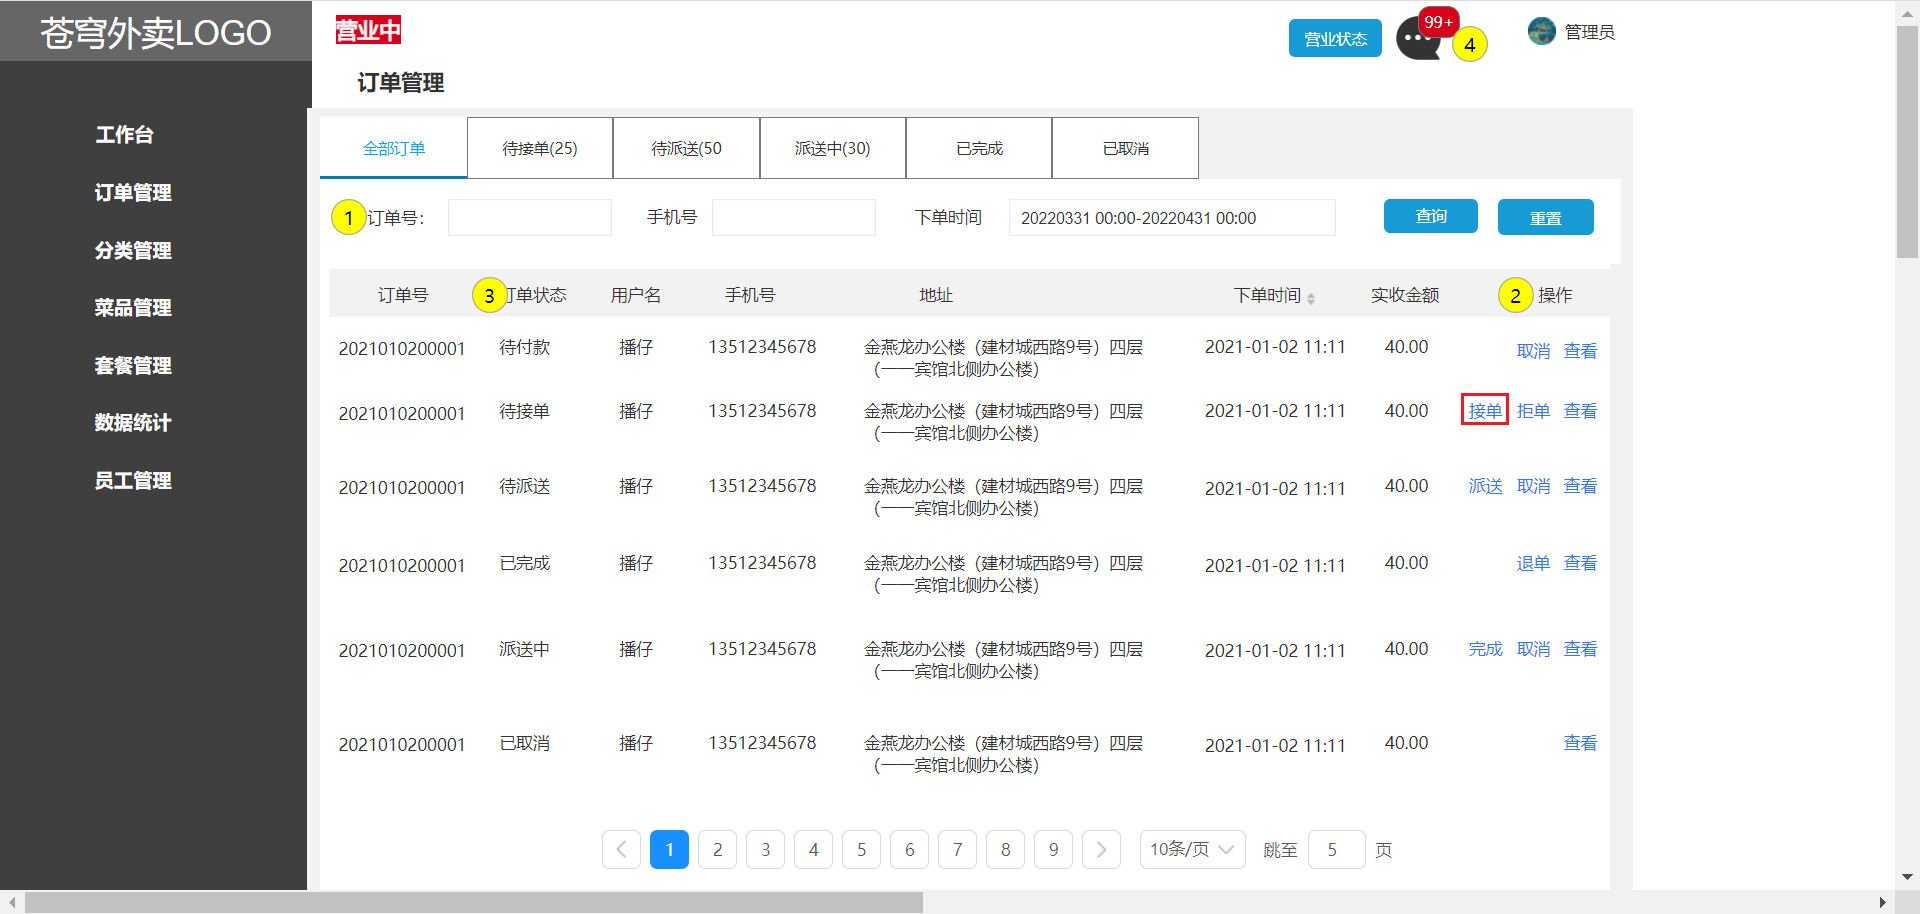

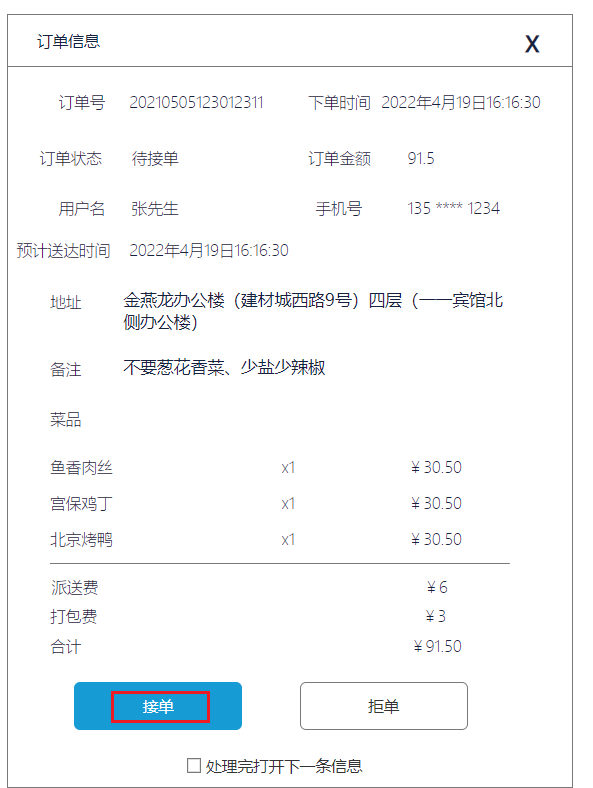

业务规则：

- 商家接单其实就是将订单的状态修改为“已接单”

接口设计：参见接口文档

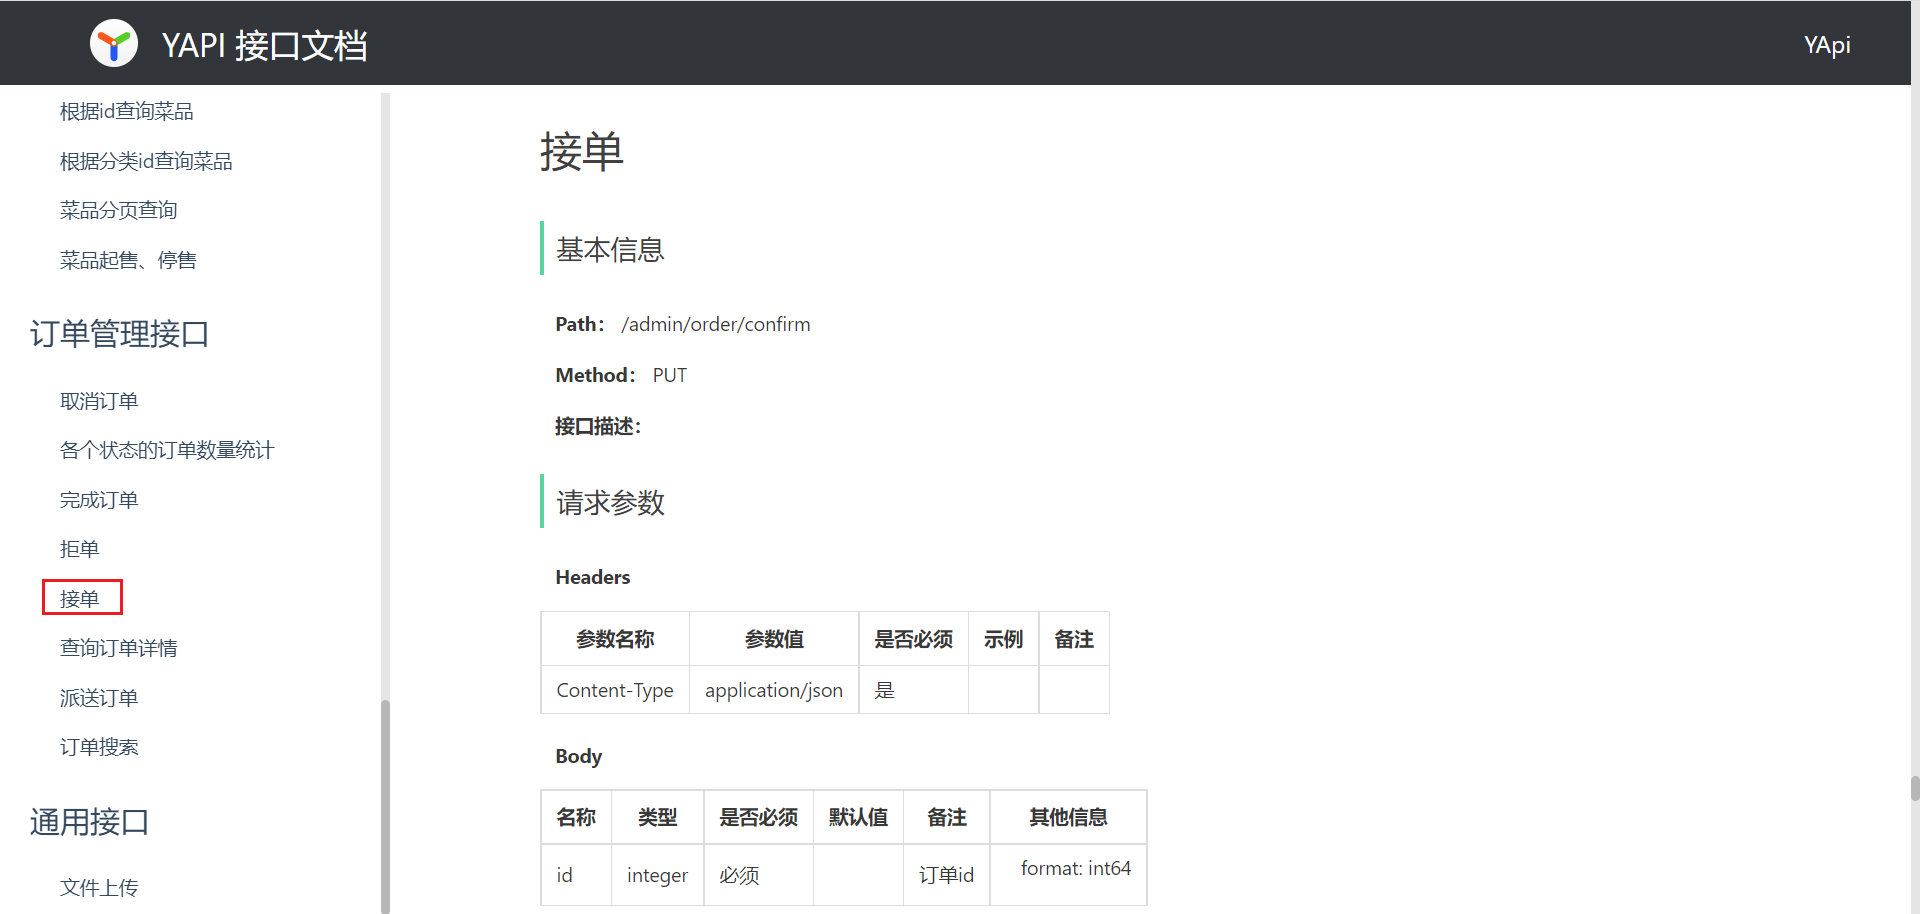


### 接单是受限状态迁移（补充）

只有待接单订单可以接单。接单后写入确认时间（若表有该字段）并进入已接单；已经被拒单、取消或完成的订单不能被按钮再次改回去。


### 4.2 代码实现

#### 4.2.1 admin/OrderController

~~~java
    /**
     * 接单
     *
     * @return
     */
    @PutMapping("/confirm")
    @ApiOperation("接单")
    public Result confirm(@RequestBody OrdersConfirmDTO ordersConfirmDTO) {
        orderService.confirm(ordersConfirmDTO);
        return Result.success();
    }
~~~

#### 4.2.2 OrderService

~~~java
    /**
     * 接单
     *
     * @param ordersConfirmDTO
     */
    void confirm(OrdersConfirmDTO ordersConfirmDTO);
~~~

#### 4.2.3 OrderServiceImpl

~~~java
    /**
     * 接单
     *
     * @param ordersConfirmDTO
     */
    public void confirm(OrdersConfirmDTO ordersConfirmDTO) {
        Orders orders = Orders.builder()
                .id(ordersConfirmDTO.getId())
                .status(Orders.CONFIRMED)
                .build();

        orderMapper.update(orders);
    }
~~~


### 接单要做条件更新与幂等（勘误）

原代码只构造 `id/status` 后无条件 `update`。Service应使用带前置状态的SQL，影响行数为1才成功。课程Orders实体未展示confirmTime，不能直接加confirm_time列SQL；增加接单时间或审计字段时要同步表结构、实体、Mapper与响应。

OrderMapper补充示例（沿用课程状态常量）：

```java
@Update("update orders set status = #{nextStatus} " +
        "where id = #{id} and status = #{expectedStatus} " +
        "and pay_status = #{paidStatus}")
int confirmIfPending(@Param("id") Long id,
                     @Param("expectedStatus") Integer expectedStatus,
                     @Param("nextStatus") Integer nextStatus,
                     @Param("paidStatus") Integer paidStatus);
```

Service校验DTO和id后调用，检查受影响行数：

```java
int changed = orderMapper.confirmIfPending(
        ordersConfirmDTO.getId(), Orders.TO_BE_CONFIRMED,
        Orders.CONFIRMED, Orders.PAID);
if (changed != 1) {
    throw new OrderBusinessException(MessageConstant.ORDER_STATUS_ERROR);
}
```

重复请求可按产品约定返回“已处理”或核对当前状态后幂等成功；原状态不允许时拒绝，不覆盖后续状态。派送和完成同样需要前置状态SQL，不能直接复用此接单方法。


### 4.3 功能测试

略


### 接单验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 待接单接单 | 状态变为已接单；若扩展审计，操作时间正确 |
| 已接单重复接单 | 不产生回退或重复副作用 |
| 已取消/已完成接单 | 拒绝 |
| 两个管理员同时接单 | 只有一个成功，另一个得到幂等结果 |


## 5. 拒单


### 5.1 需求分析和设计

产品原型：

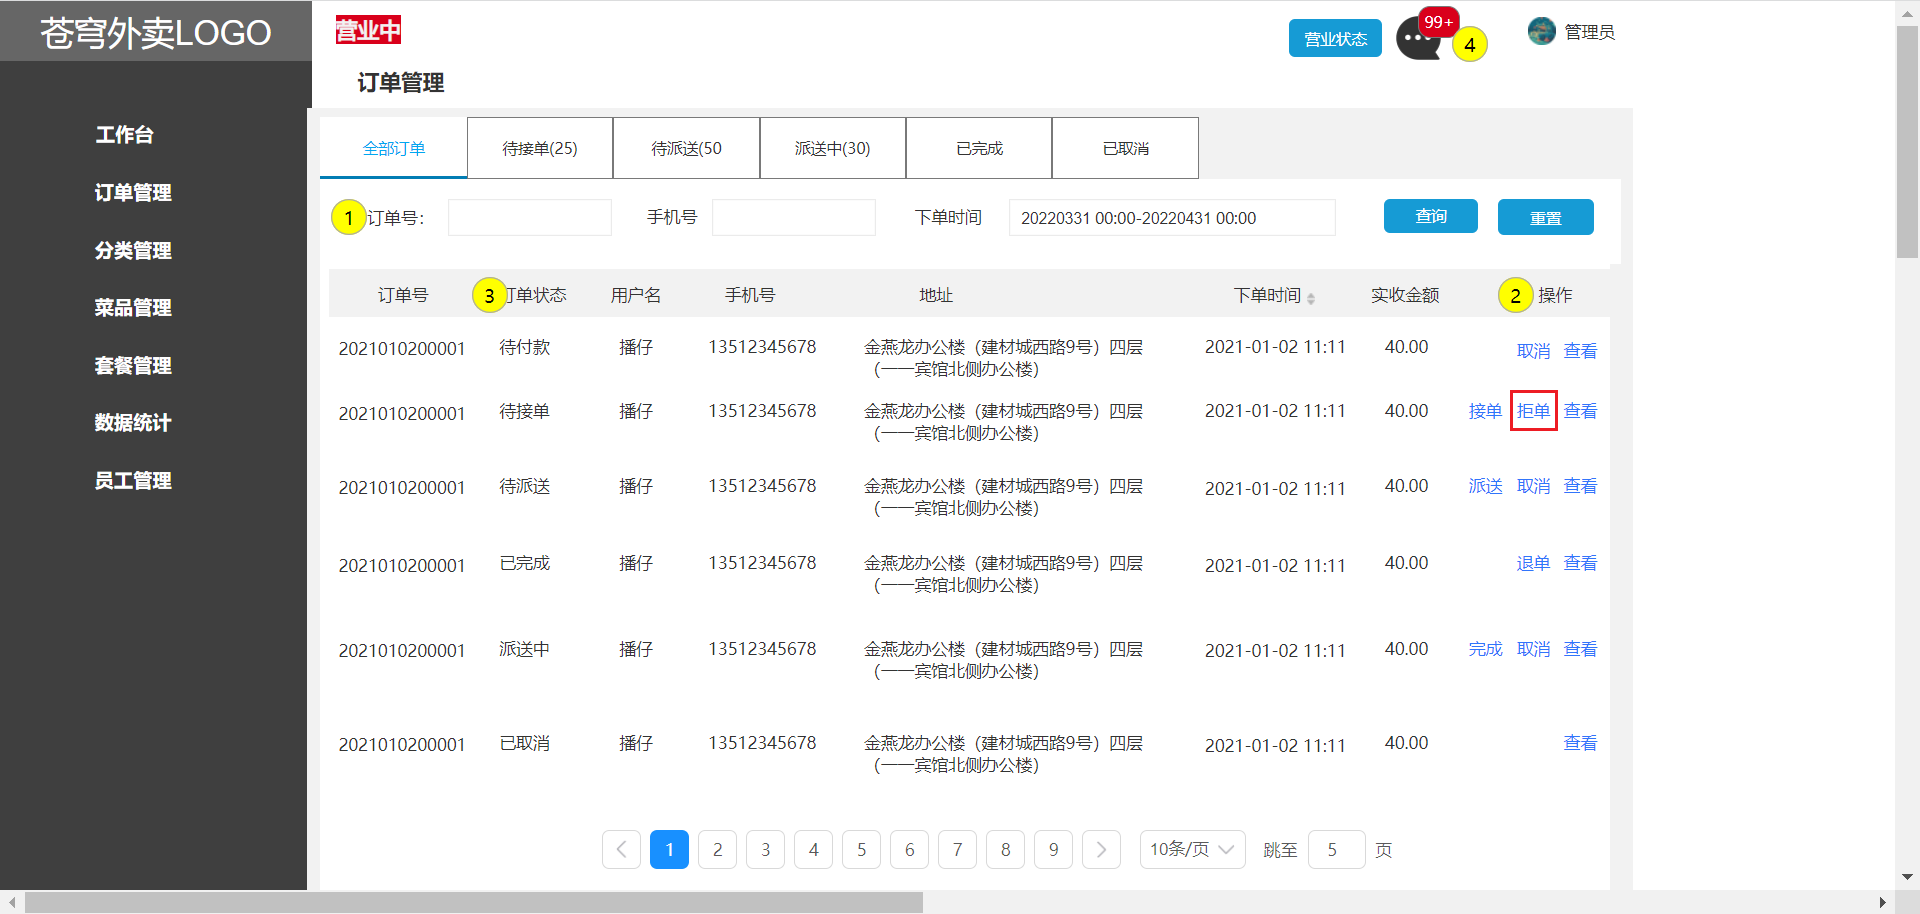

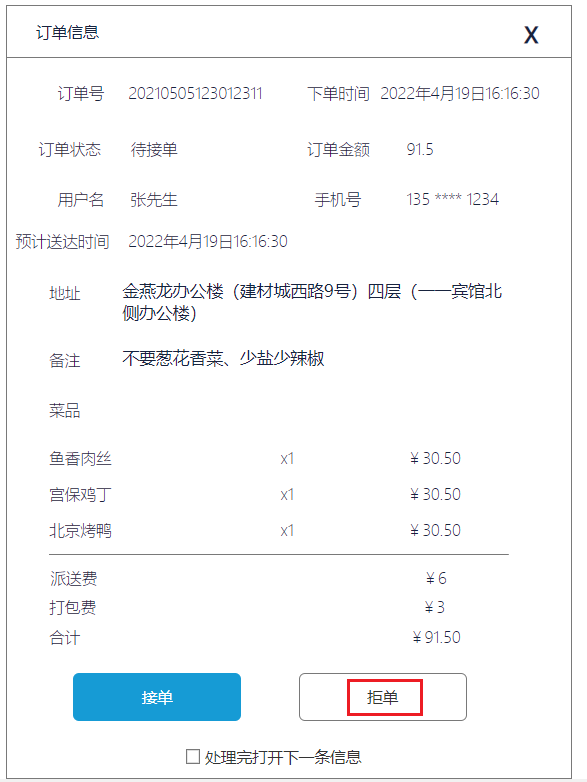

业务规则：

- 商家拒单其实就是将订单状态修改为“已取消”
- 只有订单处于“待接单”状态时可以执行拒单操作
- 商家拒单时需要指定拒单原因
- 商家拒单时，如果用户已经完成了支付，需要为用户退款

接口设计：参见接口文档

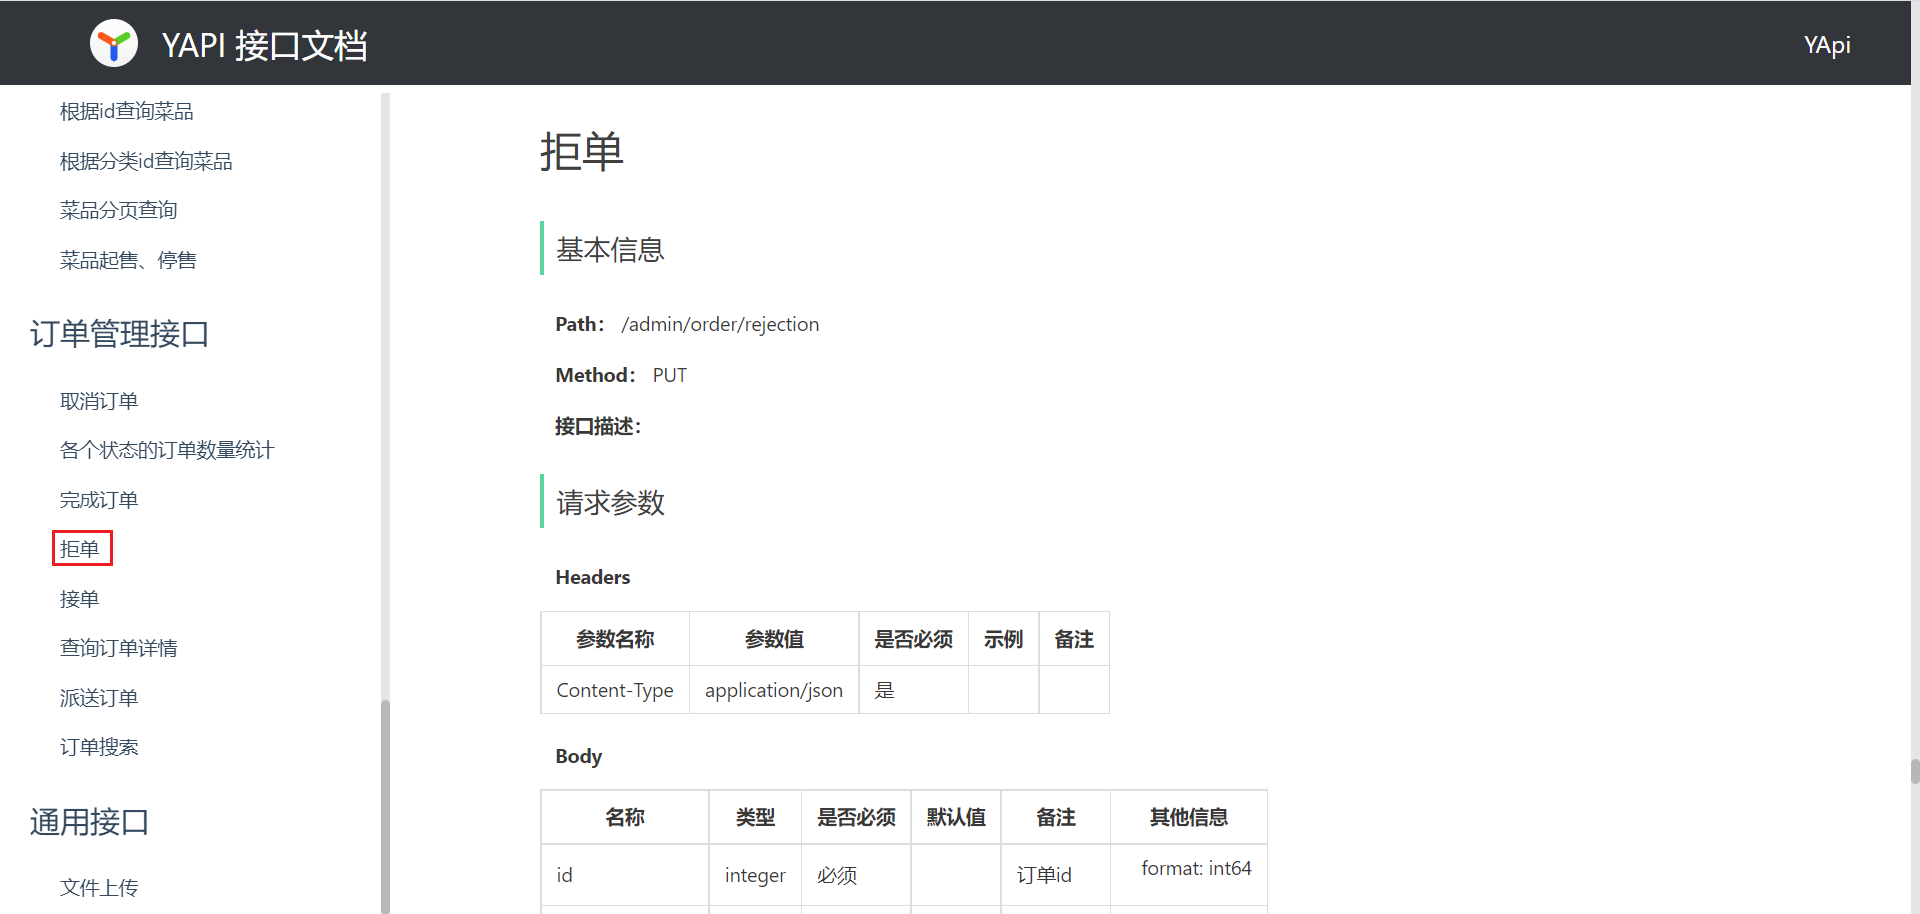


### 拒单与退款是两个动作（补充）

拒单必须保存原因和取消时间；是否退款由支付状态决定。退款申请成功、失败、处理中需要可追踪，不能只打印一行日志后把订单当作全部完成。


### 5.2 代码实现

#### 5.2.1 admin/OrderController

~~~java
    /**
     * 拒单
     *
     * @return
     */
    @PutMapping("/rejection")
    @ApiOperation("拒单")
    public Result rejection(@RequestBody OrdersRejectionDTO ordersRejectionDTO) throws Exception {
        orderService.rejection(ordersRejectionDTO);
        return Result.success();
    }
~~~

#### 5.2.2 OrderService

~~~java
    /**
     * 拒单
     *
     * @param ordersRejectionDTO
     */
    void rejection(OrdersRejectionDTO ordersRejectionDTO) throws Exception;
~~~

#### 5.2.3 OrderServiceImpl

~~~java
	/**
     * 拒单
     *
     * @param ordersRejectionDTO
     */
    public void rejection(OrdersRejectionDTO ordersRejectionDTO) throws Exception {
        // 根据id查询订单
        Orders ordersDB = orderMapper.getById(ordersRejectionDTO.getId());

        // 订单只有存在且状态为2（待接单）才可以拒单
        if (ordersDB == null || !ordersDB.getStatus().equals(Orders.TO_BE_CONFIRMED)) {
            throw new OrderBusinessException(MessageConstant.ORDER_STATUS_ERROR);
        }

        //支付状态
        Integer payStatus = ordersDB.getPayStatus();
        if (payStatus == Orders.PAID) {
            //用户已支付，需要退款
            String refund = weChatPayUtil.refund(
                    ordersDB.getNumber(),
                    ordersDB.getNumber(),
                    new BigDecimal(0.01),
                    new BigDecimal(0.01));
            log.info("申请退款：{}", refund);
        }

        // 拒单需要退款，根据订单id更新订单状态、拒单原因、取消时间
        Orders orders = new Orders();
        orders.setId(ordersDB.getId());
        orders.setStatus(Orders.CANCELLED);
        orders.setRejectionReason(ordersRejectionDTO.getRejectionReason());
        orders.setCancelTime(LocalDateTime.now());

        orderMapper.update(orders);
    }
~~~


### 拒单的退款金额和状态迁移（勘误）

原代码同样固定退款 0.01 元，并且在远程退款结果未知时直接更新本地订单。应从订单读取实际支付金额，使用唯一退款单号和退款记录；只有订单仍为待接单时才允许拒单。支付状态更新应明确为退款中/已退款，按工程枚举与对账机制落库。

拒单接口的 `rejectionReason` 必须限制长度并记录操作人、时间。重复提交不能再次发起退款。


### 5.3 功能测试

略


### 拒单验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 未支付待接单拒单 | 取消并保存原因，不调用退款 |
| 已支付待接单拒单 | 按实际金额发起一次退款并可追踪 |
| 已接单拒单 | 拒绝 |
| 重复拒单 | 不重复退款 |
| 原因为空或超长 | 参数校验失败 |


## 6. 取消订单


### 6.1 需求分析和设计

产品原型：

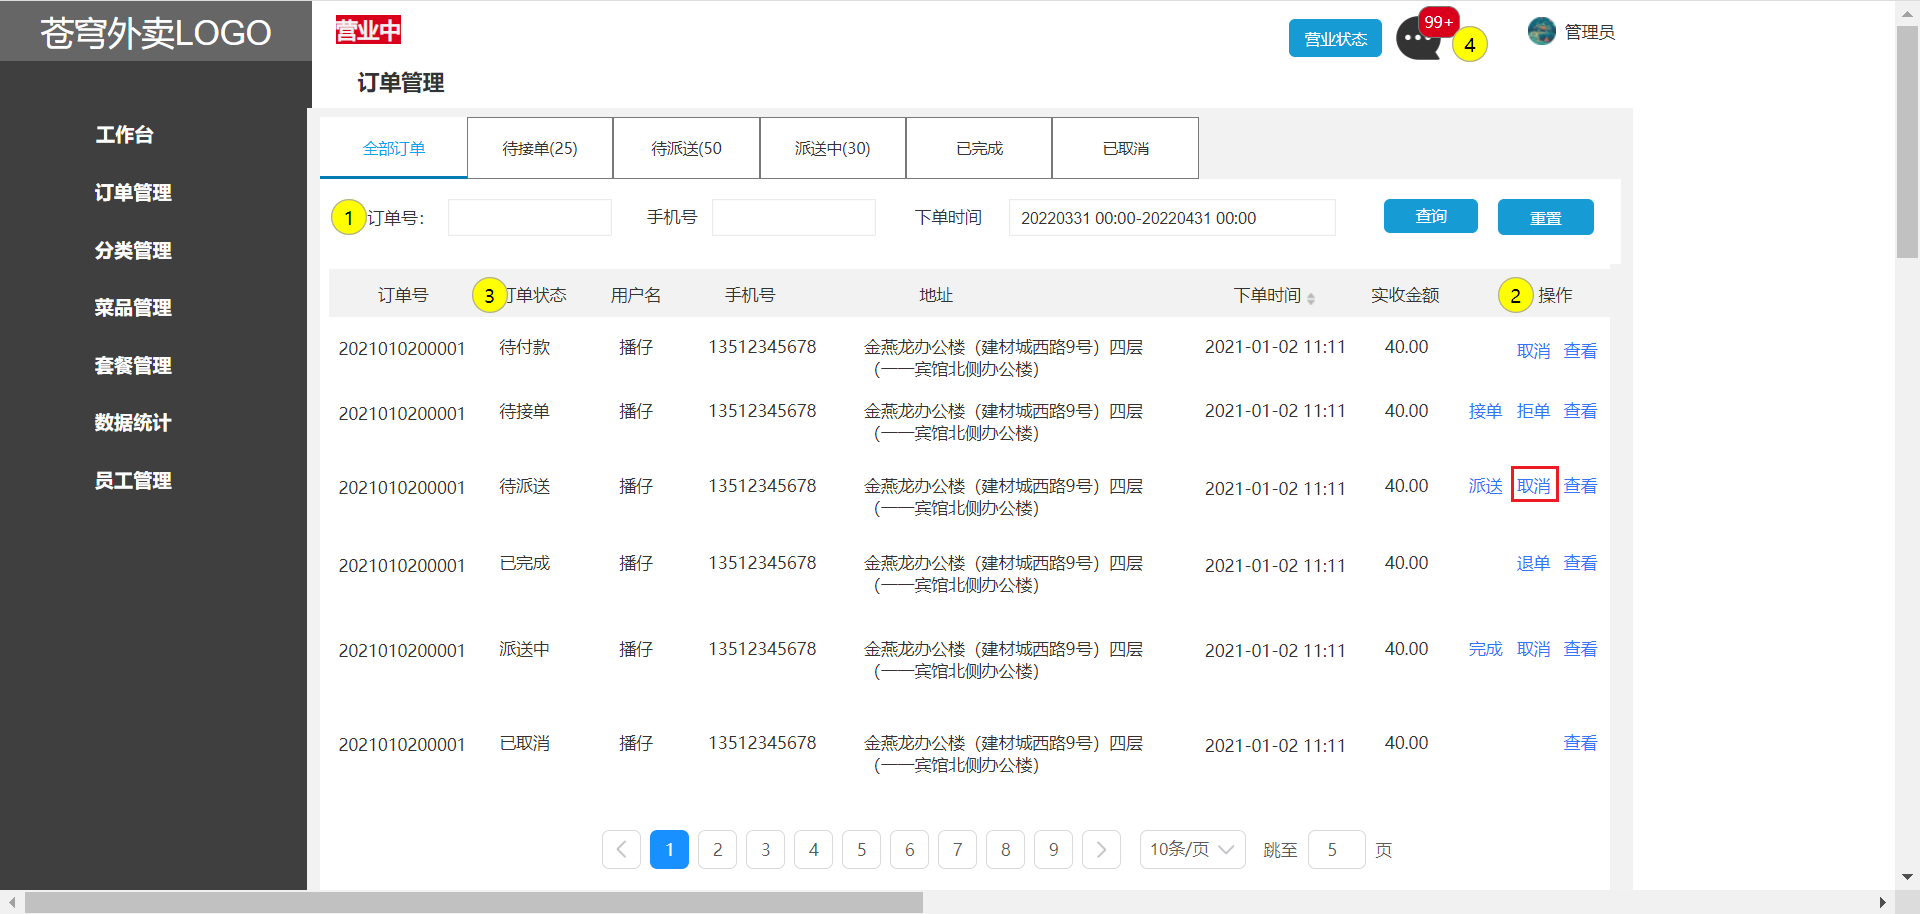


业务规则：

- 取消订单其实就是将订单状态修改为“已取消”
- 商家取消订单时需要指定取消原因
- 商家取消订单时，如果用户已经完成了支付，需要为用户退款

接口设计：参见接口文档

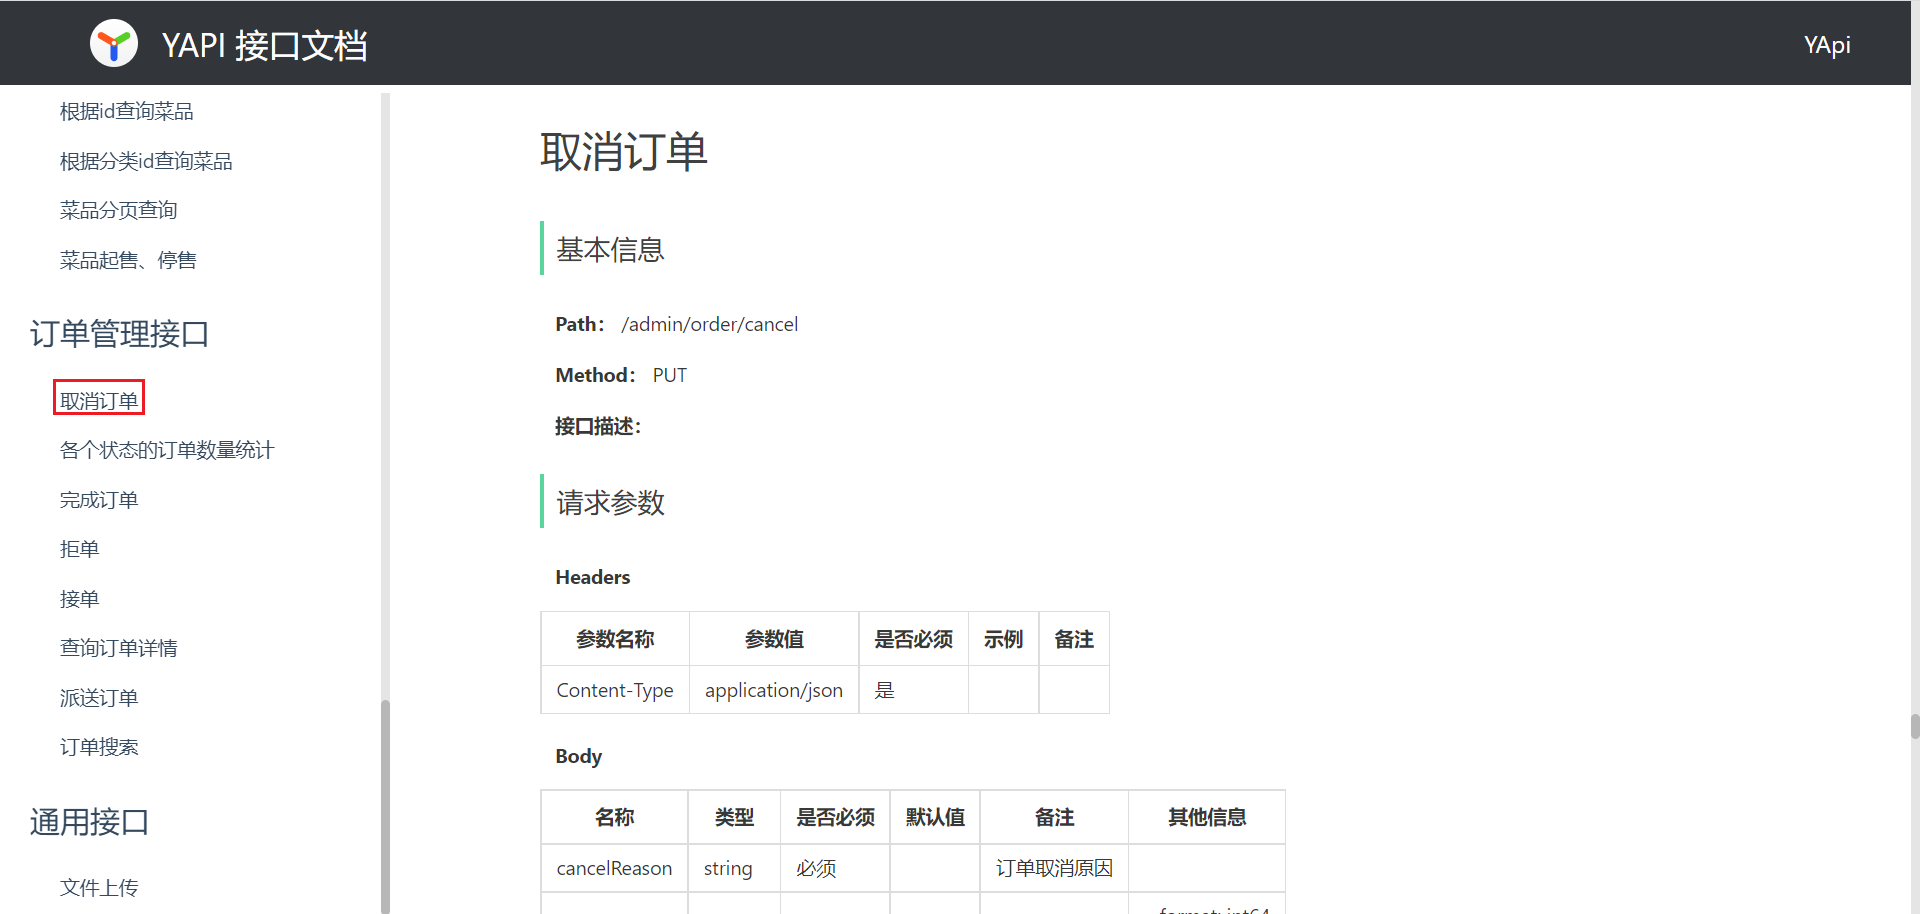


### 商家取消的业务边界（补充）

商家取消要记录取消原因。接单后取消和待接单拒单可能共享退款能力，但接口语义、可取消状态和审计信息要分开定义，不能由前端任意传状态覆盖。


### 6.2 代码实现

#### 6.2.1 admin/OrderController

~~~java
    /**
     * 取消订单
     *
     * @return
     */
    @PutMapping("/cancel")
    @ApiOperation("取消订单")
    public Result cancel(@RequestBody OrdersCancelDTO ordersCancelDTO) throws Exception {
        orderService.cancel(ordersCancelDTO);
        return Result.success();
    }
~~~

#### 6.2.2 OrderService

~~~java
    /**
     * 商家取消订单
     *
     * @param ordersCancelDTO
     */
    void cancel(OrdersCancelDTO ordersCancelDTO) throws Exception;
~~~

#### 6.2.3 OrderServiceImpl

~~~java
	/**
     * 取消订单
     *
     * @param ordersCancelDTO
     */
    public void cancel(OrdersCancelDTO ordersCancelDTO) throws Exception {
        // 根据id查询订单
        Orders ordersDB = orderMapper.getById(ordersCancelDTO.getId());

        //支付状态
        Integer payStatus = ordersDB.getPayStatus();
        if (payStatus == 1) {
            //用户已支付，需要退款
            String refund = weChatPayUtil.refund(
                    ordersDB.getNumber(),
                    ordersDB.getNumber(),
                    new BigDecimal(0.01),
                    new BigDecimal(0.01));
            log.info("申请退款：{}", refund);
        }

        // 管理端取消订单需要退款，根据订单id更新订单状态、取消原因、取消时间
        Orders orders = new Orders();
        orders.setId(ordersCancelDTO.getId());
        orders.setStatus(Orders.CANCELLED);
        orders.setCancelReason(ordersCancelDTO.getCancelReason());
        orders.setCancelTime(LocalDateTime.now());
        orderMapper.update(orders);
    }
~~~


### 商家取消仍需前置状态与支付校验（勘误）

原商家取消方法查单后立即读取payStatus，不存在订单会空指针；没有前置状态白名单，会取消已完成订单。应先校验存在性、原因、允许状态，并按pay_status决定退款。资料只说明“取消需原因、支付需退款”，未列全部允许状态，项目应另行明确，至少禁止覆盖已完成/已取消；派送中转人工协调。

原方法也固定0.01元，且退款后未更新payStatus。使用退款记录和条件更新，本地取消与退款申请的结果都需可追踪。


### 6.3 功能测试

略


### 商家取消验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 可取消状态取消 | 保存原因、取消时间，状态正确 |
| 已完成订单取消 | 拒绝 |
| 已支付订单取消 | 退款金额正确且可追踪 |
| 并发接单与取消 | 只有一个状态迁移成功 |
| 重复提交 | 幂等，不重复退款 |


## 7. 派送订单


### 7.1 需求分析和设计

产品原型：

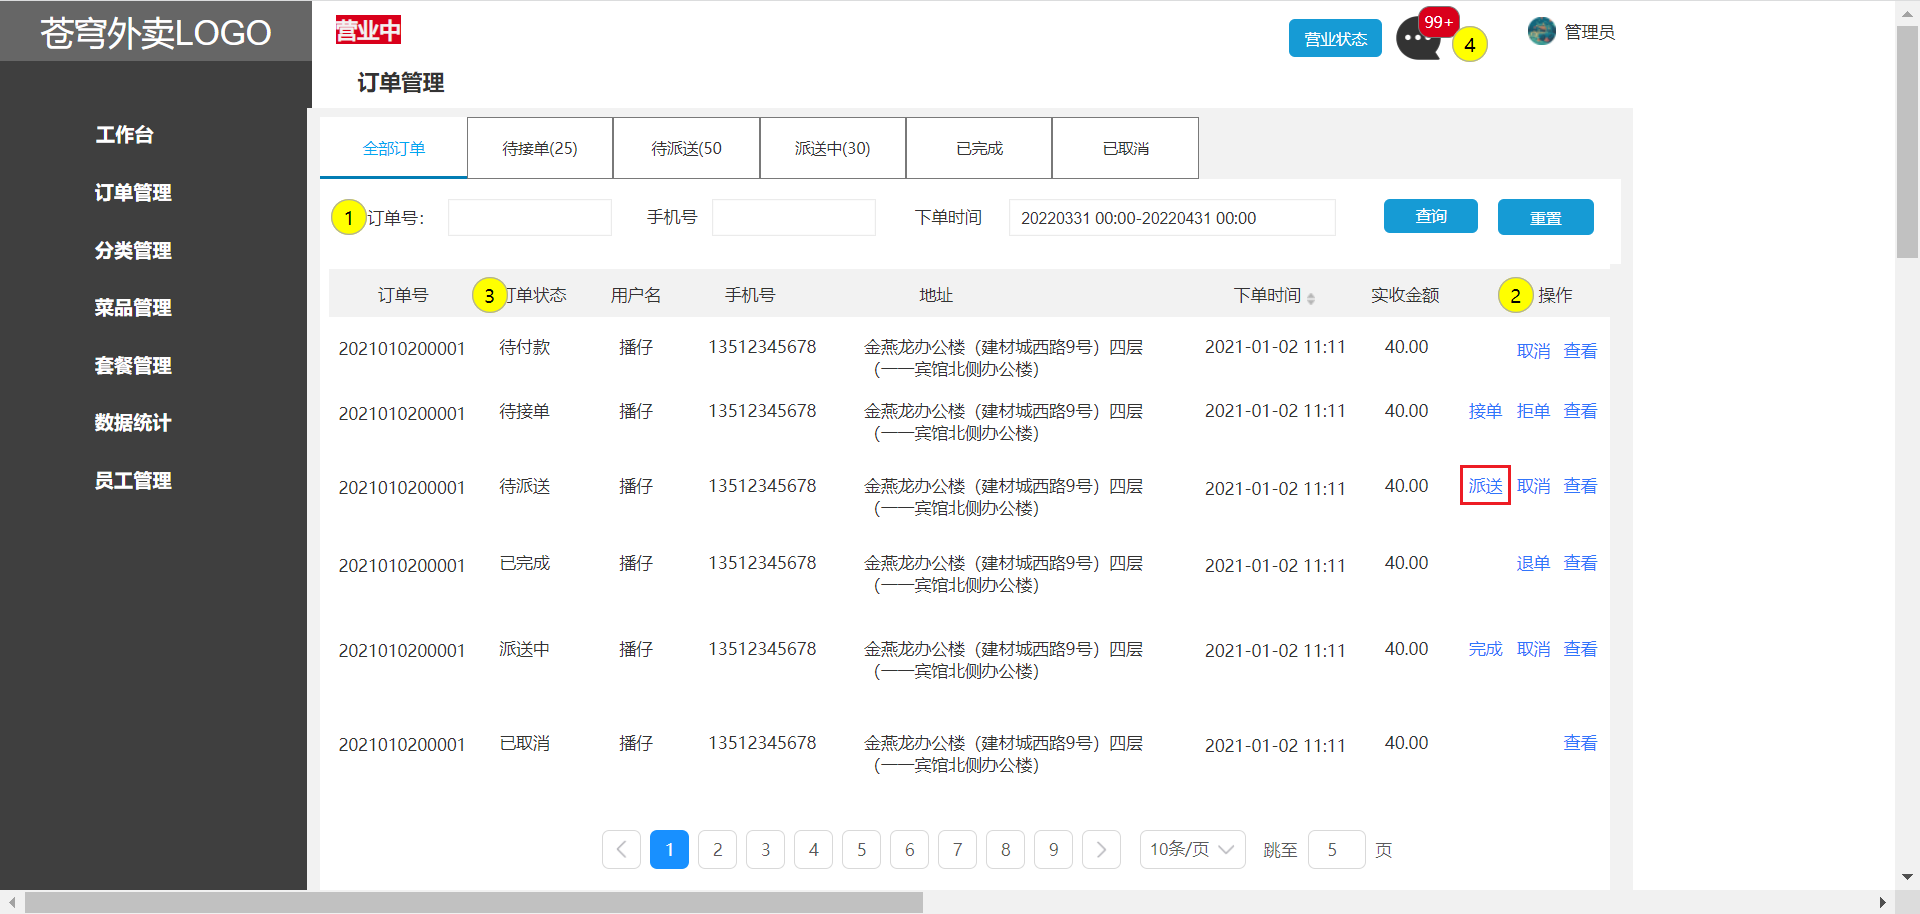


业务规则：

- 派送订单其实就是将订单状态修改为“派送中”
- 只有状态为“待派送”的订单可以执行派送订单操作

接口设计：参见接口文档

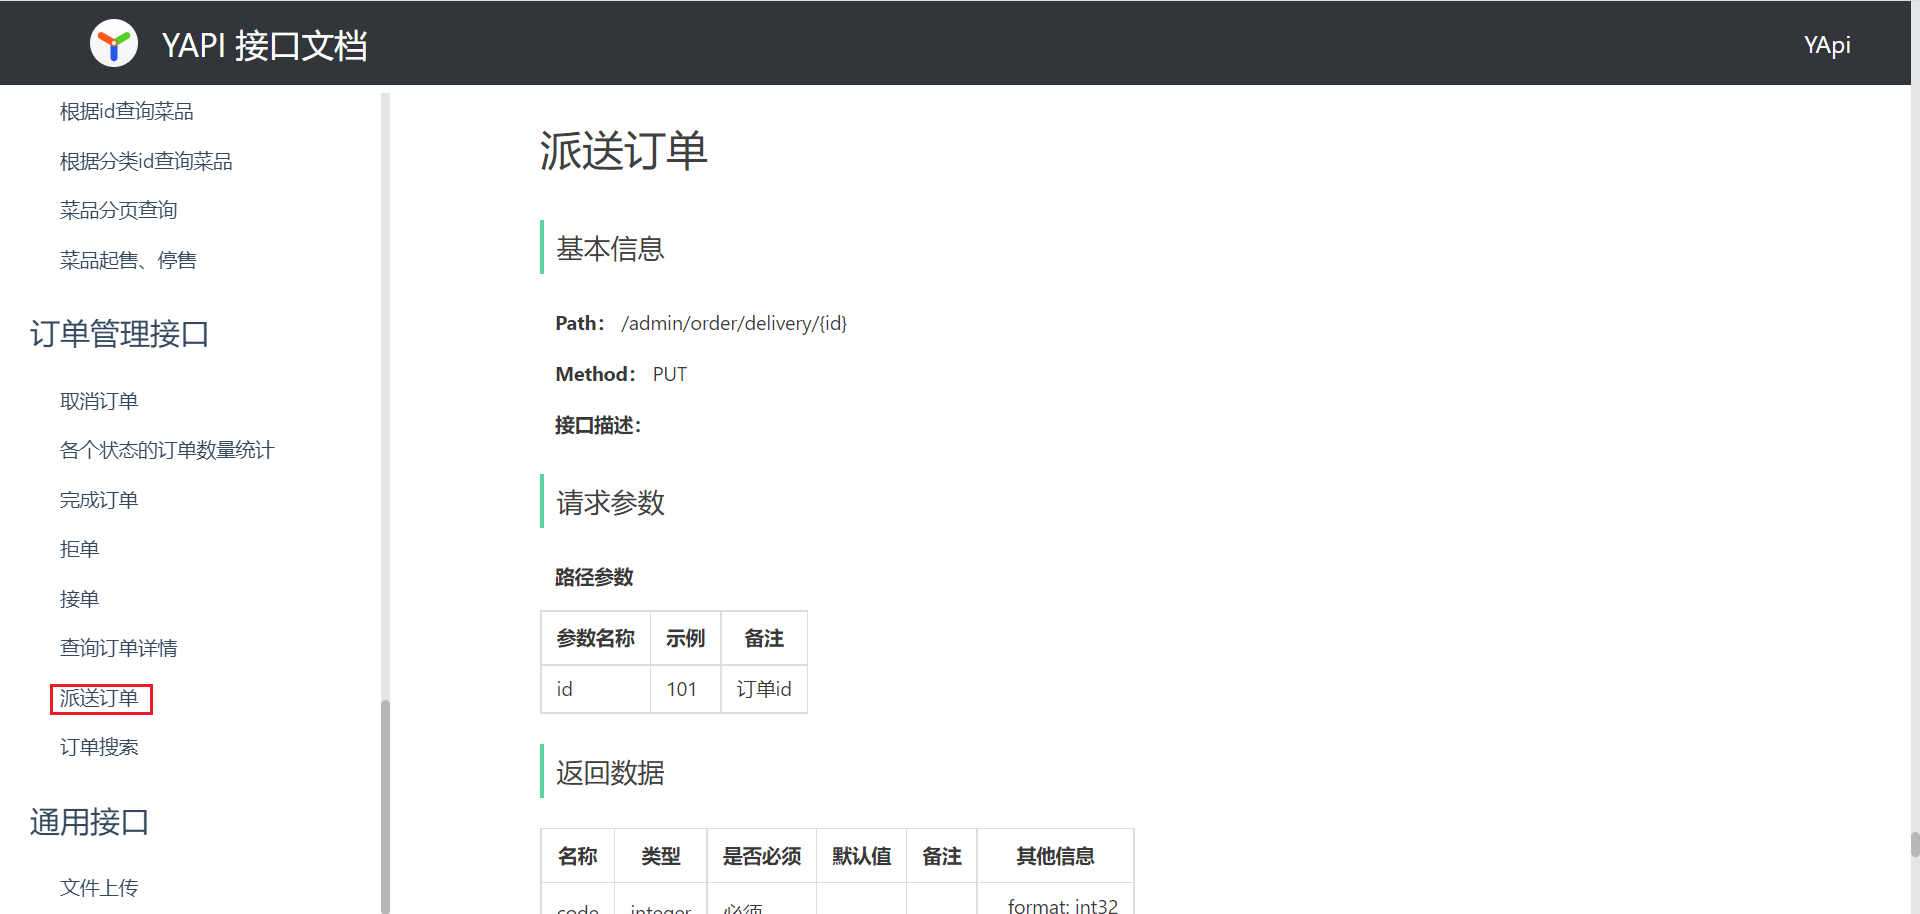


### 派送只接受已接单（补充）

派送按钮对应 `已接单(3) → 派送中(4)`，应写入配送时间或预计送达时间（如果表有字段），不能让待接单订单直接进入派送中。


### 7.2 代码实现

#### 7.2.1 admin/OrderController

~~~java
    /**
     * 派送订单
     *
     * @return
     */
    @PutMapping("/delivery/{id}")
    @ApiOperation("派送订单")
    public Result delivery(@PathVariable("id") Long id) {
        orderService.delivery(id);
        return Result.success();
    }
~~~

#### 7.2.2 OrderService

~~~java
    /**
     * 派送订单
     *
     * @param id
     */
    void delivery(Long id);
~~~

#### 7.2.3 OrderServiceImpl

~~~java
    /**
     * 派送订单
     *
     * @param id
     */
    public void delivery(Long id) {
        // 根据id查询订单
        Orders ordersDB = orderMapper.getById(id);

        // 校验订单是否存在，并且状态为3
        if (ordersDB == null || !ordersDB.getStatus().equals(Orders.CONFIRMED)) {
            throw new OrderBusinessException(MessageConstant.ORDER_STATUS_ERROR);
        }

        Orders orders = new Orders();
        orders.setId(ordersDB.getId());
        // 更新订单状态,状态转为派送中
        orders.setStatus(Orders.DELIVERY_IN_PROGRESS);

        orderMapper.update(orders);
    }
~~~


### 派送条件更新（勘误）

原代码先检查订单存在、status=3，这是必要检查，但检查与随后update之间有并发窗口。最终SQL仍使用 `where id=? and status=3` 并检查影响行数；重复派送不能覆盖已完成或已取消。原示例只改status，没有写派送开始时间，新增字段应同步设计。


### 7.3 功能测试

略


### 派送验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 已接单派送 | 进入派送中；若扩展派送时间字段，检查写入 |
| 待接单派送 | 拒绝 |
| 重复派送 | 幂等，不修改后续状态 |
| 并发派送/完成 | 状态按前置条件串行 |


## 8. 完成订单


### 8.1 需求分析和设计

产品原型：

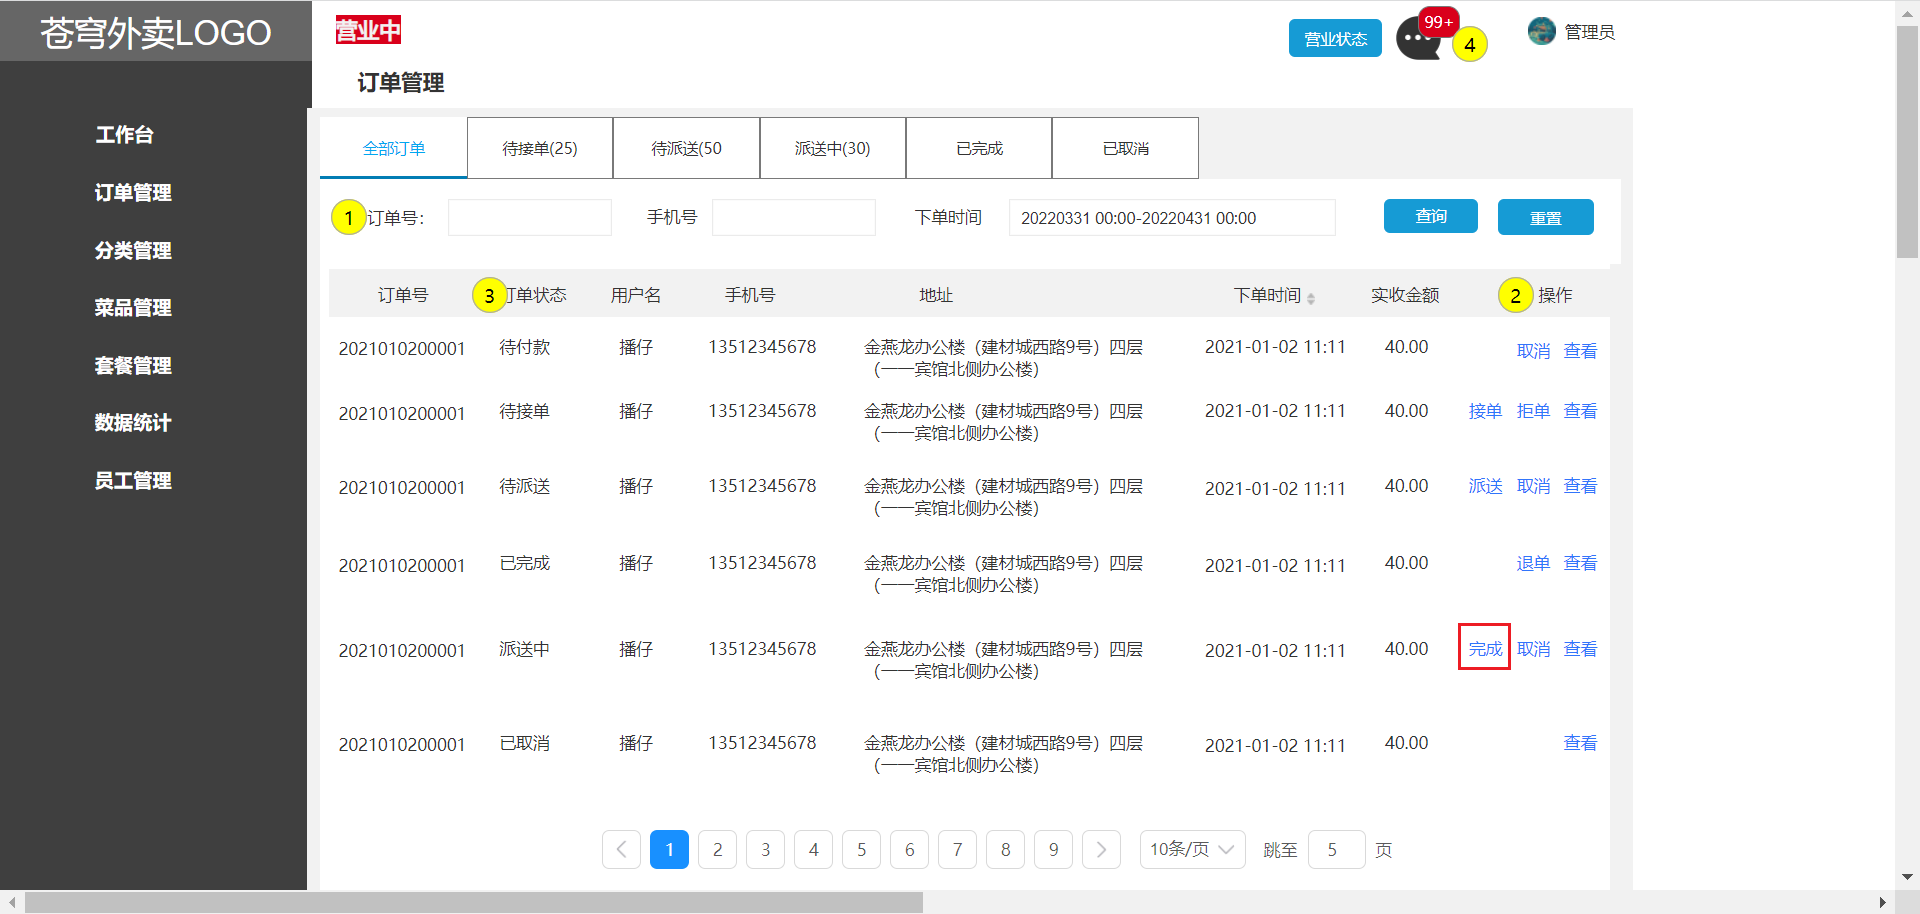


业务规则：

- 完成订单其实就是将订单状态修改为“已完成”
- 只有状态为“派送中”的订单可以执行订单完成操作

接口设计：参见接口文档

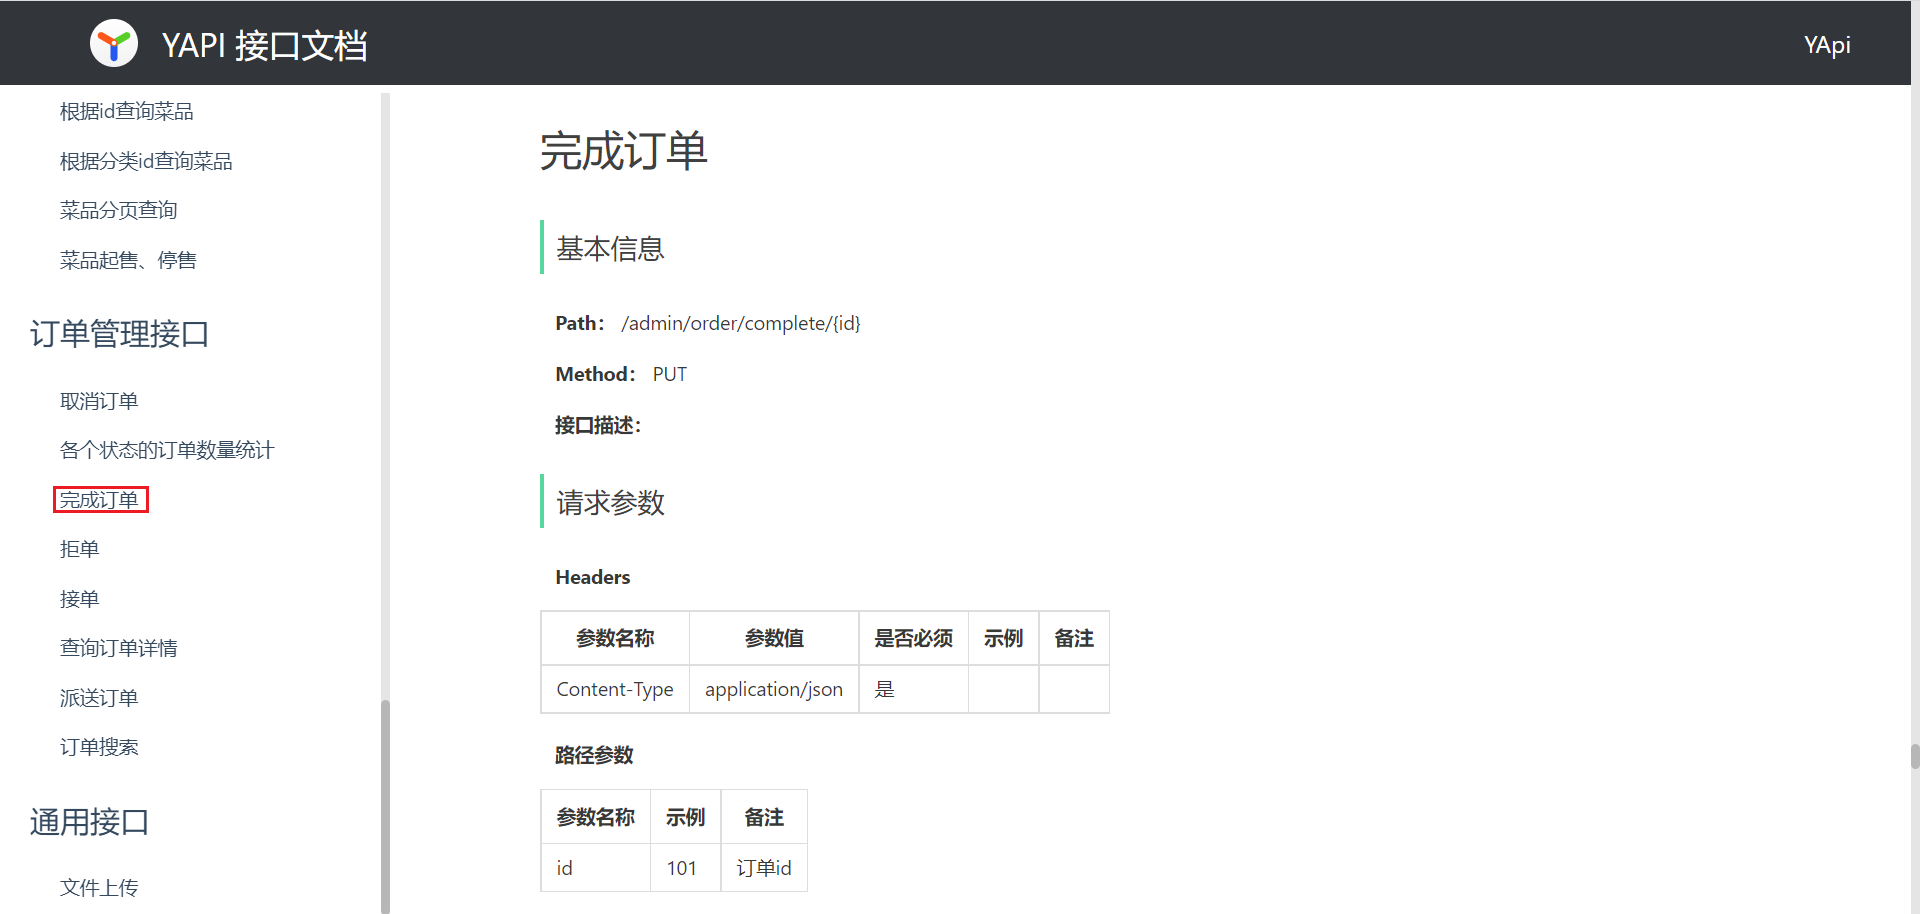


### 完成订单的最后状态迁移（补充）

完成按钮只允许 `派送中(4) → 已完成(5)`。已完成订单是统计有效订单、营业额和用户历史状态的重要依据，完成时间应由服务端产生。


### 8.2 代码实现

#### 8.2.1 admin/OrderController

~~~java
    /**
     * 完成订单
     *
     * @return
     */
    @PutMapping("/complete/{id}")
    @ApiOperation("完成订单")
    public Result complete(@PathVariable("id") Long id) {
        orderService.complete(id);
        return Result.success();
    }
~~~

#### 8.2.2 OrderService

~~~java
    /**
     * 完成订单
     *
     * @param id
     */
    void complete(Long id);
~~~

#### 8.2.3 OrderServiceImpl

~~~java
    /**
     * 完成订单
     *
     * @param id
     */
    public void complete(Long id) {
        // 根据id查询订单
        Orders ordersDB = orderMapper.getById(id);

        // 校验订单是否存在，并且状态为4
        if (ordersDB == null || !ordersDB.getStatus().equals(Orders.DELIVERY_IN_PROGRESS)) {
            throw new OrderBusinessException(MessageConstant.ORDER_STATUS_ERROR);
        }

        Orders orders = new Orders();
        orders.setId(ordersDB.getId());
        // 更新订单状态,状态转为完成
        orders.setStatus(Orders.COMPLETED);
        orders.setDeliveryTime(LocalDateTime.now());

        orderMapper.update(orders);
    }
~~~


### 完成订单条件和审计（勘误）

原代码已检查status=4并设置`deliveryTime(LocalDateTime.now())`，课程把该字段作为实际送达时间。补充重点在最终SQL条件`where id=? and status=4`和影响行数；防止检查后状态已被其他线程改动。订单完成后不能再被接单、派送或取消接口覆盖，也不应因重复完成而重新写送达时间。


### 8.3 功能测试

略


### 完成验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 派送中完成 | 状态为已完成，完成时间存在 |
| 已完成重复完成 | 幂等，不更新时间倒退 |
| 待接单/已接单完成 | 拒绝 |
| 完成后统计 | 订单不再出现在待处理数量中 |


# 校验收货地址是否超出配送范围


## 1. 环境准备

注册账号：https://passport.baidu.com/v2/?reg&tt=1671699340600&overseas=&gid=CF954C2-A3D2-417F-9FE6-B0F249ED7E33&tpl=pp&u=https%3A%2F%2Flbsyun.baidu.com%2Findex.php%3Ftitle%3D%E9%A6%96%E9%A1%B5

登录百度地图开放平台：https://lbsyun.baidu.com/

进入控制台，创建应用，获取AK：

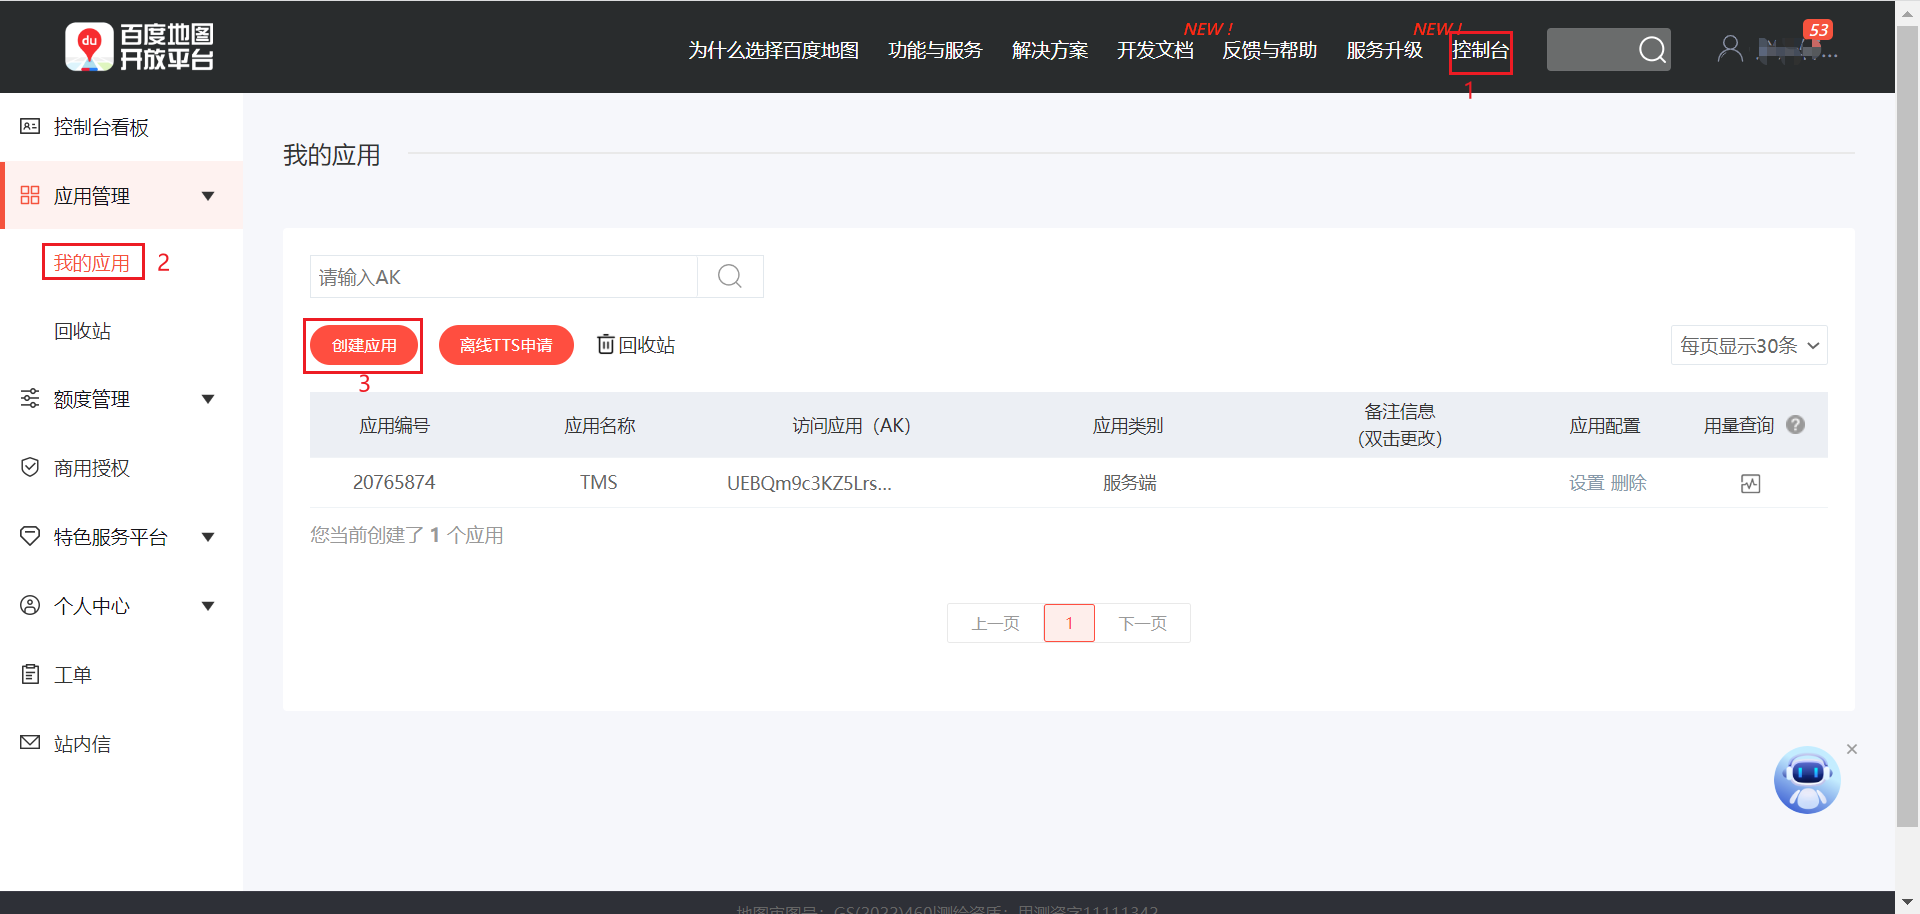


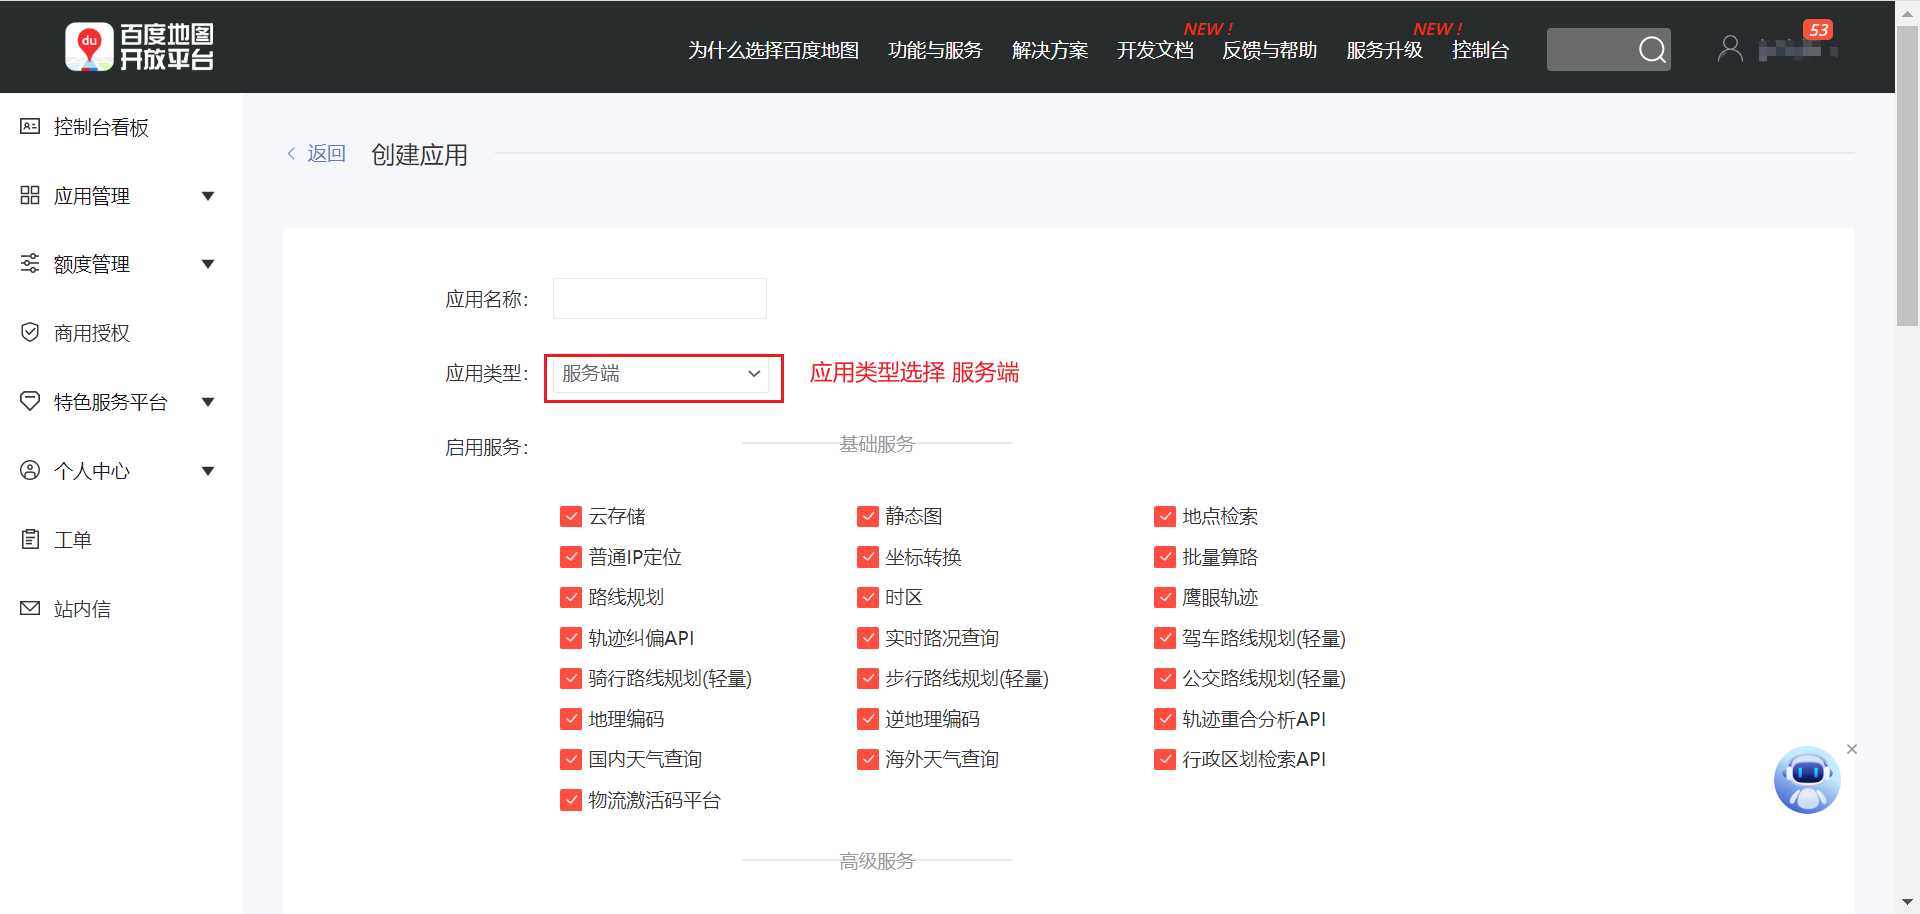

相关接口:

https://lbsyun.baidu.com/index.php?title=webapi/guide/webservice-geocoding

https://lbsyun.baidu.com/index.php?title=webapi/directionlite-v1


### 百度地图配置安全（补充）

百度地图 AK 应使用环境变量或配置中心注入，不能提交到公开仓库。店铺地址、AK、请求超时和允许最大距离都应可配置；课程要求的配送范围是 5 公里，即路线距离 `<= 5000` 米才允许下单。

接口文档中的地理编码和驾车路线接口是外部依赖，必须设置连接/读取超时、错误码处理和降级策略。地图服务不可用时应拒绝下单并提示稍后重试，不能默认放行。


## 2. 代码开发


### 2.1 application.yml

配置外卖商家店铺地址和百度地图的AK：

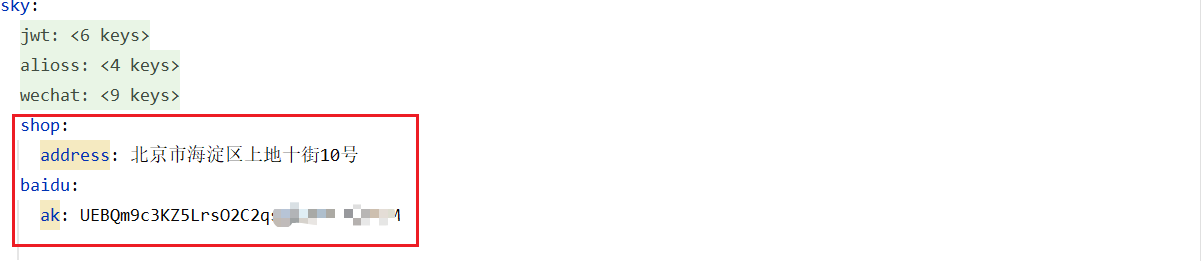


### 配置项校验（补充）

启动时校验 `sky.shop.address`、`sky.baidu.ak` 和最大配送距离是否为空、是否为合法值。截图的AK已部分打码，不是可用账号。可复制的补充配置示例：

```yaml
sky:
  shop:
    address: ${SKY_SHOP_ADDRESS}
  baidu:
    ak: ${BAIDU_MAP_AK}
```

正式环境安全保存AK；若另增最大距离和超时配置，还要新增对应属性和读取逻辑，不能只写YAML就认为已经生效。


### 2.2 OrderServiceImpl

改造OrderServiceImpl，注入上面的配置项：

~~~java
    @Value("${sky.shop.address}")
    private String shopAddress;

    @Value("${sky.baidu.ak}")
    private String ak;
~~~

在OrderServiceImpl中提供校验方法：

~~~java
/**
     * 检查客户的收货地址是否超出配送范围
     * @param address
     */
    private void checkOutOfRange(String address) {
        Map map = new HashMap();
        map.put("address",shopAddress);
        map.put("output","json");
        map.put("ak",ak);

        //获取店铺的经纬度坐标
        String shopCoordinate = HttpClientUtil.doGet("https://api.map.baidu.com/geocoding/v3", map);

        JSONObject jsonObject = JSON.parseObject(shopCoordinate);
        if(!jsonObject.getString("status").equals("0")){
            throw new OrderBusinessException("店铺地址解析失败");
        }

        //数据解析
        JSONObject location = jsonObject.getJSONObject("result").getJSONObject("location");
        String lat = location.getString("lat");
        String lng = location.getString("lng");
        //店铺经纬度坐标
        String shopLngLat = lat + "," + lng;

        map.put("address",address);
        //获取用户收货地址的经纬度坐标
        String userCoordinate = HttpClientUtil.doGet("https://api.map.baidu.com/geocoding/v3", map);

        jsonObject = JSON.parseObject(userCoordinate);
        if(!jsonObject.getString("status").equals("0")){
            throw new OrderBusinessException("收货地址解析失败");
        }

        //数据解析
        location = jsonObject.getJSONObject("result").getJSONObject("location");
        lat = location.getString("lat");
        lng = location.getString("lng");
        //用户收货地址经纬度坐标
        String userLngLat = lat + "," + lng;

        map.put("origin",shopLngLat);
        map.put("destination",userLngLat);
        map.put("steps_info","0");

        //路线规划
        String json = HttpClientUtil.doGet("https://api.map.baidu.com/directionlite/v1/driving", map);

        jsonObject = JSON.parseObject(json);
        if(!jsonObject.getString("status").equals("0")){
            throw new OrderBusinessException("配送路线规划失败");
        }

        //数据解析
        JSONObject result = jsonObject.getJSONObject("result");
        JSONArray jsonArray = (JSONArray) result.get("routes");
        Integer distance = (Integer) ((JSONObject) jsonArray.get(0)).get("distance");

        if(distance > 5000){
            //配送距离超过5000米
            throw new OrderBusinessException("超出配送范围");
        }
    }
~~~

在OrderServiceImpl的submitOrder方法中调用上面的校验方法：

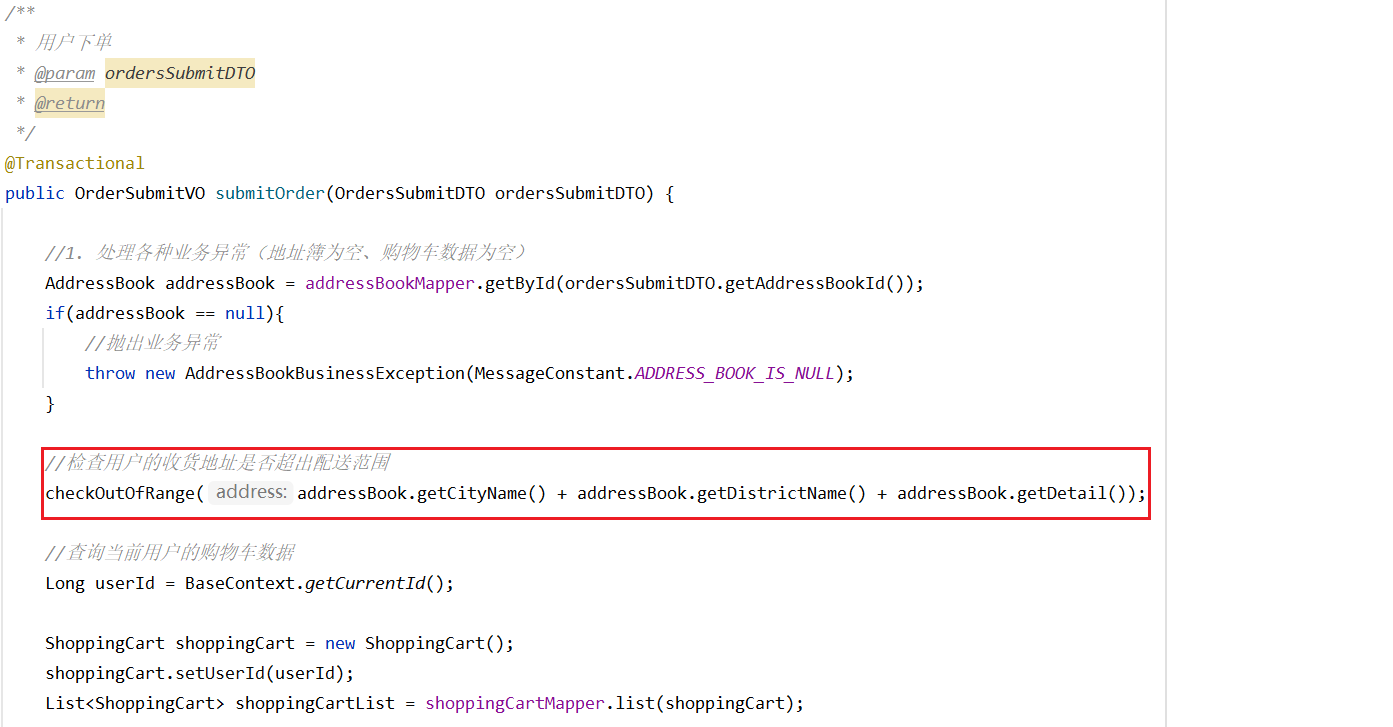


### 地图调用与下单事务（勘误）

原示例依次调用店铺地理编码、用户地理编码和驾车路线。跟练时补充：校验result/location、routes非空、distance字段存在且为非负数；统一捕获HTTP超时、JSON解析和百度错误码，返回可理解的业务异常。原`getString("status").equals("0")`在缺字段时会空指针，可先核对字段再比较。`(Integer)...get("distance")`依赖运行时数值类型，用getLong/getBigDecimal等类型读取并校验单位。

注意坐标顺序：地理编码返回lat/lng，参考代码传给百度路线接口的是`纬度,经度`，不要看到变量名shopLngLat就误改成`经度,纬度`。两个接口须使用兼容的坐标系。驾车路线长度与直线半径不同，按资料的驾车路线方案判断5000米；多条路线也要明确取哪一条，不能忽略路线策略。

原代码复用raw Map，路线请求残留address/output等地理编码参数。建议用`Map<String,String>`分别构建两个端点参数；店铺坐标可在配置更新时刷新缓存，避免每单重复解析固定门店地址。收货地址先确认属于当前用户，使用完整省市区和门牌，字段缺失不能拼成null字符串。

该检查应发生在创建订单之前，并与订单写入保持清晰的失败边界。截图将检查放在已有@Transactional的submitOrder内；外部地图调用不应长时间占用事务连接。可先完成受控超时的校验，再通过另一个代理Bean进入订单事务；同类自调用带@Transactional的方法不会自动启用Spring事务。校验结果绑定本次完整地址，进入写入阶段再核对用户、地址和购物车。

### 配送范围验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 路线距离4999/5000米 | 通过；以课程大于5000才拒绝为边界 |
| 路线距离5001米 | 下单失败，未创建订单、明细，购物车保留 |
| 地址不属于用户或不完整 | 在地图请求之前拒绝 |
| 地理编码失败、routes为空 | 明确失败，不默认当0米 |
| 百度超时、错误JSON、超配额 | 可控业务错误，无半单数据 |
| 门店地址变更 | 固定坐标缓存刷新，按新地址判断 |
| 用户校验后修改地址 | 不使用旧地址的校验结果创建新地址订单 |


## 复习速查与本章验收（补充）

| 主题 | 记忆点 |
| --- | --- |
| 用户隔离 | 用户端订单详情、取消、再来一单都用当前 userId 限定 |
| 订单快照 | 历史地址、商品名称、图片、单价保存在订单/明细中 |
| 退款 | 金额来自已核定订单，退款记录、幂等和对账必须可追踪 |
| 状态机 | 接单2→3、派送3→4、完成4→5，拒单/取消按前置状态处理 |
| 搜索 | 分页、状态、日期、空条件和 N+1 查询都要有边界 |
| 统计 | 明确状态含义，空结果返回0 |
| 再来一单 | 先校验归属和当前可售，再按当前规则合并购物车 |
| 配送范围 | 三次百度调用有超时和错误处理，路线距离不得超过5000米 |

### 总验收清单

- [ ] 用户历史订单只返回当前用户，详情/取消/再来一单不能越权。
- [ ] 取消、拒单、商家取消按支付状态处理退款，金额不是固定测试值。
- [ ] 接单、派送、完成、取消和拒单都校验前置状态并检查影响行数。
- [ ] 重复点击不会重复退款、重复写购物车或把订单状态回退。
- [ ] 搜索参数和时间范围经过服务端校验，明细查询没有无界 N+1。
- [ ] 状态统计的三个字段与页面定义一致，空数据为0。
- [ ] 百度地图 AK 安全存储，地理编码和路线接口设置超时，超出5公里拒绝下单。
- [ ] Swagger、前后端联调和失败路径均有记录；没有真实支付或退款条件时使用隔离替身并明确标记为模拟。

### 自测问题

1. 为什么用户端订单详情不能只按 id 查询？
2. 待付款取消和已支付待接单取消的退款路径有什么不同？
3. 为什么唯一订单号不能单独解决重复提交？
4. 接单、派送和完成分别允许哪些前置状态？
5. 商家拒单时为什么要同时保存原因、退款状态和取消时间？
6. 订单搜索逐单查询明细会产生什么性能问题？
7. 为什么“再来一单”不能直接复制历史价格和停售商品？
8. 百度地图返回路线为空或超时时，服务端应该怎样处理？
9. 条件更新的影响行数如何帮助实现幂等？
10. 为什么地图校验最好在订单事务写入前完成？
